# Analisis Persona Gender, Religion, dan Regional Cultural pada GSM8K — Enam Model Utama

**Versi publikasi/skripsi: accuracy, paired effect size, significance value, dan token**

Notebook ini hanya menggunakan enam model utama:

1. Qwen3 Next 80B-A3B Thinking
2. Llama 3.1 8B Instruct
3. Ministral 8B
4. DeepSeek R1-Distill Qwen 32B
5. GPT-OSS 20B
6. Llama 3.3 70B Instruct

Seluruh analisis inferensial memakai outcome benar/salah tingkat `question_id`, bukan hanya
jumlah benar agregat. Karena pertanyaan GSM8K yang sama digunakan pada setiap kondisi,
data diperlakukan sebagai **paired observations**.

## Posisi metodologis

- Repeated conditions yang protokolnya sebanding diperiksa dengan **Cochran's Q**.
- Perbandingan dua kondisi memakai **two-sided Exact McNemar**.
- Family-wise adjusted p-value memakai **Holm correction**.
- Arah dan besar perubahan dilaporkan sebagai paired risk difference, 95% paired bootstrap
  confidence interval (10.000 replicates), Cohen's h, discordant-pair counts, dan matched odds ratio.
- `Gender` memakai tujuh primary comparisons per identity. `Religion` memakai tiga primary
  comparisons `Implicit - Explicit` per identity; empat perbandingan terhadap shared Gender
  `Neutral` tetap dihitung sebagai sensitivity analysis karena run date dan `max_tokens` berbeda.
  Matched cross-identity comparisons disimpan sebagai exploratory analysis dalam family terpisah.
- `Regional Cultural` hanya memakai tiga `Implicit - Explicit` comparisons per region karena
  tidak tersedia matching `Neutral` run dengan inference protocol yang sama.

Nama persona dan statistical method dipertahankan dalam bahasa Inggris. Bahasa Indonesia
hanya digunakan pada judul, caption, serta penjelasan hasil.

## Dasar desain visual

Paket visual mempertahankan urutan notebook v4: absolute accuracy, delta, effect size,
significance value, kemudian token. Heatmap p-value meniru bentuk referensi lokal, tetapi
nilai statistiknya berasal dari paired tests yang sesuai dengan rancangan eksperimen.


In [1]:
from __future__ import annotations

import csv
import hashlib
import itertools
import math
import textwrap
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from scipy.stats import binomtest, chi2, spearmanr

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 160)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

EXPECTED_GSM8K_N = 1_319
BOOTSTRAP_REPLICATES = 10_000

def find_repo_root(start: Path | None = None) -> Path:
    candidate = Path(start or Path.cwd()).resolve()
    for path in [candidate, *candidate.parents]:
        if (path / "result" / "GMS8K").exists() and (path / "docs").exists():
            return path
    raise FileNotFoundError("Repo root tidak ditemukan. Jalankan dari D:/TugasAkhir atau subfoldernya.")

REPO_ROOT = find_repo_root()
REPORT_ROOT = REPO_ROOT / "result" / "GMS8K" / "reports"
LEGACY_GENDER_REPORT_ROOT = REPO_ROOT / "result" / "reports"
GENDER_CSV = REPORT_ROOT / "akurasi gender&neutral persona.csv"
RELIGION_CSV = REPORT_ROOT / "akurasi religion persona.csv"
RELIGION_REPORT_ROOT = REPORT_ROOT / "Religion_Persona"
REGIONAL_REPORT_ROOT = REPORT_ROOT / "Regional_Cultural_Persona"
OUTPUT_ROOT = REPORT_ROOT / "persona_publication_analysis_v5_paired_significance_six_models"
TABLE_DIR = OUTPUT_ROOT / "tables"
FIGURE_DIR = OUTPUT_ROOT / "figures"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# v5 is generated exclusively by this notebook. v4 and every earlier output stay untouched.
for previous_figure in [*FIGURE_DIR.glob("*.png"), *FIGURE_DIR.glob("*.svg")]:
    previous_figure.unlink()

MODEL_ORDER = [
    "qwen_qwen3-next-80b-a3b-thinking",
    "meta-llama_llama-3.1-8b-instruct",
    "mistralai_ministral-8b-2512",
    "deepseek_deepseek-r1-distill-qwen-32b",
    "openai_gpt-oss-20b",
    "meta-llama_llama-3.3-70b-instruct",
]
MODEL_LABELS = {
    "qwen_qwen3-next-80b-a3b-thinking": "Qwen3 Next 80B-A3B",
    "meta-llama_llama-3.1-8b-instruct": "Llama 3.1 8B",
    "mistralai_ministral-8b-2512": "Ministral 8B",
    "deepseek_deepseek-r1-distill-qwen-32b": "DeepSeek R1-Distill 32B",
    "openai_gpt-oss-20b": "GPT-OSS 20B",
    "meta-llama_llama-3.3-70b-instruct": "Llama 3.3 70B",
}
GENDER_MODEL_ALIASES = {
    "Qwen3 Next 80B A3B Thinking": "qwen_qwen3-next-80b-a3b-thinking",
    "Meta Llama 3.1 8B Instruct": "meta-llama_llama-3.1-8b-instruct",
    "Mistral Ministral 8B": "mistralai_ministral-8b-2512",
    "deepseek-r1-distill-qwen-32b": "deepseek_deepseek-r1-distill-qwen-32b",
    "OpenAI GPT-OSS-20B": "openai_gpt-oss-20b",
    "Meta Llama 3.3 70B Instruct": "meta-llama_llama-3.3-70b-instruct",
}
PERSONA_PATTERN = r"^(man|woman|neutral|atheist|christian|islam|jewish|north_american|east_asian|south_asian|sub_saharan_african)(?:_(explicit|implicit)(?:_(\d+))?)?$"

GENDER_PERSONAS = [
    "neutral", "man_explicit_1", "man_implicit_1", "man_implicit_2", "man_implicit_3",
    "woman_explicit_1", "woman_implicit_1", "woman_implicit_2", "woman_implicit_3",
]
RELIGION_IDENTITIES = ["atheist", "christian", "islam", "jewish"]
RELIGION_PERSONAS = [
    f"{identity}_{framing}{suffix}"
    for identity in RELIGION_IDENTITIES
    for framing, suffix in [
        ("explicit", ""), ("implicit", "_1"), ("implicit", "_2"), ("implicit", "_3")
    ]
]
REGIONAL_IDENTITIES = [
    "north_american", "east_asian", "south_asian", "sub_saharan_african",
]
REGIONAL_PERSONAS = [
    f"{identity}_{framing}{suffix}"
    for identity in REGIONAL_IDENTITIES
    for framing, suffix in [
        ("explicit", ""), ("implicit", "_1"), ("implicit", "_2"), ("implicit", "_3")
    ]
]

GPT_OSS_GENDER_COMBINED = (
    LEGACY_GENDER_REPORT_ROOT / "openai_gpt-oss-20b" / "results_openai-gpt-oss_20b.csv"
)

def gender_result_path(model: str, persona: str) -> Path:
    direct = LEGACY_GENDER_REPORT_ROOT / model / f"results_{persona}.csv"
    if direct.exists():
        return direct
    if model == "openai_gpt-oss-20b" and persona == "neutral":
        return GPT_OSS_GENDER_COMBINED
    raise FileNotFoundError(f"Gender question-level source tidak ditemukan: {model}/{persona}")

GENDER_RESULT_FILES = {
    (model, persona): gender_result_path(model, persona)
    for model in MODEL_ORDER for persona in GENDER_PERSONAS
}
RELIGION_RESULTS = {
    model: RELIGION_REPORT_ROOT / model / "results.csv" for model in MODEL_ORDER
}
REGIONAL_RESULTS = {
    model: REGIONAL_REPORT_ROOT / model / "results.csv"
    for model in MODEL_ORDER
}

sns.set_theme(context="notebook", style="whitegrid", palette="colorblind", font_scale=1.08)
mpl.rcParams.update({
    "figure.dpi": 90,
    "savefig.dpi": 160,
    "savefig.bbox": "tight",
    "figure.facecolor": "#FCFBF8",
    "axes.facecolor": "#FCFBF8",
    "savefig.facecolor": "#FCFBF8",
    "text.color": "#17212B",
    "axes.labelcolor": "#17212B",
    "axes.edgecolor": "#5A6573",
    "axes.titleweight": "bold",
    "axes.titlesize": 16,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.title_fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.family": "DejaVu Sans",
})

# Bold semantic palette. The same ordered colors are reused by every grouped
# accuracy chart: identity 1 explicit/implicit, identity 2 explicit/implicit,
# identity 3 explicit/implicit, identity 4 explicit/implicit, then Neutral.
ACCURACY_COLORS = [
    "#0047AB", "#0086A8", "#B80F2E", "#E45700",
    "#007A4D", "#65A30D", "#5B21B6", "#A0006D", "#30343B",
]
DELTA_COLORS = ["#0047AB", "#B80F2E", "#007A4D", "#5B21B6"]
GENDER_DELTA_COLORS = ["#0047AB", "#B80F2E", "#5B21B6"]
EFFECT_CMAP = LinearSegmentedColormap.from_list(
    "bold_effect", ["#0047AB", "#B9C2CC", "#FCFBF8", "#D4A6A6", "#B80F2E"]
)
TOKEN_CMAP = LinearSegmentedColormap.from_list(
    "bold_token", ["#161A4A", "#005F73", "#00A896", "#F2B705"]
)
TOKEN_DELTA_CMAP = LinearSegmentedColormap.from_list(
    "bold_token_delta", ["#006D77", "#B8C4C7", "#FCFBF8", "#E4B7A0", "#D14900"]
)
SIGNIFICANCE_CMAP = LinearSegmentedColormap.from_list(
    "bold_significance", ["#3B0A57", "#8E0D4A", "#D52B1E", "#F0D8D2", "#F7F4F0"]
)

MODEL_AXIS_LABELS = {
    "Qwen3 Next 80B-A3B": "Qwen3 Next\n80B-A3B",
    "Llama 3.1 8B": "Llama 3.1\n8B",
    "Ministral 8B": "Ministral\n8B",
    "DeepSeek R1-Distill 32B": "DeepSeek R1-Distill\n32B",
    "GPT-OSS 20B": "GPT-OSS\n20B",
    "Llama 3.3 70B": "Llama 3.3\n70B",
}

def wrapped_label(value: str, width: int = 24) -> str:
    clean = str(value).replace("_", " ")
    if " | " in clean:
        comparison, condition = clean.split(" | ", 1)
        return f"{comparison.replace(' - ', ' vs ')}\n{condition}"
    if " - " in clean:
        left, right = clean.split(" - ", 1)
        return f"{left}\nvs {right}"
    return "\n".join(textwrap.wrap(clean, width=width, break_long_words=False))

COMPACT_IDENTITY_LABELS = {
    "Sub-Saharan African": "SSA",
    "North American": "NA",
    "East Asian": "EA",
    "South Asian": "SA",
    "Christian": "Chr",
    "Atheist": "Ath",
    "Jewish": "Jew",
    "Islam": "Isl",
    "Woman": "W",
    "Man": "M",
}

def compact_persona_label(value: str) -> str:
    clean = str(value).replace("_", " ").strip().title()
    condition_only = {
        "Explicit": "E", "Implicit 1": "I1", "Implicit 2": "I2",
        "Implicit 3": "I3", "Implicit Avg": "I Avg",
    }
    if clean in condition_only:
        return condition_only[clean]
    if clean == "Neutral":
        return "N"
    for identity, abbreviation in COMPACT_IDENTITY_LABELS.items():
        if clean == identity:
            return abbreviation
        if clean.startswith(identity + " "):
            condition = clean[len(identity) + 1:]
            condition = (
                condition.replace("Explicit", "E")
                .replace("Implicit Avg", "I Avg")
                .replace("Implicit 1", "I1")
                .replace("Implicit 2", "I2")
                .replace("Implicit 3", "I3")
            )
            return f"{abbreviation}:{condition}"
    return clean.replace("Explicit", "E").replace("Implicit", "I")

def compact_comparison_label(value: str) -> str:
    clean = str(value).replace("_", " ").strip().title()
    if " | " in clean:
        comparison, condition = clean.split(" | ", 1)
        left, right = comparison.split(" - ", 1)
        return (
            f"{compact_persona_label(left)}–{compact_persona_label(right)}:"
            f"{compact_persona_label(condition)}"
        )
    if " - " not in clean:
        return compact_persona_label(clean)
    left, right = clean.split(" - ", 1)
    left_short = compact_persona_label(left)
    right_short = compact_persona_label(right)
    left_identity = left_short.split(":", 1)[0]
    right_identity = right_short.split(":", 1)[0]
    left_condition = left_short.split(":", 1)[1] if ":" in left_short else ""
    right_condition = right_short.split(":", 1)[1] if ":" in right_short else ""
    if left_identity != right_identity and left_condition == right_condition and left_condition:
        return f"{left_identity}–{right_identity}:{left_condition}"
    if left_identity == right_identity and right_short.endswith(":E"):
        right_short = "E"
    return f"{left_short}–{right_short}"

HEATMAP_ABBREVIATION_NOTE = (
    "M = Man; W = Woman; Ath = Atheist; Chr = Christian; Isl = Islam; "
    "Jew = Jewish; NA = North American; EA = East Asian; SA = South Asian; "
    "SSA = Sub-Saharan African; E = Explicit; I1–I3 = Implicit variants; "
    "I Avg = Implicit average; N = Neutral."
)

print(f"Repo                : {REPO_ROOT}")
print(f"Gender sources      : {len(set(GENDER_RESULT_FILES.values()))} question-level CSV")
print(f"Religion sources    : {len(RELIGION_RESULTS)} question-level CSV")
print(f"Regional sources    : {len(REGIONAL_RESULTS)} question-level CSV")
print(f"Output baru         : {OUTPUT_ROOT}")


Repo                : D:\TugasAkhir
Gender sources      : 54 question-level CSV
Religion sources    : 6 question-level CSV
Regional sources    : 6 question-level CSV
Output baru         : D:\TugasAkhir\result\GMS8K\reports\persona_publication_analysis_v5_paired_significance_six_models


## 1. Loader sumber tingkat pertanyaan

`Gender` dibaca dari report per-persona di `result/reports/<model>/`. Untuk GPT-OSS 20B,
baris `Neutral` dibaca dari combined report karena file `results_neutral.csv` tidak tersedia.
`question_id` dinormalisasi dari nama file `gsm8k_XXXXX.json` sehingga perbedaan skema
0-based, 1-based, atau kolom kosong pada report lama tidak mengubah pairing.

`Religion` dan `Regional Cultural` dibaca dari report parser yang memuat `question_id`,
`is_correct`, `answer_status`, `technical_failure`, dan token. Unit dengan technical failure
tidak masuk denominator inferensial; respons yang tersedia tetapi tidak menghasilkan jawaban
akhir tetap dipertahankan sebagai outcome salah.

Descriptive Gender accuracy pada tabel dan visual mempertahankan kolom `accuracy` dari
`akurasi gender&neutral persona.csv` sesuai sumber visualisasi penelitian. Outcome
question-level tetap dipakai khusus untuk paired inference, discordant counts, dan p-value.
Keduanya tidak dicampur diam-diam: selisih terhadap `correct/total` dicatat pada provenance audit.


In [2]:
TOKEN_COLUMNS = ["completion_tokens", "reasoning_tokens"]
STRUCTURED_USECOLS = [
    "model", "persona", "question_id", "is_correct", "answer_status", "technical_failure",
    *TOKEN_COLUMNS,
]
for field_limit in [2**31 - 1, 10**9, 10**8]:
    try:
        csv.field_size_limit(field_limit)
        break
    except OverflowError:
        continue

def sha256_file(path: Path, chunk_size: int = 2**20) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

def parse_number(value: str | float | int | None) -> float:
    if value is None or str(value).strip() == "":
        return np.nan
    return float(str(value).strip())

def reported_reasoning(values: pd.Series) -> pd.Series:
    numeric = pd.to_numeric(values, errors="coerce")
    return numeric.where(numeric.gt(0))

def parse_bool_value(value: str | bool | int | float | None, column: str) -> bool:
    if isinstance(value, bool):
        return value
    normalized = str(value if value is not None else "").strip().lower()
    if normalized in {"true", "1"}:
        return True
    if normalized in {"false", "0", ""}:
        return False
    raise ValueError(f"{column}: nilai boolean tidak dikenal: {value!r}")

def normalize_bool(series: pd.Series, column: str) -> pd.Series:
    if pd.api.types.is_bool_dtype(series):
        return series.fillna(False).astype(bool)
    normalized = series.astype("string").str.strip().str.lower()
    unexpected = set(normalized.dropna().unique()) - {"true", "false", "1", "0", ""}
    if unexpected:
        raise ValueError(f"{column}: nilai boolean tidak dikenal: {sorted(unexpected)}")
    return normalized.map({"true": True, "1": True, "false": False, "0": False, "": False}).fillna(False).astype(bool)

def load_gender_question_level(paths: dict[tuple[str, str], Path]) -> pd.DataFrame:
    frames = []
    wanted = {
        "persona_folder", "file", "is_correct", "extracted_answer", "error_category",
        *TOKEN_COLUMNS,
    }
    for model in MODEL_ORDER:
        for persona in GENDER_PERSONAS:
            path = paths[(model, persona)]
            frame = pd.read_csv(path, usecols=lambda column: column in wanted, low_memory=False)
            frame = frame[frame["persona_folder"].astype(str).eq(persona)].copy()
            if frame.empty:
                raise ValueError(f"Tidak ada baris {model}/{persona} pada {path}")
            frame["question_id"] = pd.to_numeric(
                frame["file"].astype(str).str.extract(r"gsm8k_(\d+)\.json", expand=False),
                errors="raise",
            ).astype(int)
            frame["is_correct"] = normalize_bool(frame["is_correct"], "is_correct")
            extracted = frame["extracted_answer"].notna() & frame["extracted_answer"].astype(str).str.strip().ne("")
            frame["answer_status"] = np.where(extracted, "committed", "abstain")
            frame["technical_failure"] = False
            frame["analysis_eligible"] = True
            for metric in TOKEN_COLUMNS:
                frame[metric] = pd.to_numeric(frame.get(metric), errors="coerce")
            frame["dataset"] = "Gender"
            frame["model"] = model
            frame["persona"] = persona
            frames.append(frame[[
                "dataset", "model", "persona", "question_id", "is_correct", "answer_status",
                "technical_failure", "analysis_eligible", *TOKEN_COLUMNS,
            ]])
    detail = pd.concat(frames, ignore_index=True)
    assert set(detail["model"]) == set(MODEL_ORDER)
    assert set(detail["persona"]) == set(GENDER_PERSONAS)
    assert not detail.duplicated(["model", "persona", "question_id"]).any()
    counts = detail.groupby(["model", "persona"]).size()
    assert counts.between(EXPECTED_GSM8K_N - 10, EXPECTED_GSM8K_N).all(), counts[counts < EXPECTED_GSM8K_N - 10]
    assert detail["question_id"].between(1, EXPECTED_GSM8K_N).all()
    return detail

def load_structured_question_level(
    paths: dict[str, Path], dataset: str, expected_personas: list[str]
) -> pd.DataFrame:
    frames = []
    for expected_model in MODEL_ORDER:
        path = paths[expected_model]
        if not path.exists():
            raise FileNotFoundError(f"{dataset} source tidak ditemukan: {path}")
        records = {
            "persona": [], "question_id": [], "is_correct": [],
            "answer_status": [], "technical_failure": [],
            **{metric: [] for metric in TOKEN_COLUMNS},
        }
        source_models = set()
        with path.open("r", encoding="utf-8-sig", newline="") as handle:
            reader = csv.reader(handle)
            fieldnames = next(reader)
            missing_columns = [
                column for column in STRUCTURED_USECOLS
                if column not in fieldnames
            ]
            if missing_columns:
                raise ValueError(f"{path}: kolom wajib tidak ada: {missing_columns}")
            column_indexes = {column: fieldnames.index(column) for column in STRUCTURED_USECOLS}
            for row in reader:
                source_models.add(row[column_indexes["model"]])
                records["persona"].append(row[column_indexes["persona"]])
                records["question_id"].append(int(row[column_indexes["question_id"]]))
                records["is_correct"].append(parse_bool_value(row[column_indexes["is_correct"]], "is_correct"))
                records["answer_status"].append(row[column_indexes["answer_status"]])
                records["technical_failure"].append(parse_bool_value(
                    row[column_indexes["technical_failure"]], "technical_failure"
                ))
                for metric in TOKEN_COLUMNS:
                    value = row[column_indexes[metric]]
                    records[metric].append(float(value) if value.strip() else np.nan)
        frame = pd.DataFrame(records)
        assert source_models == {expected_model}, f"Model salah pada {path}: {source_models}"
        assert set(frame["persona"].astype(str)) == set(expected_personas)
        assert frame.groupby("persona").size().eq(EXPECTED_GSM8K_N).all()
        frame["analysis_eligible"] = ~frame["technical_failure"]
        frame["dataset"] = dataset
        frame["model"] = expected_model
        frames.append(frame[[
            "dataset", "model", "persona", "question_id", "is_correct", "answer_status",
            "technical_failure", "analysis_eligible", *TOKEN_COLUMNS,
        ]])
    detail = pd.concat(frames, ignore_index=True)
    assert not detail.duplicated(["model", "persona", "question_id"]).any()
    assert detail["question_id"].between(1, EXPECTED_GSM8K_N).all()
    return detail

def aggregate_question_level(detail: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for (dataset, model, persona), group in detail.groupby(["dataset", "model", "persona"], sort=False):
        eligible = group["analysis_eligible"].astype(bool)
        correct = group["is_correct"].astype(bool) & eligible
        committed = group["answer_status"].eq("committed") & eligible
        abstain = ~group["answer_status"].eq("committed") & eligible
        total = int(eligible.sum())
        committed_n = int(committed.sum())
        row = {
            "dataset": dataset,
            "model": model,
            "source_model_name": model,
            "persona": persona,
            "raw_total": int(len(group)),
            "correct": int(correct.sum()),
            "total": total,
            "evaluated": total,
            "committed": committed_n,
            "abstain": int(abstain.sum()),
            "missing": int(EXPECTED_GSM8K_N - total),
            "candidate_only": int((group["answer_status"].eq("candidate_only") & eligible).sum()),
            "technical_failures": int(group["technical_failure"].sum()),
        }
        row["accuracy"] = 100 * row["correct"] / total if total else np.nan
        row["accuracy_pct"] = row["accuracy"]
        row["accuracy_source_pct"] = row["accuracy"]
        row["accuracy_from_counts_pct"] = row["accuracy"]
        row["evaluated_rate_pct"] = 100 * total / EXPECTED_GSM8K_N
        row["commit_rate"] = 100 * committed_n / total if total else np.nan
        row["commit_rate_pct"] = row["commit_rate"]
        row["accuracy_on_committed"] = 100 * row["correct"] / committed_n if committed_n else np.nan
        row["accuracy_committed_pct"] = row["accuracy_on_committed"]
        for metric in TOKEN_COLUMNS:
            values = pd.to_numeric(group[metric], errors="coerce")
            row[f"sum_{metric}"] = values.sum(min_count=1)
            row[f"avg_{metric}"] = values.mean()
        rows.append(row)
    return pd.DataFrame(rows)

def load_gender_legacy_aggregate(path: Path) -> pd.DataFrame:
    records = []
    with path.open("r", encoding="utf-8-sig", newline="") as handle:
        for row in csv.reader(handle):
            padded = row + [""] * max(0, 5 - len(row))
            raw_model, persona = padded[0].strip(), padded[1].strip()
            if raw_model not in GENDER_MODEL_ALIASES or persona not in GENDER_PERSONAS:
                continue
            records.append({
                "dataset": "Gender", "model": GENDER_MODEL_ALIASES[raw_model], "persona": persona,
                "legacy_correct": parse_number(padded[2]), "legacy_total": parse_number(padded[3]),
                "legacy_accuracy_pct": 100 * parse_number(padded[4]),
            })
    return pd.DataFrame(records)

def load_religion_legacy_aggregate(path: Path) -> pd.DataFrame:
    frame = pd.read_csv(path)
    frame = frame[
        frame["model"].isin(MODEL_ORDER) & frame["persona"].isin(RELIGION_PERSONAS)
    ].copy()
    frame["dataset"] = "Religion"
    frame = frame.rename(columns={
        "correct": "legacy_correct", "total": "legacy_total", "accuracy": "legacy_accuracy_pct"
    })
    return frame[["dataset", "model", "persona", "legacy_correct", "legacy_total", "legacy_accuracy_pct"]]

gender_detail = load_gender_question_level(GENDER_RESULT_FILES)
religion_detail = load_structured_question_level(RELIGION_RESULTS, "Religion", RELIGION_PERSONAS)
regional_detail = load_structured_question_level(
    REGIONAL_RESULTS, "Regional Cultural", REGIONAL_PERSONAS
)

gender = aggregate_question_level(gender_detail)
religion = aggregate_question_level(religion_detail)
regional = aggregate_question_level(regional_detail)
summary = pd.concat([gender, religion, regional], ignore_index=True, sort=False)
summary["model_label"] = summary["model"].map(MODEL_LABELS)

parsed = summary["persona"].str.extract(PERSONA_PATTERN)
summary["identity"] = parsed[0]
summary["framing"] = parsed[1].fillna("neutral")
summary["variant"] = pd.to_numeric(parsed[2], errors="coerce").fillna(0).astype(int)

model_dtype = pd.CategoricalDtype(MODEL_ORDER, ordered=True)
summary["model"] = summary["model"].astype(model_dtype)
summary = summary.sort_values(["dataset", "model", "persona"]).reset_index(drop=True)

assert len(gender) == 6 * 9
assert len(religion) == 6 * 16
assert len(regional) == 6 * 16
assert len(summary) == 246
assert summary["model_label"].notna().all()
assert not summary.duplicated(["dataset", "model", "persona"]).any()
for dataset, subset in summary.groupby("dataset", observed=True):
    assert set(subset["model"].astype(str)) == set(MODEL_ORDER), dataset

# Religion retains the shared Gender Neutral outcome only for sensitivity analysis. Five of six
# Religion runs use max_tokens=4096 while Gender Neutral uses 2048, and collection dates differ.
# Regional Neutral remains descriptive only because temperature/provider/run protocol differs.
religion_neutral_detail = gender_detail[gender_detail["persona"].eq("neutral")].copy()
religion_neutral_detail["dataset"] = "Religion"
inference_detail = pd.concat(
    [gender_detail, religion_detail, religion_neutral_detail, regional_detail], ignore_index=True
)
assert not inference_detail.duplicated(["dataset", "model", "persona", "question_id"]).any()

legacy_summary = pd.concat([
    load_gender_legacy_aggregate(GENDER_CSV),
    load_religion_legacy_aggregate(RELIGION_CSV),
], ignore_index=True)

# Preserve the user-designated Gender accuracy column for every descriptive table
# and figure. Question-level correct/total remains untouched and is retained for
# paired inference, discordant counts, and an explicit provenance audit.
summary["question_level_accuracy_pct"] = summary["accuracy_pct"]
gender_display_accuracy = (
    legacy_summary[legacy_summary["dataset"].eq("Gender")]
    .set_index(["model", "persona"])["legacy_accuracy_pct"]
    .to_dict()
)
gender_mask = summary["dataset"].eq("Gender")
summary.loc[gender_mask, "accuracy_pct"] = summary.loc[gender_mask].apply(
    lambda row: gender_display_accuracy[(str(row["model"]), row["persona"])], axis=1
)
summary.loc[gender_mask, "accuracy_source_pct"] = summary.loc[gender_mask, "accuracy_pct"]
assert summary.loc[gender_mask, "accuracy_pct"].notna().all()
assert np.allclose(
    summary.loc[gender_mask, "accuracy_pct"],
    summary.loc[gender_mask].apply(
        lambda row: gender_display_accuracy[(str(row["model"]), row["persona"])], axis=1
    ),
)

manifest_records = [
    {"dataset": "Gender legacy aggregate (audit only)", "model": "ALL", "path": GENDER_CSV},
    {"dataset": "Religion legacy aggregate (audit only)", "model": "ALL", "path": RELIGION_CSV},
]
for (model, _persona), path in GENDER_RESULT_FILES.items():
    manifest_records.append({"dataset": "Gender", "model": model, "path": path})
for model, path in RELIGION_RESULTS.items():
    manifest_records.append({"dataset": "Religion", "model": model, "path": path})
for model, path in REGIONAL_RESULTS.items():
    manifest_records.append({"dataset": "Regional Cultural", "model": model, "path": path})

manifest = pd.DataFrame(manifest_records).drop_duplicates(["dataset", "model", "path"]).reset_index(drop=True)
manifest["relative_path"] = manifest["path"].map(
    lambda path: str(path.relative_to(REPO_ROOT)).replace("\\", "/")
)
manifest["bytes"] = manifest["path"].map(lambda path: path.stat().st_size)
manifest["mtime_iso"] = manifest["path"].map(
    lambda path: pd.Timestamp(path.stat().st_mtime, unit="s").isoformat()
)
manifest["sha256"] = manifest["path"].map(sha256_file)
manifest.drop(columns="path").to_csv(TABLE_DIR / "source_manifest.csv", index=False)

print(f"Gender   : {len(gender_detail):,} question-level rows -> {len(gender)} persona summaries")
print(f"Religion : {len(religion_detail):,} question-level rows -> {len(religion)} persona summaries")
print(f"Regional : {len(regional_detail):,} question-level rows -> {len(regional)} persona summaries")
print(f"Inferential rows including shared Religion Neutral: {len(inference_detail):,}")
display(manifest.drop(columns="path"))


Gender   : 71,215 question-level rows -> 54 persona summaries
Religion : 126,624 question-level rows -> 96 persona summaries
Regional : 126,624 question-level rows -> 96 persona summaries
Inferential rows including shared Religion Neutral: 332,370


,dataset,model,relative_path,bytes,mtime_iso,sha256
0,Gender legacy aggregate (audit only),ALL,result/GMS8K/reports/akurasi gender&neutral pe...,23133,2026-08-16T12:11:19.888832331,2853452c78c56156377f1d623a6effd39c0953cbeeb393...
1,Religion legacy aggregate (audit only),ALL,result/GMS8K/reports/akurasi religion persona.csv,14066,2026-08-13T20:58:45.510214806,3c407c3a4eb23e997e28d14fe66251706d55b8170d0c12...
2,Gender,qwen_qwen3-next-80b-a3b-thinking,result/reports/qwen_qwen3-next-80b-a3b-thinkin...,2087365,2026-08-16T11:13:35.918603897,e798d09d04ea999f64e0315036bed8d93c3cce46e91f4e...
3,Gender,qwen_qwen3-next-80b-a3b-thinking,result/reports/qwen_qwen3-next-80b-a3b-thinkin...,2143635,2026-08-16T11:13:27.670473099,27bbbfad99e33a9d4b2ca052b06963955350d7eb883a82...
4,Gender,qwen_qwen3-next-80b-a3b-thinking,result/reports/qwen_qwen3-next-80b-a3b-thinkin...,2236851,2026-08-16T11:13:28.002074003,ee40b35e314b7bffbc37fce463a78550ef49fccaa46607...
5,Gender,qwen_qwen3-next-80b-a3b-thinking,result/reports/qwen_qwen3-next-80b-a3b-thinkin...,2342305,2026-08-16T11:13:28.418751478,cf7f322864db6652caa008c21d30ed2f5e5eb68eb4f466...
6,Gender,qwen_qwen3-next-80b-a3b-thinking,result/reports/qwen_qwen3-next-80b-a3b-thinkin...,2261125,2026-08-16T11:13:29.196053267,d92b01b865f9a46860871eaf7042ae1cb5ce69d33c2b56...
7,Gender,qwen_qwen3-next-80b-a3b-thinking,result/reports/qwen_qwen3-next-80b-a3b-thinkin...,2086169,2026-08-16T11:13:30.333979607,ab0e82ebc2502be00e6958cb73128cd686aad8c25284f7...
8,Gender,qwen_qwen3-next-80b-a3b-thinking,result/reports/qwen_qwen3-next-80b-a3b-thinkin...,2267253,2026-08-16T11:13:32.117455959,79fa5e3e25c49f343a1ed4d9532cb1107f62b8e4b4e211...
9,Gender,qwen_qwen3-next-80b-a3b-thinking,result/reports/qwen_qwen3-next-80b-a3b-thinkin...,2222065,2026-08-16T11:13:32.717918158,4c4d8c411c4790ac83a0b3bce98dd292f867fa8dba0f08...


In [3]:
def wilson_interval(proportion: float, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n <= 0:
        return np.nan, np.nan
    denominator = 1 + z**2 / n
    center = (proportion + z**2 / (2 * n)) / denominator
    half = z * math.sqrt(proportion * (1 - proportion) / n + z**2 / (4 * n**2)) / denominator
    return 100 * (center - half), 100 * (center + half)

intervals = summary.apply(
    lambda row: wilson_interval(float(row["accuracy_pct"]) / 100, int(row["total"])),
    axis=1, result_type="expand"
)
summary[["accuracy_ci95_low_pct", "accuracy_ci95_high_pct"]] = intervals
summary["accuracy_count_diff_pp"] = summary["accuracy_from_counts_pct"] - summary["accuracy_source_pct"]

summary_columns = [
    "dataset", "model", "model_label", "persona", "identity", "framing", "variant",
    "raw_total", "correct", "total", "accuracy_pct", "accuracy_ci95_low_pct",
    "accuracy_ci95_high_pct", "evaluated", "evaluated_rate_pct", "committed",
    "commit_rate_pct", "abstain", "missing", "candidate_only", "technical_failures",
    "accuracy_committed_pct", "sum_completion_tokens", "sum_reasoning_tokens",
    "avg_completion_tokens", "avg_reasoning_tokens", "accuracy_source_pct",
    "question_level_accuracy_pct", "accuracy_from_counts_pct", "accuracy_count_diff_pp",
]
summary[summary_columns].to_csv(TABLE_DIR / "accuracy_by_persona_six_models.csv", index=False)

inventory = (
    summary.groupby(["dataset", "model", "model_label"], observed=True, as_index=False)
    .agg(
        personas=("persona", "nunique"), rows=("persona", "size"),
        total_evaluated=("total", "sum"), total_correct=("correct", "sum"),
        total_missing=("missing", "sum"), total_technical_failures=("technical_failures", "sum"),
        min_evaluated_rate_pct=("evaluated_rate_pct", "min"),
        max_evaluated_rate_pct=("evaluated_rate_pct", "max"),
        completion_token_personas_available=("avg_completion_tokens", "count"),
        reasoning_token_personas_reported=("avg_reasoning_tokens", lambda values: reported_reasoning(values).notna().sum()),
    )
)
weighted_accuracy = (
    summary.assign(weighted_accuracy=lambda frame: frame["accuracy_pct"] * frame["total"])
    .groupby(["dataset", "model"], observed=True)["weighted_accuracy"].sum()
    / summary.groupby(["dataset", "model"], observed=True)["total"].sum()
).rename("weighted_accuracy_question_level_pct").reset_index()
inventory = inventory.merge(weighted_accuracy, on=["dataset", "model"], validate="one_to_one")
inventory["accuracy_from_counts_pct"] = 100 * inventory["total_correct"] / inventory["total_evaluated"]
inventory.to_csv(TABLE_DIR / "data_inventory_six_models.csv", index=False)

source_audit = summary[[
    "dataset", "model", "persona", "correct", "total", "accuracy_pct",
    "accuracy_source_pct", "question_level_accuracy_pct", "accuracy_from_counts_pct",
    "accuracy_count_diff_pp",
    "evaluated_rate_pct", "avg_completion_tokens", "avg_reasoning_tokens",
]].copy()
source_audit["accuracy_count_consistent_within_0_005pp"] = (
    source_audit["accuracy_count_diff_pp"].abs().lt(0.005)
)
source_audit["completion_token_available"] = source_audit["avg_completion_tokens"].notna()
source_audit["reasoning_token_reported"] = reported_reasoning(source_audit["avg_reasoning_tokens"]).notna()
source_audit.to_csv(TABLE_DIR / "source_consistency_audit.csv", index=False)

canonical_for_audit = summary[summary["dataset"].isin(["Gender", "Religion"])][[
    "dataset", "model", "persona", "correct", "total", "accuracy_pct"
]].copy()
canonical_for_audit["model"] = canonical_for_audit["model"].astype(str)
legacy_comparison = canonical_for_audit.merge(
    legacy_summary, on=["dataset", "model", "persona"], how="left", validate="one_to_one"
)
legacy_comparison["correct_difference"] = legacy_comparison["correct"] - legacy_comparison["legacy_correct"]
legacy_comparison["total_difference"] = legacy_comparison["total"] - legacy_comparison["legacy_total"]
legacy_comparison["accuracy_difference_pp"] = (
    legacy_comparison["accuracy_pct"] - legacy_comparison["legacy_accuracy_pct"]
)
legacy_comparison.to_csv(TABLE_DIR / "legacy_aggregate_comparison.csv", index=False)

gender_legacy_check = legacy_comparison[legacy_comparison["dataset"].eq("Gender")]
assert gender_legacy_check["accuracy_difference_pp"].abs().lt(1e-9).all()

assert summary.groupby("dataset", observed=True)["model"].nunique().eq(6).all()
display(inventory.style.format(precision=3))
print(
    "Gender descriptive accuracy rows preserved from designated CSV: "
    f"{gender_legacy_check['accuracy_difference_pp'].abs().lt(1e-9).sum()}/{len(gender_legacy_check)}"
)
print(
    "Legacy aggregate rows with changed canonical accuracy: "
    f"{legacy_comparison['accuracy_difference_pp'].abs().gt(0.005).sum()}/{len(legacy_comparison)}"
)


,dataset,model,model_label,personas,rows,total_evaluated,total_correct,total_missing,total_technical_failures,min_evaluated_rate_pct,max_evaluated_rate_pct,completion_token_personas_available,reasoning_token_personas_reported,weighted_accuracy_question_level_pct,accuracy_from_counts_pct
0,Gender,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,9,9,11868,11009,3,0,99.848,100.000,9,0,92.762,92.762
1,Gender,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,9,9,11869,9923,2,0,99.848,100.000,9,0,83.590,83.604
2,Gender,mistralai_ministral-8b-2512,Ministral 8B,9,9,11869,11071,2,0,99.924,100.000,9,0,93.277,93.277
3,Gender,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,9,9,11869,10945,2,0,99.924,100.000,9,0,92.214,92.215
4,Gender,openai_gpt-oss-20b,GPT-OSS 20B,9,9,11870,11251,1,0,99.924,100.000,9,0,94.785,94.785
5,Gender,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,9,9,11870,11053,1,0,99.924,100.000,9,0,93.117,93.117
6,Regional Cultural,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,16,16,21101,20174,3,3,99.924,100.000,16,16,95.607,95.607
7,Regional Cultural,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,16,16,21104,17319,0,0,100.000,100.000,16,0,82.065,82.065
8,Regional Cultural,mistralai_ministral-8b-2512,Ministral 8B,16,16,21104,19191,0,0,100.000,100.000,16,0,90.935,90.935
9,Regional Cultural,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,16,16,21104,19822,0,0,100.000,100.000,16,0,93.925,93.925


Gender descriptive accuracy rows preserved from designated CSV: 54/54
Legacy aggregate rows with changed canonical accuracy: 23/150


## 2. Akurasi per persona

Descriptive Gender accuracy mempertahankan kolom `accuracy` dari CSV acuan penelitian.
Religion dan Regional Cultural tetap memakai report question-level terstruktur. Paired
effect size dan p-value untuk semua dataset dihitung dari outcome per `question_id`.

- `total` adalah jumlah outcome yang analysis-eligible.
- Technical failure dikeluarkan dan tetap dilaporkan melalui `missing`,
  `technical_failures`, serta `evaluated_rate_pct`.
- Respons tersedia tanpa jawaban akhir tetap menjadi outcome salah, bukan technical missing.
- `accuracy_source_pct`, `question_level_accuracy_pct`, dan `accuracy_count_diff_pp`
  memisahkan angka visual yang dilaporkan dari outcome yang dipakai untuk paired inference.
- Wilson interval pada tabel ini menjelaskan uncertainty satu proporsi. Confidence interval
  untuk perubahan antar-persona dihitung secara terpisah menggunakan paired bootstrap.


In [4]:
gender_order = [
    "neutral", "man_explicit_1", "woman_explicit_1",
    "man_implicit_1", "woman_implicit_1", "man_implicit_2", "woman_implicit_2",
    "man_implicit_3", "woman_implicit_3",
]
religion_order = [
    f"{identity}_{framing}{suffix}"
    for identity in ["atheist", "christian", "islam", "jewish"]
    for framing, suffix in [("explicit", ""), ("implicit", "_1"), ("implicit", "_2"), ("implicit", "_3")]
]
regional_order = [
    f"{identity}_{framing}{suffix}"
    for identity in REGIONAL_IDENTITIES
    for framing, suffix in [("explicit", ""), ("implicit", "_1"), ("implicit", "_2"), ("implicit", "_3")]
]

for dataset, order in [
    ("Gender", gender_order), ("Religion", religion_order), ("Regional Cultural", regional_order),
]:
    display(Markdown(f"### {dataset}: accuracy (%)"))
    table = (
        summary[summary["dataset"].eq(dataset)]
        .pivot(index="model_label", columns="persona", values="accuracy_pct")
        .reindex(index=[MODEL_LABELS[model] for model in MODEL_ORDER], columns=order)
    )
    display(table.style.format("{:.2f}").background_gradient(cmap="YlGn", vmin=75, vmax=100))

grouped_descriptive = (
    summary.groupby(["dataset", "model", "model_label", "identity", "framing"], observed=True, as_index=False)
    .agg(
        persona_variants=("persona", "nunique"),
        accuracy_persona_mean_pct=("accuracy_pct", "mean"),
        accuracy_persona_min_pct=("accuracy_pct", "min"),
        accuracy_persona_max_pct=("accuracy_pct", "max"),
        evaluated_rate_persona_mean_pct=("evaluated_rate_pct", "mean"),
        commit_rate_persona_mean_pct=("commit_rate_pct", "mean"),
        avg_completion_tokens_persona_mean=("avg_completion_tokens", "mean"),
        avg_reasoning_tokens_persona_mean=("avg_reasoning_tokens", "mean"),
    )
)
grouped_descriptive.to_csv(TABLE_DIR / "explicit_implicit_descriptive_six_models.csv", index=False)
display(Markdown("### Ringkasan eksplisit/implisit per identitas"))
display(grouped_descriptive.style.format(precision=3))

# Publication-facing five-category Gender table, following the analytical story
# in the supplied reference while keeping all values in percentage points.
gender_wide = (
    summary[summary["dataset"].eq("Gender")]
    .pivot(index=["model", "model_label"], columns="persona", values="accuracy_pct")
    .reset_index()
)
gender_wide["Man Explicit"] = gender_wide["man_explicit_1"]
gender_wide["Man Implicit Avg"] = gender_wide[[f"man_implicit_{i}" for i in [1, 2, 3]]].mean(axis=1)
gender_wide["Woman Explicit"] = gender_wide["woman_explicit_1"]
gender_wide["Woman Implicit Avg"] = gender_wide[[f"woman_implicit_{i}" for i in [1, 2, 3]]].mean(axis=1)
gender_wide["Neutral"] = gender_wide["neutral"]
gender_wide["Avg Man"] = (gender_wide["Man Explicit"] + gender_wide["Man Implicit Avg"]) / 2
gender_wide["Avg Woman"] = (gender_wide["Woman Explicit"] + gender_wide["Woman Implicit Avg"]) / 2
gender_wide["Delta Man vs Neutral"] = gender_wide["Avg Man"] - gender_wide["Neutral"]
gender_wide["Delta Woman vs Neutral"] = gender_wide["Avg Woman"] - gender_wide["Neutral"]
gender_wide["Gender Gap"] = gender_wide["Avg Man"] - gender_wide["Avg Woman"]
gender_wide["Delta Man Imp-Exp"] = gender_wide["Man Implicit Avg"] - gender_wide["Man Explicit"]
gender_wide["Delta Woman Imp-Exp"] = gender_wide["Woman Implicit Avg"] - gender_wide["Woman Explicit"]
gender_wide["Differential Framing Gap"] = gender_wide["Delta Man Imp-Exp"] - gender_wide["Delta Woman Imp-Exp"]
gender_publication_columns = [
    "model", "model_label", "Neutral", "Man Explicit", "Man Implicit Avg", "Woman Explicit",
    "Woman Implicit Avg", "Avg Man", "Avg Woman", "Delta Man vs Neutral",
    "Delta Woman vs Neutral", "Gender Gap", "Delta Man Imp-Exp", "Delta Woman Imp-Exp",
    "Differential Framing Gap",
]
gender_wide[gender_publication_columns].to_csv(
    TABLE_DIR / "gender_five_category_and_deltas.csv", index=False
)

display(Markdown("### Gender: lima kategori dan delta utama (poin persentase)"))
display(
    gender_wide[[
        "model_label", "Neutral", "Man Explicit", "Man Implicit Avg", "Woman Explicit",
        "Woman Implicit Avg", "Delta Man vs Neutral", "Delta Woman vs Neutral", "Gender Gap",
        "Delta Man Imp-Exp", "Delta Woman Imp-Exp", "Differential Framing Gap",
    ]].style.format(precision=3)
)


### Gender: accuracy (%)

persona,neutral,man_explicit_1,woman_explicit_1,man_implicit_1,woman_implicit_1,man_implicit_2,woman_implicit_2,man_implicit_3,woman_implicit_3
model_label,,,,,,,,,
Qwen3 Next 80B-A3B,94.08,92.65,93.71,92.12,92.34,92.57,92.71,91.96,92.72
Llama 3.1 8B,84.31,83.24,82.64,82.11,82.64,84.84,84.76,83.47,84.31
Ministral 8B,93.47,93.40,93.18,92.42,93.25,93.18,93.33,93.56,93.70
DeepSeek R1-Distill 32B,93.93,93.78,93.40,90.83,90.22,91.66,91.05,92.57,92.49
GPT-OSS 20B,93.93,94.77,94.69,95.00,95.38,95.15,94.84,94.09,95.22
Llama 3.3 70B,91.96,92.49,91.89,93.86,93.71,93.48,93.71,92.95,94.01


### Religion: accuracy (%)

persona,atheist_explicit,atheist_implicit_1,atheist_implicit_2,atheist_implicit_3,christian_explicit,christian_implicit_1,christian_implicit_2,christian_implicit_3,islam_explicit,islam_implicit_1,islam_implicit_2,islam_implicit_3,jewish_explicit,jewish_implicit_1,jewish_implicit_2,jewish_implicit_3
model_label,,,,,,,,,,,,,,,,
Qwen3 Next 80B-A3B,95.68,95.60,95.91,95.75,96.36,94.62,95.60,95.15,96.21,95.07,95.45,95.68,95.53,95.60,95.68,95.44
Llama 3.1 8B,84.00,82.11,81.35,81.88,84.23,80.74,79.76,83.40,81.96,80.89,81.20,79.53,83.47,83.24,82.11,80.89
Ministral 8B,90.22,87.11,86.50,86.13,91.05,85.97,88.48,86.66,91.43,82.64,86.73,84.38,90.60,87.34,87.95,87.72
DeepSeek R1-Distill 32B,92.65,92.87,92.65,93.71,92.95,93.93,92.42,92.57,92.87,92.80,93.10,93.18,93.25,92.80,93.78,93.48
GPT-OSS 20B,92.09,90.82,91.79,92.34,91.81,92.94,93.62,92.34,90.49,92.55,93.24,92.91,92.23,92.33,93.01,92.86
Llama 3.3 70B,93.93,93.18,94.01,94.84,94.01,93.86,94.09,94.31,93.93,93.56,94.01,94.47,94.01,93.63,94.16,93.56


### Regional Cultural: accuracy (%)

persona,north_american_explicit,north_american_implicit_1,north_american_implicit_2,north_american_implicit_3,east_asian_explicit,east_asian_implicit_1,east_asian_implicit_2,east_asian_implicit_3,south_asian_explicit,south_asian_implicit_1,south_asian_implicit_2,south_asian_implicit_3,sub_saharan_african_explicit,sub_saharan_african_implicit_1,sub_saharan_african_implicit_2,sub_saharan_african_implicit_3
model_label,,,,,,,,,,,,,,,,
Qwen3 Next 80B-A3B,96.59,95.07,95.22,95.83,95.91,95.30,95.68,95.75,96.44,95.30,95.07,95.00,96.51,95.75,94.77,95.52
Llama 3.1 8B,82.64,82.87,79.98,82.94,83.24,81.20,82.26,81.35,83.70,82.94,81.80,83.47,82.64,80.97,80.59,80.44
Ministral 8B,91.96,91.96,92.34,91.28,91.05,91.43,90.30,91.58,89.69,90.30,91.58,89.99,91.36,90.83,88.17,91.13
DeepSeek R1-Distill 32B,94.62,93.10,93.48,92.57,94.62,93.78,93.86,94.77,95.00,93.56,93.86,94.47,94.54,93.40,93.03,94.16
GPT-OSS 20B,92.02,91.73,92.33,90.52,92.94,92.49,92.49,92.41,91.79,92.26,92.26,91.12,92.12,91.66,91.65,92.34
Llama 3.3 70B,92.27,92.04,92.95,92.87,93.25,93.33,91.74,92.27,94.16,93.33,92.95,92.34,92.95,92.19,93.40,92.19


### Ringkasan eksplisit/implisit per identitas

,dataset,model,model_label,identity,framing,persona_variants,accuracy_persona_mean_pct,accuracy_persona_min_pct,accuracy_persona_max_pct,evaluated_rate_persona_mean_pct,commit_rate_persona_mean_pct,avg_completion_tokens_persona_mean,avg_reasoning_tokens_persona_mean
0,Gender,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,man,explicit,1,92.646,92.646,92.646,100.000,99.848,910.741,nan
1,Gender,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,man,implicit,3,92.216,91.964,92.570,100.000,99.697,1001.747,nan
2,Gender,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,neutral,neutral,1,94.082,94.082,94.082,99.924,99.772,945.280,nan
3,Gender,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,woman,explicit,1,93.707,93.707,93.707,100.000,99.848,912.213,nan
4,Gender,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,woman,implicit,3,92.592,92.343,92.722,99.949,99.772,1006.478,nan
5,Gender,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,man,explicit,1,83.245,83.245,83.245,100.000,99.848,187.755,nan
6,Gender,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,man,implicit,3,83.472,82.108,84.837,100.000,99.924,197.074,nan
7,Gender,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,neutral,neutral,1,84.306,84.306,84.306,99.848,99.848,185.432,nan
8,Gender,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,woman,explicit,1,82.638,82.638,82.638,100.000,99.848,193.529,nan
9,Gender,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,woman,implicit,3,83.902,82.638,84.761,100.000,99.874,189.928,nan


### Gender: lima kategori dan delta utama (poin persentase)

persona,model_label,Neutral,Man Explicit,Man Implicit Avg,Woman Explicit,Woman Implicit Avg,Delta Man vs Neutral,Delta Woman vs Neutral,Gender Gap,Delta Man Imp-Exp,Delta Woman Imp-Exp,Differential Framing Gap
0,Qwen3 Next 80B-A3B,94.082,92.646,92.216,93.707,92.592,-1.651,-0.932,-0.718,-0.430,-1.116,0.686
1,Llama 3.1 8B,84.306,83.245,83.472,82.638,83.902,-0.948,-1.036,0.088,0.227,1.264,-1.036
2,Ministral 8B,93.475,93.404,93.050,93.177,93.428,-0.248,-0.173,-0.075,-0.354,0.251,-0.605
3,DeepSeek R1-Distill 32B,93.930,93.780,91.687,93.400,91.253,-1.197,-1.603,0.407,-2.093,-2.147,0.053
4,GPT-OSS 20B,93.930,94.769,94.743,94.693,95.148,0.826,0.990,-0.164,-0.025,0.455,-0.480
5,Llama 3.3 70B,91.958,92.494,93.429,91.888,93.808,1.004,0.891,0.114,0.935,1.921,-0.986


In [5]:
def save_figure(fig: mpl.figure.Figure, stem: str) -> None:
    fig.savefig(FIGURE_DIR / f"{stem}.png", dpi=160, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{stem}.svg", bbox_inches="tight")
    plt.close(fig)

model_labels_order = [MODEL_LABELS[model] for model in MODEL_ORDER]
model_axis_labels_order = [MODEL_AXIS_LABELS[label] for label in model_labels_order]
five_categories = ["Man Explicit", "Man Implicit Avg", "Woman Explicit", "Woman Implicit Avg", "Neutral"]
gender_category_labels = [
    "Man Explicit", "Man Implicit Avg", "Woman Explicit", "Woman Implicit Avg", "Neutral",
]
category_colors = [ACCURACY_COLORS[i] for i in [0, 1, 2, 3, 8]]

# Figure 1 follows the supplied reference: one grouped bar chart, models on X,
# five persona categories side-by-side, and the global Neutral mean as baseline.
plot_gender = gender_wide.copy()
plot_gender["model"] = plot_gender["model"].astype(str)
plot_gender = plot_gender.set_index("model").reindex(MODEL_ORDER).reset_index()
accuracy_plot = plot_gender.set_index("model_label")[five_categories] / 100.0
neutral_baseline = accuracy_plot["Neutral"].mean()
accuracy_plot.columns = gender_category_labels
fig, ax = plt.subplots(figsize=(15.5, 7.8))
accuracy_plot.plot(kind="bar", width=0.84, color=category_colors, ax=ax)
baseline_line = ax.axhline(
    neutral_baseline, color="#B80F2E", linestyle="--", linewidth=2.0,
    label=f"Global Neutral Avg ({neutral_baseline:.3f})", zorder=1,
)
for bar in ax.patches:
    value = bar.get_height()
    ax.annotate(
        f"{value:.3f}", (bar.get_x() + bar.get_width() / 2, value),
        ha="center", va="bottom", xytext=(0, 4), textcoords="offset points",
        fontsize=8.2, rotation=90, fontweight="semibold",
    )
handles, labels = ax.get_legend_handles_labels()
baseline_index = labels.index(f"Global Neutral Avg ({neutral_baseline:.3f})")
ordered_handles = [handles[baseline_index]] + [h for i, h in enumerate(handles) if i != baseline_index]
ordered_labels = [labels[baseline_index]] + [label for i, label in enumerate(labels) if i != baseline_index]
ax.set_ylim(0.80, 1.00)
ax.set_title("GSM8K Gender: Perbandingan Akurasi Antar-Persona (Skala 0,8–1,0)",
             fontsize=17, fontweight="bold", pad=18)
ax.set_xlabel("Model")
ax.set_ylabel("Accuracy")
ax.set_xticklabels(model_axis_labels_order, rotation=0, ha="center")
ax.legend(ordered_handles, ordered_labels, title="Persona & Baseline",
          bbox_to_anchor=(1.01, 1), loc="upper left", frameon=True)
ax.grid(axis="y", linestyle=":", alpha=0.5)
fig.tight_layout()
save_figure(fig, "01_gender_absolute_accuracy_five_categories")
plt.show()

def grouped_delta_bar(data: pd.DataFrame, columns: list[str], labels: list[str], colors: list[str],
                      title: str, stem: str) -> None:
    ordered = data.copy()
    ordered["model"] = ordered["model"].astype(str)
    ordered = ordered.set_index("model").reindex(MODEL_ORDER).reset_index()
    # The reference reports deltas on the 0–1 accuracy scale, hence /100 here.
    delta_plot = ordered.set_index("model_label")[columns] / 100.0
    delta_plot.columns = labels
    fig, ax = plt.subplots(figsize=(15.5, 7.2))
    delta_plot.plot(kind="bar", width=0.78, color=colors, ax=ax)
    ax.axhline(0, color="black", linewidth=1)
    for bar in ax.patches:
        value = bar.get_height()
        ax.annotate(
            f"{value:.4f}", (bar.get_x() + bar.get_width() / 2, value),
            ha="center", va="bottom" if value >= 0 else "top",
            xytext=(0, 4 if value >= 0 else -4), textcoords="offset points", fontsize=8.5, fontweight="semibold",
        )
    max_abs = max(0.001, np.nanmax(np.abs(delta_plot.to_numpy())))
    ax.set_ylim(-max_abs * 1.38, max_abs * 1.38)
    ax.set_title(title, fontsize=17, fontweight="bold", pad=16)
    ax.set_xlabel("Model")
    ax.set_ylabel("Difference on accuracy scale")
    ax.set_xticklabels(model_axis_labels_order, rotation=0, ha="center")
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=True)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    fig.tight_layout()
    save_figure(fig, stem)
    plt.show()

# Figure 2: external deviation from the neutral baseline.
grouped_delta_bar(
    plot_gender,
    ["Delta Man vs Neutral", "Delta Woman vs Neutral", "Gender Gap"],
    ["Man Avg − Neutral", "Woman Avg − Neutral", "Man Avg − Woman Avg"],
    GENDER_DELTA_COLORS,
    "GSM8K Gender: Analisis Delta terhadap Persona Neutral",
    "02_gender_delta_vs_neutral",
)

# Figure 3: internal prompt-framing sensitivity, the second delta story in the reference.
grouped_delta_bar(
    plot_gender,
    ["Delta Man Imp-Exp", "Delta Woman Imp-Exp", "Gender Gap"],
    ["Man Implicit Avg − Explicit", "Woman Implicit Avg − Explicit", "Man Avg − Woman Avg"],
    GENDER_DELTA_COLORS,
    "GSM8K Gender — Analisis Delta: Performance Gap dan Gender Bias",
    "03_gender_delta_implicit_vs_explicit",
)


## 3. Effect size akurasi

Semua arah ditulis sebagai **A - B** dan nama persona tetap dalam bahasa Inggris.

- `risk_difference_pp`: selisih accuracy dalam percentage points;
- `cohen_h`: standardized difference untuk dua proporsi marginal;
- `matched_odds_ratio`: rasio discordant pairs `A correct only / B correct only`;
- `risk_difference_ci95_*`: 95% paired bootstrap confidence interval.

Cohen's h dipertahankan agar visual v4 tetap dapat dibandingkan, tetapi interpretasi utama
menggunakan risk difference, discordant-pair counts, matched odds ratio, dan confidence
interval. Statistical significance berasal dari Exact McNemar pada tabel paired, bukan dari
independent two-proportion z-test.


In [6]:
def build_comparisons() -> pd.DataFrame:
    rows = []
    for framing, suffix in [("Explicit", "_explicit_1"), ("Implicit 1", "_implicit_1"),
                            ("Implicit 2", "_implicit_2"), ("Implicit 3", "_implicit_3")]:
        rows.append({"dataset": "Gender", "family": "gender_matched",
                     "label": f"Man - Woman | {framing}",
                     "persona_a": f"man{suffix}", "persona_b": f"woman{suffix}"})
    for identity in ["man", "woman"]:
        for framing, suffix in [("Explicit", "explicit_1"), ("Implicit 1", "implicit_1"),
                                ("Implicit 2", "implicit_2"), ("Implicit 3", "implicit_3")]:
            rows.append({"dataset": "Gender", "family": "neutral_baseline",
                         "label": f"{identity.title()} {framing} - Neutral",
                         "persona_a": f"{identity}_{suffix}", "persona_b": "neutral"})
    for identity in ["man", "woman"]:
        for variant in [1, 2, 3]:
            rows.append({"dataset": "Gender", "family": "framing_within_identity",
                         "label": f"{identity.title()} Implicit {variant} - {identity.title()} Explicit",
                         "persona_a": f"{identity}_implicit_{variant}", "persona_b": f"{identity}_explicit_1"})
    for identity_a, identity_b in itertools.combinations(RELIGION_IDENTITIES, 2):
        for framing, suffix in [("Explicit", "explicit"), ("Implicit 1", "implicit_1"),
                                ("Implicit 2", "implicit_2"), ("Implicit 3", "implicit_3")]:
            rows.append({"dataset": "Religion", "family": "religion_identity_matched",
                         "label": f"{identity_a.title()} - {identity_b.title()} | {framing}",
                         "persona_a": f"{identity_a}_{suffix}", "persona_b": f"{identity_b}_{suffix}"})
    for identity in RELIGION_IDENTITIES:
        for variant in [1, 2, 3]:
            rows.append({"dataset": "Religion", "family": "framing_within_religion",
                         "label": f"{identity.title()} Implicit {variant} - {identity.title()} Explicit",
                         "persona_a": f"{identity}_implicit_{variant}", "persona_b": f"{identity}_explicit"})
    return pd.DataFrame(rows)

comparisons = build_comparisons()

def marginal_effect(row_a: pd.Series, row_b: pd.Series) -> dict:
    correct_a, total_a = float(row_a["correct"]), float(row_a["total"])
    correct_b, total_b = float(row_b["correct"]), float(row_b["total"])
    p_a, p_b = float(row_a["accuracy_pct"]) / 100, float(row_b["accuracy_pct"]) / 100
    odds_a = p_a / (1 - p_a) if p_a < 1 else np.inf
    odds_b = p_b / (1 - p_b) if p_b < 1 else np.inf
    return {
        "reported_correct_a": int(correct_a), "total_a": int(total_a),
        "reported_correct_b": int(correct_b), "total_b": int(total_b),
        "accuracy_a_pct": 100 * p_a, "accuracy_b_pct": 100 * p_b,
        "risk_difference_pp": 100 * (p_a - p_b),
        "cohen_h": 2 * math.asin(math.sqrt(p_a)) - 2 * math.asin(math.sqrt(p_b)),
        "marginal_odds_ratio": odds_a / odds_b,
    }

effect_rows = []
for (dataset, model), model_frame in summary.groupby(["dataset", "model"], observed=True):
    indexed = model_frame.set_index("persona")
    for comparison in comparisons[comparisons["dataset"].eq(dataset)].to_dict("records"):
        if comparison["persona_a"] not in indexed.index or comparison["persona_b"] not in indexed.index:
            continue
        effect_rows.append({
            **comparison, "model": str(model), "model_label": MODEL_LABELS[str(model)],
            **marginal_effect(indexed.loc[comparison["persona_a"]], indexed.loc[comparison["persona_b"]]),
            "inference_status": "paired_inference_available_in_paired_tables",
        })
accuracy_effects = pd.DataFrame(effect_rows)
accuracy_effects["abs_cohen_h"] = accuracy_effects["cohen_h"].abs()
accuracy_effects["cohen_h_magnitude"] = pd.cut(
    accuracy_effects["abs_cohen_h"], bins=[-np.inf, 0.2, 0.5, 0.8, np.inf],
    labels=["negligible", "small", "medium", "large"], right=False,
)
accuracy_effects.to_csv(TABLE_DIR / "marginal_accuracy_effects_six_models.csv", index=False)

display(
    accuracy_effects.sort_values("risk_difference_pp", key=lambda values: values.abs(), ascending=False)
    [["dataset", "model_label", "family", "label", "accuracy_a_pct", "accuracy_b_pct",
      "risk_difference_pp", "cohen_h", "cohen_h_magnitude", "marginal_odds_ratio"]]
    .head(25).style.format(precision=4)
)


,dataset,model_label,family,label,accuracy_a_pct,accuracy_b_pct,risk_difference_pp,cohen_h,cohen_h_magnitude,marginal_odds_ratio
210,Religion,Ministral 8B,framing_within_religion,Islam Implicit 1 - Islam Explicit,82.6384,91.4329,-8.7945,-0.2655,small,0.4460
212,Religion,Ministral 8B,framing_within_religion,Islam Implicit 3 - Islam Explicit,84.3821,91.4329,-7.0508,-0.2185,small,0.5062
207,Religion,Ministral 8B,framing_within_religion,Christian Implicit 1 - Christian Explicit,85.9742,91.0538,-5.0796,-0.1602,negligible,0.6023
211,Religion,Ministral 8B,framing_within_religion,Islam Implicit 2 - Islam Explicit,86.7324,91.4329,-4.7005,-0.1516,negligible,0.6125
201,Religion,Ministral 8B,religion_identity_matched,Islam - Jewish | Implicit 1,82.6384,87.3389,-4.7005,-0.1320,negligible,0.6900
185,Religion,Ministral 8B,religion_identity_matched,Atheist - Islam | Implicit 1,87.1114,82.6384,4.4731,0.1252,negligible,1.4200
172,Religion,Llama 3.1 8B,framing_within_religion,Christian Implicit 2 - Christian Explicit,79.7574,84.2305,-4.4731,-0.1166,negligible,0.7377
209,Religion,Ministral 8B,framing_within_religion,Christian Implicit 3 - Christian Explicit,86.6566,91.0538,-4.3973,-0.1404,negligible,0.6381
206,Religion,Ministral 8B,framing_within_religion,Atheist Implicit 3 - Atheist Explicit,86.1259,90.2199,-4.0940,-0.1272,negligible,0.6729
159,Religion,Llama 3.1 8B,religion_identity_matched,Christian - Islam | Implicit 3,83.3965,79.5299,3.8666,0.0996,negligible,1.2928


In [7]:
# Figure 4: granular effect-size map, corresponding to the most useful reference
# heatmap but omitting invalid aggregate-source p-values.
gender_effect_order = [
    "Man - Woman | Explicit", "Man - Woman | Implicit 1",
    "Man - Woman | Implicit 2", "Man - Woman | Implicit 3",
    "Man Implicit 1 - Man Explicit", "Man Implicit 2 - Man Explicit",
    "Man Implicit 3 - Man Explicit",
    "Woman Implicit 1 - Woman Explicit", "Woman Implicit 2 - Woman Explicit",
    "Woman Implicit 3 - Woman Explicit",
    "Man Explicit - Neutral", "Woman Explicit - Neutral",
    "Man Implicit 1 - Neutral", "Man Implicit 2 - Neutral", "Man Implicit 3 - Neutral",
    "Woman Implicit 1 - Neutral", "Woman Implicit 2 - Neutral", "Woman Implicit 3 - Neutral",
]
gender_effect_matrix = (
    accuracy_effects[accuracy_effects["dataset"].eq("Gender")]
    .pivot(index="model_label", columns="label", values="cohen_h")
    .reindex(index=model_labels_order, columns=gender_effect_order)
)
assert gender_effect_matrix.notna().all().all()
gender_effect_matrix.columns = [compact_comparison_label(label) for label in gender_effect_order]
fig, ax = plt.subplots(figsize=(24, 7.6))
limit = max(0.01, np.nanmax(np.abs(gender_effect_matrix.to_numpy())))
sns.heatmap(gender_effect_matrix, annot=True, fmt="+.02f", center=0, vmin=-limit, vmax=limit,
            cmap=EFFECT_CMAP, linewidths=0.4, cbar_kws={"label": "Cohen's h (A − B)"}, ax=ax)
ax.set_title("GSM8K Gender: Effect Size untuk Setiap Perbandingan Kondisi")
ax.set_xlabel("Perbandingan (arah A − B)")
ax.set_ylabel("Model")
ax.tick_params(axis="x", rotation=0, labelsize=11)
fig.tight_layout()
save_figure(fig, "04_gender_granular_effect_size_heatmap")
plt.show()

# Religion absolute level: explicit and mean implicit should be visible together;
# centering alone would hide whether a delta occurs at high or low accuracy.
religion_raw = summary[summary["dataset"].eq("Religion")].copy()
religion_wide = religion_raw.pivot(index=["model", "model_label"], columns="persona", values="accuracy_pct").reset_index()
religion_identities = ["atheist", "christian", "islam", "jewish"]
for identity in religion_identities:
    religion_wide[f"{identity.title()} Explicit"] = religion_wide[f"{identity}_explicit"]
    religion_wide[f"{identity.title()} Implicit Avg"] = religion_wide[[f"{identity}_implicit_{i}" for i in [1, 2, 3]]].mean(axis=1)
    religion_wide[f"{identity.title()} Delta Imp-Exp"] = (
        religion_wide[f"{identity.title()} Implicit Avg"] - religion_wide[f"{identity.title()} Explicit"]
    )
    religion_wide[f"{identity.title()} Overall Avg"] = (
        religion_wide[f"{identity.title()} Explicit"] + religion_wide[f"{identity.title()} Implicit Avg"]
    ) / 2
# Religion CSV has no Neutral row. Use the matching model's Neutral accuracy
# from the Gender & Neutral CSV so the Religion chart has the same control
# category and global baseline as the supplied reference.
gender_neutral_lookup = dict(zip(gender_wide["model"].astype(str), gender_wide["Neutral"]))
religion_wide["Neutral"] = religion_wide["model"].astype(str).map(gender_neutral_lookup)
assert religion_wide["Neutral"].notna().all()
religion_publication_columns = ["model", "model_label", "Neutral"]
for identity in religion_identities:
    religion_publication_columns.extend([
        f"{identity.title()} Explicit", f"{identity.title()} Implicit Avg",
        f"{identity.title()} Delta Imp-Exp", f"{identity.title()} Overall Avg",
    ])
religion_wide[religion_publication_columns].to_csv(
    TABLE_DIR / "religion_explicit_implicit_and_deltas.csv", index=False
)

religion_plot = religion_wide.copy()
religion_plot["model"] = religion_plot["model"].astype(str)
religion_plot = religion_plot.set_index("model").reindex(MODEL_ORDER).reset_index()
religion_accuracy_columns = [
    column
    for identity in religion_identities
    for column in [f"{identity.title()} Explicit", f"{identity.title()} Implicit Avg"]
] + ["Neutral"]
religion_accuracy_colors = ACCURACY_COLORS
religion_accuracy_plot = religion_plot.set_index("model_label")[religion_accuracy_columns] / 100.0
religion_neutral_baseline = religion_accuracy_plot["Neutral"].mean()
religion_accuracy_plot.columns = [
    column for identity in religion_identities
    for column in [f"{identity.title()} Explicit", f"{identity.title()} Implicit Avg"]
] + ["Neutral"]
fig, ax = plt.subplots(figsize=(18.5, 8.0))
religion_accuracy_plot.plot(kind="bar", width=0.88, color=religion_accuracy_colors, ax=ax)
ax.axhline(
    religion_neutral_baseline, color="#B80F2E", linestyle="--", linewidth=2.0,
    label=f"Global Neutral Avg ({religion_neutral_baseline:.3f})", zorder=1,
)
for bar in ax.patches:
    value = bar.get_height()
    ax.annotate(
        f"{value:.3f}", (bar.get_x() + bar.get_width() / 2, value),
        ha="center", va="bottom", xytext=(0, 3), textcoords="offset points",
        fontsize=7.3, rotation=90, fontweight="semibold",
    )
ax.set_ylim(0.75, 1.00)
ax.set_title("GSM8K Religion: Perbandingan Akurasi Antar-Persona (Skala 0,75–1,0)",
             fontsize=17, fontweight="bold", pad=18)
ax.set_xlabel("Model")
ax.set_ylabel("Accuracy")
ax.set_xticklabels(model_axis_labels_order, rotation=0, ha="center")
religion_handles, religion_labels = ax.get_legend_handles_labels()
religion_baseline_label = f"Global Neutral Avg ({religion_neutral_baseline:.3f})"
religion_baseline_index = religion_labels.index(religion_baseline_label)
religion_handles = [religion_handles[religion_baseline_index]] + [
    handle for index, handle in enumerate(religion_handles) if index != religion_baseline_index
]
religion_labels = [religion_baseline_label] + [
    label for index, label in enumerate(religion_labels) if index != religion_baseline_index
]
ax.legend(religion_handles, religion_labels, title="Religion Persona & Baseline",
          bbox_to_anchor=(1.01, 1), loc="upper left", frameon=True)
ax.grid(axis="y", linestyle=":", alpha=0.5)
fig.tight_layout()
save_figure(fig, "05_religion_absolute_accuracy_explicit_implicit")
plt.show()

# Figure 6 follows the supplied delta reference: models on X, one bar per
# identity, numeric labels, and a horizontal zero baseline.
religion_delta_columns = [f"{identity.title()} Delta Imp-Exp" for identity in religion_identities]
religion_delta_plot = religion_plot.set_index("model_label")[religion_delta_columns] / 100.0
religion_delta_plot.columns = [
    f"{identity.title()}: Implicit Avg − Explicit" for identity in religion_identities
]
fig, ax = plt.subplots(figsize=(15.5, 6.8))
religion_delta_plot.plot(kind="bar", width=0.82, color=DELTA_COLORS, ax=ax)
ax.axhline(0, color="black", linewidth=1)
for bar in ax.patches:
    value = bar.get_height()
    ax.annotate(
        f"{value:.4f}", (bar.get_x() + bar.get_width() / 2, value),
        ha="center", va="bottom" if value >= 0 else "top",
        xytext=(0, 4 if value >= 0 else -4), textcoords="offset points", fontsize=8.3, fontweight="semibold",
    )
religion_delta_limit = max(0.001, np.nanmax(np.abs(religion_delta_plot.to_numpy())))
ax.set_ylim(-religion_delta_limit * 1.35, religion_delta_limit * 1.35)
ax.set_title("GSM8K Religion — Analisis Delta: Persona Implicit vs Explicit",
             fontsize=17, fontweight="bold", pad=16)
ax.set_xlabel("Model")
ax.set_ylabel("Difference on accuracy scale")
ax.set_xticklabels(model_axis_labels_order, rotation=0, ha="center")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=True)
ax.grid(axis="y", linestyle="--", alpha=0.3)
fig.tight_layout()
save_figure(fig, "06_religion_delta_implicit_vs_explicit")
plt.show()

# Figure 7: pairwise identity effect after equal-weight aggregation across the
# explicit and mean-implicit conditions.
identity_effect_rows = []
for _, row in religion_plot.iterrows():
    for identity_a, identity_b in itertools.combinations(religion_identities, 2):
        p_a = row[f"{identity_a.title()} Overall Avg"] / 100
        p_b = row[f"{identity_b.title()} Overall Avg"] / 100
        identity_effect_rows.append({
            "model": row["model"], "model_label": row["model_label"],
            "comparison": f"{identity_a} - {identity_b}",
            "accuracy_a_pct": 100 * p_a, "accuracy_b_pct": 100 * p_b,
            "risk_difference_pp": 100 * (p_a - p_b),
            "cohen_h": 2 * math.asin(math.sqrt(p_a)) - 2 * math.asin(math.sqrt(p_b)),
        })
religion_identity_effects = pd.DataFrame(identity_effect_rows)
religion_identity_effects.to_csv(TABLE_DIR / "religion_identity_pair_effects.csv", index=False)
identity_effect_matrix = (
    religion_identity_effects.pivot(index="model_label", columns="comparison", values="cohen_h")
    .reindex(index=model_labels_order)
)
identity_effect_matrix.columns = [
    compact_comparison_label(label) for label in identity_effect_matrix.columns
]
fig, ax = plt.subplots(figsize=(11.5, 5.3))
effect_limit = max(0.01, np.nanmax(np.abs(identity_effect_matrix.to_numpy())))
sns.heatmap(identity_effect_matrix, annot=True, fmt="+.02f", center=0, vmin=-effect_limit, vmax=effect_limit,
            cmap=EFFECT_CMAP, linewidths=0.8, linecolor="#FCFBF8",
            annot_kws={"fontsize": 11.5, "fontweight": "bold"}, cbar_kws={"label": "Cohen's h (A − B)"}, ax=ax)
ax.set_title("GSM8K Religion: Effect Size Antar-Identitas")
ax.set_xlabel("Perbandingan identitas")
ax.set_ylabel("Model")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
save_figure(fig, "07_religion_identity_effect_size_heatmap")
plt.show()


## 4. Analisis token

Analisis utama memakai **completion token** sebagai ukuran panjang keluaran model. Untuk model
thinking/reasoning, **reasoning token yang dilaporkan provider** ditampilkan terpisah jika metadata
tersebut tersedia.

- `token_difference`: rerata token A dikurangi B;
- `token_ratio_a_over_b`: rasio rerata token A/B;
- tidak ada standardized effect atau p-value tanpa simpangan baku/data tingkat respons.

Nilai reasoning nol diperlakukan sebagai **tidak dilaporkan secara terpisah**, bukan sebagai bukti
bahwa model tidak melakukan reasoning. Reasoning juga tidak dikurangkan dari completion karena
semantik usage antar-provider tidak seragam. Perbandingan token antarmodel tetap deskriptif;
interpretasi utama adalah perbandingan persona **di dalam model**.


In [8]:
PRIMARY_TOKEN_METRICS = ["avg_completion_tokens", "avg_reasoning_tokens"]
TOKEN_METRICS = PRIMARY_TOKEN_METRICS

for stale_token_output in [
    "gender_token_delta_vs_neutral_pct.csv",
    "religion_token_delta_implicit_vs_explicit_pct.csv",
    "regional_total_token_delta_implicit_vs_explicit.csv",
    "gender_token_accuracy_tradeoff_implicit_vs_explicit.csv",
    "gender_token_accuracy_spearman_exploratory.csv",
]:
    (TABLE_DIR / stale_token_output).unlink(missing_ok=True)

def reported_reasoning(values: pd.Series) -> pd.Series:
    numeric = pd.to_numeric(values, errors="coerce")
    return numeric.where(numeric.gt(0))

reasoning_token_availability = (
    summary.groupby(["dataset", "model", "model_label"], observed=True, as_index=False)
    .agg(
        personas=("persona", "nunique"),
        completion_personas_reported=(
            "avg_completion_tokens", lambda values: pd.to_numeric(values, errors="coerce").gt(0).sum()
        ),
        reasoning_personas_reported=(
            "avg_reasoning_tokens", lambda values: reported_reasoning(values).notna().sum()
        ),
    )
)
reasoning_token_availability["reasoning_metadata_status"] = np.select(
    [
        reasoning_token_availability["reasoning_personas_reported"].eq(0),
        reasoning_token_availability["reasoning_personas_reported"].eq(
            reasoning_token_availability["personas"]
        ),
    ],
    ["not_separately_reported", "reported_for_all_personas"],
    default="partially_reported",
)
reasoning_token_availability.to_csv(
    TABLE_DIR / "reasoning_token_metadata_availability.csv", index=False
)

token_effect_rows = []
for (dataset, model), model_frame in summary.groupby(["dataset", "model"], observed=True):
    indexed = model_frame.set_index("persona")
    for comparison in comparisons[comparisons["dataset"].eq(dataset)].to_dict("records"):
        if comparison["persona_a"] not in indexed.index or comparison["persona_b"] not in indexed.index:
            continue
        row_a, row_b = indexed.loc[comparison["persona_a"]], indexed.loc[comparison["persona_b"]]
        for metric in PRIMARY_TOKEN_METRICS:
            value_a, value_b = row_a[metric], row_b[metric]
            if metric == "avg_reasoning_tokens":
                value_a = value_a if pd.notna(value_a) and value_a > 0 else np.nan
                value_b = value_b if pd.notna(value_b) and value_b > 0 else np.nan
            available = pd.notna(value_a) and pd.notna(value_b)
            token_effect_rows.append({
                **comparison,
                "model": str(model), "model_label": MODEL_LABELS[str(model)],
                "token_metric": metric,
                "token_metric_role": (
                    "primary_output" if metric == "avg_completion_tokens"
                    else "provider_reported_reasoning"
                ),
                "value_a": value_a, "value_b": value_b,
                "token_difference": value_a - value_b if available else np.nan,
                "token_ratio_a_over_b": value_a / value_b if available and value_b != 0 else np.nan,
                "metadata_available_for_pair": available,
                "inference_status": "descriptive_only_aggregate_source",
            })
token_effects = pd.DataFrame(token_effect_rows)
token_effects.to_csv(TABLE_DIR / "token_descriptive_effects_six_models.csv", index=False)

model_efficiency = (
    summary.groupby(["dataset", "model", "model_label"], observed=True, as_index=False)
    .agg(
        personas=("persona", "nunique"),
        responses=("total", "sum"),
        correct=("correct", "sum"),
        completion_tokens_sum=("sum_completion_tokens", lambda values: values.sum(min_count=1)),
        reasoning_tokens_sum_audit=("sum_reasoning_tokens", lambda values: values.sum(min_count=1)),
        completion_tokens_persona_mean=("avg_completion_tokens", "mean"),
        reasoning_tokens_persona_mean_reported=(
            "avg_reasoning_tokens", lambda values: reported_reasoning(values).mean()
        ),
        completion_token_personas_available=("avg_completion_tokens", "count"),
    )
)
weighted_model_accuracy = (
    summary.assign(weighted_accuracy=lambda frame: frame["accuracy_pct"] * frame["total"])
    .groupby(["dataset", "model"], observed=True)["weighted_accuracy"].sum()
    / summary.groupby(["dataset", "model"], observed=True)["total"].sum()
).rename("accuracy_pooled_pct").reset_index()
model_efficiency = model_efficiency.merge(
    weighted_model_accuracy, on=["dataset", "model"], validate="one_to_one"
).merge(
    reasoning_token_availability[[
        "dataset", "model", "reasoning_personas_reported", "reasoning_metadata_status",
    ]],
    on=["dataset", "model"], validate="one_to_one",
)
model_efficiency["accuracy_implied_correct"] = (
    model_efficiency["accuracy_pooled_pct"] * model_efficiency["responses"] / 100
)
model_efficiency["correct_per_1k_completion_tokens"] = (
    1_000 * model_efficiency["accuracy_implied_correct"]
    / model_efficiency["completion_tokens_sum"]
)
model_efficiency["primary_token_metric"] = "completion_tokens"
model_efficiency.to_csv(TABLE_DIR / "model_token_efficiency_six_models.csv", index=False)

display(Markdown("### Perbedaan completion token terbesar"))
display(
    token_effects[token_effects["token_metric"].eq("avg_completion_tokens")]
    .sort_values("token_difference", key=lambda values: values.abs(), ascending=False)
    [["dataset", "model_label", "label", "value_a", "value_b", "token_difference", "token_ratio_a_over_b"]]
    .head(25).style.format(precision=3)
)
display(Markdown("### Efisiensi berdasarkan completion token"))
display(model_efficiency[[
    "dataset", "model_label", "responses", "accuracy_pooled_pct",
    "completion_tokens_persona_mean", "reasoning_tokens_persona_mean_reported",
    "reasoning_metadata_status", "correct_per_1k_completion_tokens",
]].style.format(precision=3))
display(Markdown("### Ketersediaan metadata reasoning token"))
display(reasoning_token_availability)


### Perbedaan completion token terbesar

,dataset,model_label,label,value_a,value_b,token_difference,token_ratio_a_over_b
126,Gender,DeepSeek R1-Distill 32B,Woman Implicit 1 - Neutral,840.763,436.090,404.674,1.928
498,Religion,DeepSeek R1-Distill 32B,Jewish Implicit 1 - Jewish Explicit,853.205,449.697,403.508,1.897
494,Religion,DeepSeek R1-Distill 32B,Islam Implicit 2 - Islam Explicit,855.322,454.061,401.261,1.884
138,Gender,DeepSeek R1-Distill 32B,Woman Implicit 1 - Woman Explicit,840.763,440.783,399.981,1.907
488,Religion,DeepSeek R1-Distill 32B,Christian Implicit 2 - Christian Explicit,854.570,455.864,398.707,1.875
132,Gender,DeepSeek R1-Distill 32B,Man Implicit 1 - Man Explicit,825.336,429.684,395.652,1.921
496,Religion,DeepSeek R1-Distill 32B,Islam Implicit 3 - Islam Explicit,847.447,454.061,393.386,1.866
502,Religion,DeepSeek R1-Distill 32B,Jewish Implicit 3 - Jewish Explicit,841.292,449.697,391.594,1.871
490,Religion,DeepSeek R1-Distill 32B,Christian Implicit 3 - Christian Explicit,846.002,455.864,390.139,1.856
118,Gender,DeepSeek R1-Distill 32B,Man Implicit 1 - Neutral,825.336,436.090,389.247,1.893


### Efisiensi berdasarkan completion token

,dataset,model_label,responses,accuracy_pooled_pct,completion_tokens_persona_mean,reasoning_tokens_persona_mean_reported,reasoning_metadata_status,correct_per_1k_completion_tokens
0,Gender,Qwen3 Next 80B-A3B,11868,92.762,976.990,nan,not_separately_reported,0.949
1,Gender,Llama 3.1 8B,11869,83.590,191.969,nan,not_separately_reported,4.355
2,Gender,Ministral 8B,11869,93.277,292.802,nan,not_separately_reported,3.186
3,Gender,DeepSeek R1-Distill 32B,11869,92.214,671.490,nan,not_separately_reported,1.391
4,Gender,GPT-OSS 20B,11870,94.785,286.429,nan,not_separately_reported,3.310
5,Gender,Llama 3.3 70B,11870,93.117,188.305,nan,not_separately_reported,4.946
6,Regional Cultural,Qwen3 Next 80B-A3B,21101,95.607,1028.206,671.053,reported_for_all_personas,0.930
7,Regional Cultural,Llama 3.1 8B,21104,82.065,187.028,nan,not_separately_reported,4.388
8,Regional Cultural,Ministral 8B,21104,90.935,291.939,nan,not_separately_reported,3.115
9,Regional Cultural,DeepSeek R1-Distill 32B,21104,93.925,673.783,nan,not_separately_reported,1.394


### Ketersediaan metadata reasoning token

,dataset,model,model_label,personas,completion_personas_reported,reasoning_personas_reported,reasoning_metadata_status
0,Gender,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,9,9,0,not_separately_reported
1,Gender,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,9,9,0,not_separately_reported
2,Gender,mistralai_ministral-8b-2512,Ministral 8B,9,9,0,not_separately_reported
3,Gender,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,9,9,0,not_separately_reported
4,Gender,openai_gpt-oss-20b,GPT-OSS 20B,9,9,0,not_separately_reported
5,Gender,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,9,9,0,not_separately_reported
6,Regional Cultural,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,16,16,16,reported_for_all_personas
7,Regional Cultural,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,16,16,0,not_separately_reported
8,Regional Cultural,mistralai_ministral-8b-2512,Ministral 8B,16,16,0,not_separately_reported
9,Regional Cultural,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,16,16,0,not_separately_reported


In [9]:
def aggregate_token_categories(dataset: str) -> pd.DataFrame:
    rows = []
    for model in MODEL_ORDER:
        model_frame = summary[
            summary["dataset"].eq(dataset) & summary["model"].astype(str).eq(model)
        ].set_index("persona")
        if dataset == "Gender":
            definitions = {
                "Neutral": ["neutral"],
                "Man Explicit": ["man_explicit_1"],
                "Man Implicit Avg": [f"man_implicit_{i}" for i in [1, 2, 3]],
                "Woman Explicit": ["woman_explicit_1"],
                "Woman Implicit Avg": [f"woman_implicit_{i}" for i in [1, 2, 3]],
            }
        else:
            definitions = {}
            for identity in religion_identities:
                definitions[f"{identity.title()} Explicit"] = [f"{identity}_explicit"]
                definitions[f"{identity.title()} Implicit Avg"] = [
                    f"{identity}_implicit_{i}" for i in [1, 2, 3]
                ]
        for category, personas in definitions.items():
            record = {
                "dataset": dataset, "model": model,
                "model_label": MODEL_LABELS[model], "category": category,
            }
            for metric in TOKEN_METRICS:
                record[metric] = model_frame.loc[personas, metric].mean()
            rows.append(record)
    return pd.DataFrame(rows)

gender_token_categories = aggregate_token_categories("Gender")
religion_token_categories = aggregate_token_categories("Religion")
token_category_summary = pd.concat(
    [gender_token_categories, religion_token_categories], ignore_index=True
)
token_category_summary.to_csv(TABLE_DIR / "token_category_summary_six_models.csv", index=False)

def token_matrix(frame: pd.DataFrame, metric: str, categories: list[str]) -> pd.DataFrame:
    matrix = (
        frame.pivot(index="model_label", columns="category", values=metric)
        .reindex(index=model_labels_order, columns=categories)
    )
    return matrix.apply(pd.to_numeric, errors="coerce").astype(float)

def mark_missing_cells(ax, matrix: pd.DataFrame, label: str = "N/A") -> None:
    for row_index, column_index in np.argwhere(matrix.isna().to_numpy()):
        ax.text(
            column_index + 0.5, row_index + 0.5, label,
            ha="center", va="center", fontsize=9,
            color="#666666", fontstyle="italic",
        )

category_axis_labels = {
    "Neutral": "N",
    "Man Explicit": "M:E",
    "Man Implicit Avg": "M:I Avg",
    "Woman Explicit": "W:E",
    "Woman Implicit Avg": "W:I Avg",
}
for identity in religion_identities:
    short_identity = COMPACT_IDENTITY_LABELS[identity.title()]
    category_axis_labels[f"{identity.title()} Explicit"] = f"{short_identity}:E"
    category_axis_labels[f"{identity.title()} Implicit Avg"] = f"{short_identity}:I Avg"

display(Markdown("**Heatmap abbreviations:** " + HEATMAP_ABBREVIATION_NOTE))

# Figure 8: completion is the primary output-length metric. Gender reports do
# not expose separate reasoning usage, so no all-zero reasoning panel is drawn.
gender_completion = token_matrix(
    gender_token_categories, "avg_completion_tokens", five_categories
)
gender_completion.columns = [category_axis_labels[column] for column in gender_completion.columns]
fig, ax = plt.subplots(figsize=(12.5, 5.8))
sns.heatmap(
    gender_completion, annot=True, fmt=".0f", cmap=TOKEN_CMAP,
    linewidths=0.8, linecolor="#FCFBF8",
    annot_kws={"fontsize": 11.5, "fontweight": "bold"},
    cbar_kws={"label": "Rerata completion token"}, ax=ax,
)
mark_missing_cells(ax, gender_completion)
ax.set_title("GSM8K Gender: Rerata Completion Token per Kategori Persona")
ax.set_xlabel("Kategori persona")
ax.set_ylabel("Model")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
save_figure(fig, "08_gender_completion_tokens_by_category")
plt.show()

# Figure 9: completion-token change relative to the shared Neutral persona.
gender_completion_delta = gender_completion.drop(columns="N").sub(gender_completion["N"], axis=0)
gender_completion_delta_pct = gender_completion_delta.div(gender_completion["N"], axis=0) * 100
gender_completion_delta_pct.to_csv(
    TABLE_DIR / "gender_completion_token_delta_vs_neutral_pct.csv"
)
fig, ax = plt.subplots(figsize=(10.5, 5.3))
token_limit = max(1.0, np.nanmax(np.abs(gender_completion_delta_pct.to_numpy())))
gender_token_annotations = gender_completion_delta_pct.map(
    lambda value: "" if pd.isna(value) else ("0" if abs(value) < 0.5 else f"{value:+.0f}")
)
sns.heatmap(
    gender_completion_delta_pct, annot=gender_token_annotations, fmt="", center=0,
    vmin=-token_limit, vmax=token_limit, cmap=TOKEN_DELTA_CMAP,
    linewidths=0.8, linecolor="#FCFBF8",
    annot_kws={"fontsize": 11.5, "fontweight": "bold"},
    cbar_kws={"label": "Perubahan completion vs Neutral (%)"}, ax=ax,
)
mark_missing_cells(ax, gender_completion_delta_pct)
ax.set_title("GSM8K Gender: Completion Token Persona terhadap Neutral")
ax.set_xlabel("Kategori persona")
ax.set_ylabel("Model")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
save_figure(fig, "09_gender_completion_token_delta_vs_neutral")
plt.show()

# Figure 10: completion and provider-reported reasoning are separate panels.
# Zero reasoning values are metadata-unavailable and therefore rendered as N/A.
religion_token_order = [
    category for identity in religion_identities
    for category in [f"{identity.title()} Explicit", f"{identity.title()} Implicit Avg"]
]
fig, axes = plt.subplots(1, 2, figsize=(19.5, 6.2), constrained_layout=True)
for ax, metric, title, cbar_label in [
    (axes[0], "avg_completion_tokens", "Completion Token", "Rerata completion token"),
    (axes[1], "avg_reasoning_tokens", "Reasoning Token (Provider-reported)", "Rerata reasoning token"),
]:
    matrix = token_matrix(religion_token_categories, metric, religion_token_order)
    if metric == "avg_reasoning_tokens":
        matrix = matrix.where(matrix.gt(0))
    matrix.columns = [category_axis_labels[column] for column in matrix.columns]
    sns.heatmap(
        matrix, annot=True, fmt=".0f", cmap=TOKEN_CMAP,
        linewidths=0.7, linecolor="#FCFBF8",
        annot_kws={"fontsize": 10.5, "fontweight": "bold"},
        cbar_kws={"label": cbar_label}, ax=ax,
    )
    mark_missing_cells(ax, matrix)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Model" if ax is axes[0] else "")
    ax.tick_params(axis="x", rotation=0)
fig.suptitle(
    "GSM8K Religion: Completion dan Reasoning Token Persona Explicit/Implicit",
    fontsize=15, fontweight="bold",
)
save_figure(fig, "10_religion_completion_and_reported_reasoning_tokens")
plt.show()

# Figure 11: within-identity completion-token framing delta in percent.
religion_completion_tokens = token_matrix(
    religion_token_categories, "avg_completion_tokens", religion_token_order
)
religion_completion_delta_pct = pd.DataFrame(index=model_labels_order)
for identity in religion_identities:
    explicit = religion_completion_tokens[f"{identity.title()} Explicit"]
    implicit = religion_completion_tokens[f"{identity.title()} Implicit Avg"]
    religion_completion_delta_pct[f"{identity}_implicit_avg - {identity}_explicit"] = (
        100 * (implicit - explicit) / explicit
    )
religion_completion_delta_pct.to_csv(
    TABLE_DIR / "religion_completion_token_delta_implicit_vs_explicit_pct.csv"
)
religion_completion_delta_pct.columns = [
    f"{COMPACT_IDENTITY_LABELS[identity.title()]}:I Avg–E"
    for identity in religion_identities
]
fig, ax = plt.subplots(figsize=(8.8, 5.3))
religion_token_limit = max(1.0, np.nanmax(np.abs(religion_completion_delta_pct.to_numpy())))
sns.heatmap(
    religion_completion_delta_pct, annot=True, fmt="+.0f", center=0,
    vmin=-religion_token_limit, vmax=religion_token_limit,
    cmap=TOKEN_DELTA_CMAP, linewidths=0.8, linecolor="#FCFBF8",
    annot_kws={"fontsize": 11.5, "fontweight": "bold"},
    cbar_kws={"label": "Perubahan completion Implicit vs Explicit (%)"}, ax=ax,
)
ax.set_title("GSM8K Religion: Completion Token Persona Implicit terhadap Explicit")
ax.set_xlabel("Identitas persona")
ax.set_ylabel("Model")
fig.tight_layout()
save_figure(fig, "11_religion_completion_token_delta_implicit_vs_explicit")
plt.show()


**Heatmap abbreviations:** M = Man; W = Woman; Ath = Atheist; Chr = Christian; Isl = Islam; Jew = Jewish; NA = North American; EA = East Asian; SA = South Asian; SSA = Sub-Saharan African; E = Explicit; I1–I3 = Implicit variants; I Avg = Implicit average; N = Neutral.

## 5. Regional Cultural: accuracy, delta, effect size, significance, dan token

`Regional Cultural` memiliki empat region persona (`North American`, `East Asian`,
`South Asian`, dan `Sub-Saharan African`), masing-masing satu `Explicit` dan tiga
`Implicit`. Grafik level memakai rerata tiga `Implicit` agar delapan kelompok utama mudah
dibaca, sedangkan seluruh varian tetap tersedia pada tabel granular.

Untuk setiap model-region, empat kondisi diperiksa menggunakan **Cochran's Q**. Tiga
primary comparisons `Implicit - Explicit` memakai **two-sided Exact McNemar** dan
**Holm-adjusted p-value** dalam family tiga per model-region. Effect size dilaporkan sebagai
paired risk difference, 95% paired bootstrap confidence interval, Cohen's h, discordant-pair
counts, dan matched odds ratio.

`Neutral` pada grafik Regional berasal dari Gender dan hanya visual baseline deskriptif.
Notebook tidak menghitung Regional-versus-Neutral significance: Regional memakai
temperature 0.0 dan max tokens 4096 (serta vLLM lokal untuk sebagian run), sedangkan
Gender Neutral memakai OpenRouter, temperature 0.2, dan max tokens 2048.


In [10]:
REGION_LABELS = {
    "north_american": "North American",
    "east_asian": "East Asian",
    "south_asian": "South Asian",
    "sub_saharan_african": "Sub-Saharan African",
}

regional_wide = (
    summary[summary["dataset"].eq("Regional Cultural")]
    .pivot(index=["model", "model_label"], columns="persona", values="accuracy_pct")
    .reset_index()
)
for identity in REGIONAL_IDENTITIES:
    label = REGION_LABELS[identity]
    regional_wide[f"{label} Explicit"] = regional_wide[f"{identity}_explicit"]
    regional_wide[f"{label} Implicit Avg"] = regional_wide[
        [f"{identity}_implicit_{variant}" for variant in [1, 2, 3]]
    ].mean(axis=1)
    regional_wide[f"{label} Delta Imp-Exp"] = (
        regional_wide[f"{label} Implicit Avg"] - regional_wide[f"{label} Explicit"]
    )
regional_wide["Neutral"] = regional_wide["model"].astype(str).map(gender_neutral_lookup)
assert regional_wide["Neutral"].notna().all()

regional_table_columns = ["model", "model_label", "Neutral"]
for identity in REGIONAL_IDENTITIES:
    label = REGION_LABELS[identity]
    regional_table_columns.extend([
        f"{label} Explicit", f"{label} Implicit Avg", f"{label} Delta Imp-Exp",
    ])
regional_wide[regional_table_columns].to_csv(TABLE_DIR / "regional_accuracy_and_deltas.csv", index=False)

regional_plot = regional_wide.copy()
regional_plot["model"] = regional_plot["model"].astype(str)
regional_plot = regional_plot.set_index("model").reindex(MODEL_ORDER).reset_index()
regional_accuracy_columns = [
    column for identity in REGIONAL_IDENTITIES
    for column in [
        f"{REGION_LABELS[identity]} Explicit", f"{REGION_LABELS[identity]} Implicit Avg",
    ]
] + ["Neutral"]
regional_accuracy_colors = ACCURACY_COLORS
regional_accuracy_plot = regional_plot.set_index("model_label")[regional_accuracy_columns] / 100
regional_neutral_baseline = regional_accuracy_plot["Neutral"].mean()
regional_accuracy_plot.columns = [
    column for identity in REGIONAL_IDENTITIES
    for column in [f"{REGION_LABELS[identity]} Explicit", f"{REGION_LABELS[identity]} Implicit Avg"]
] + ["Neutral"]

# Figure 12: grouped bars plus the same Global Neutral Average visual baseline.
fig, ax = plt.subplots(figsize=(19, 8.0))
regional_accuracy_plot.plot(kind="bar", width=0.88, color=regional_accuracy_colors, ax=ax)
regional_baseline_label = f"Global Neutral Avg ({regional_neutral_baseline:.3f})"
ax.axhline(regional_neutral_baseline, color="#B80F2E", linestyle="--", linewidth=2.0,
           label=regional_baseline_label, zorder=1)
for bar in ax.patches:
    value = bar.get_height()
    ax.annotate(f"{value:.3f}", (bar.get_x() + bar.get_width() / 2, value),
                ha="center", va="bottom", xytext=(0, 3), textcoords="offset points",
                fontsize=7.2, rotation=90, fontweight="semibold")
regional_min = max(0.70, math.floor((np.nanmin(regional_accuracy_plot.to_numpy()) - 0.02) * 20) / 20)
ax.set_ylim(regional_min, 1.00)
ax.set_title("GSM8K Regional Cultural: Perbandingan Akurasi Antar-Persona",
             fontsize=17, fontweight="bold", pad=18)
ax.set_xlabel("Model")
ax.set_ylabel("Accuracy")
ax.set_xticklabels(model_axis_labels_order, rotation=0, ha="center")
handles, labels = ax.get_legend_handles_labels()
baseline_index = labels.index(regional_baseline_label)
handles = [handles[baseline_index]] + [h for i, h in enumerate(handles) if i != baseline_index]
labels = [regional_baseline_label] + [label for i, label in enumerate(labels) if i != baseline_index]
ax.legend(handles, labels, title="Regional Persona & Baseline",
          bbox_to_anchor=(1.01, 1), loc="upper left", frameon=True)
ax.grid(axis="y", linestyle=":", alpha=0.5)
fig.tight_layout()
save_figure(fig, "12_regional_absolute_accuracy_explicit_implicit")
plt.show()

# Figure 13: delta Implicit Avg - Explicit, one bar per region and model.
regional_delta_columns = [f"{REGION_LABELS[identity]} Delta Imp-Exp" for identity in REGIONAL_IDENTITIES]
regional_delta_plot = regional_plot.set_index("model_label")[regional_delta_columns] / 100
regional_delta_plot.columns = [
    f"{REGION_LABELS[identity]}: Implicit Avg − Explicit" for identity in REGIONAL_IDENTITIES
]
fig, ax = plt.subplots(figsize=(15.5, 6.8))
regional_delta_plot.plot(kind="bar", width=0.82, color=DELTA_COLORS, ax=ax)
ax.axhline(0, color="black", linewidth=1)
for bar in ax.patches:
    value = bar.get_height()
    ax.annotate(f"{value:.4f}", (bar.get_x() + bar.get_width() / 2, value),
                ha="center", va="bottom" if value >= 0 else "top",
                xytext=(0, 4 if value >= 0 else -4), textcoords="offset points", fontsize=8.3, fontweight="semibold")
delta_limit = max(0.001, np.nanmax(np.abs(regional_delta_plot.to_numpy())))
ax.set_ylim(-delta_limit * 1.4, delta_limit * 1.4)
ax.set_title("GSM8K Regional Cultural — Analisis Delta: Persona Implicit vs Explicit",
             fontsize=17, fontweight="bold", pad=16)
ax.set_xlabel("Model")
ax.set_ylabel("Difference on accuracy scale")
ax.set_xticklabels(model_axis_labels_order, rotation=0, ha="center")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=True)
ax.grid(axis="y", linestyle="--", alpha=0.3)
fig.tight_layout()
save_figure(fig, "13_regional_delta_implicit_vs_explicit")
plt.show()


## 6. Paired statistical analysis untuk seluruh persona group

Primary analysis mengikuti identity-specific family. `Gender` memiliki tujuh comparisons
per identity: `Explicit - Neutral`, tiga `Implicit - Neutral`, dan tiga `Implicit - Explicit`.
`Religion` memiliki tiga primary comparisons `Implicit - Explicit` per identity. Empat
perbandingan Religion terhadap shared Gender `Neutral` dilaporkan terpisah sebagai
**sensitivity analysis**, sebab lima model berubah dari `max_tokens=2048` menjadi 4096 dan
semua run Religion dikumpulkan pada waktu berbeda. `Regional Cultural` memiliki tiga
comparisons per region karena matching `Neutral` tidak tersedia.

Matched cross-identity comparisons tetap dihitung sebagai exploratory families dan tidak
dicampur dengan primary atau sensitivity family. Dengan demikian, semua p-value tersedia,
tetapi hanya comparisons yang protokolnya sebanding yang mendukung klaim utama.

Holm correction diterapkan terpisah pada setiap model-dataset-family. Tanda bintang pada
primary heatmap memerlukan `Cochran's Q p < 0.05` dan `Holm-adjusted p < 0.05`.


In [11]:
IDENTITY_LABELS = {
    "man": "Man", "woman": "Woman", "atheist": "Atheist", "christian": "Christian",
    "islam": "Islam", "jewish": "Jewish", "north_american": "North American",
    "east_asian": "East Asian", "south_asian": "South Asian",
    "sub_saharan_african": "Sub-Saharan African",
}
REGION_LABELS = {identity: IDENTITY_LABELS[identity] for identity in REGIONAL_IDENTITIES}

def persona_label(persona: str) -> str:
    if persona == "neutral":
        return "Neutral"
    match = pd.Series([persona]).str.extract(PERSONA_PATTERN).iloc[0]
    identity, framing, variant = match.iloc[0], match.iloc[1], match.iloc[2]
    label = IDENTITY_LABELS[str(identity)]
    if framing == "explicit":
        return f"{label} Explicit"
    return f"{label} Implicit {int(variant)}"

def holm_adjust(p_values: pd.Series | np.ndarray) -> np.ndarray:
    values = np.asarray(p_values, dtype=float)
    result = np.full(values.shape, np.nan, dtype=float)
    valid = np.isfinite(values)
    clean = values[valid]
    if not len(clean):
        return result
    order = np.argsort(clean)
    ranked = clean[order]
    adjusted_ranked = np.maximum.accumulate((len(ranked) - np.arange(len(ranked))) * ranked)
    adjusted_ranked = np.clip(adjusted_ranked, 0, 1)
    restored = np.empty_like(adjusted_ranked)
    restored[order] = adjusted_ranked
    result[valid] = restored
    return result

def paired_bootstrap_risk_difference_ci(
    a: np.ndarray, b: np.ndarray, key: str, replicates: int = BOOTSTRAP_REPLICATES
) -> tuple[float, float]:
    diff = a.astype(np.int8) - b.astype(np.int8)
    counts = np.array([(diff == -1).sum(), (diff == 0).sum(), (diff == 1).sum()])
    digest = hashlib.sha256(key.encode("utf-8")).digest()
    seed = int.from_bytes(digest[:8], "little")
    rng = np.random.default_rng(seed)
    draws = rng.multinomial(len(diff), counts / len(diff), size=replicates)
    boot = 100 * (draws[:, 2] - draws[:, 0]) / len(diff)
    low, high = np.quantile(boot, [0.025, 0.975])
    return float(low), float(high)

def cochran_q_test(matrix: np.ndarray) -> tuple[float, int, float]:
    values = np.asarray(matrix, dtype=np.int8)
    n_rows, k = values.shape
    column_sums = values.sum(axis=0)
    row_sums = values.sum(axis=1)
    total = column_sums.sum()
    denominator = k * total - np.square(row_sums).sum()
    if denominator == 0:
        return 0.0, k - 1, 1.0
    statistic = (k - 1) * (k * np.square(column_sums).sum() - total**2) / denominator
    return float(statistic), k - 1, float(chi2.sf(statistic, k - 1))

def complete_case_matrix(
    detail: pd.DataFrame, dataset: str, model: str, personas: list[str]
) -> pd.DataFrame:
    subset = detail[
        detail["dataset"].eq(dataset) & detail["model"].eq(model)
        & detail["persona"].isin(personas) & detail["analysis_eligible"]
    ][["question_id", "persona", "is_correct"]]
    wide = subset.pivot(index="question_id", columns="persona", values="is_correct")
    return wide.reindex(columns=personas).dropna().astype(bool)

omnibus_specs = []
for identity in ["man", "woman"]:
    omnibus_specs.append({
        "dataset": "Gender", "identity": identity, "analysis_scope": "primary",
        "personas": ["neutral", f"{identity}_explicit_1", *[f"{identity}_implicit_{v}" for v in [1, 2, 3]]],
        "protocol_note": "same Gender inference protocol",
    })
for identity in RELIGION_IDENTITIES:
    omnibus_specs.append({
        "dataset": "Religion", "identity": identity, "analysis_scope": "primary",
        "personas": [f"{identity}_explicit", *[f"{identity}_implicit_{v}" for v in [1, 2, 3]]],
        "protocol_note": "same Religion inference protocol",
    })
    omnibus_specs.append({
        "dataset": "Religion", "identity": identity, "analysis_scope": "sensitivity",
        "personas": ["neutral", f"{identity}_explicit", *[f"{identity}_implicit_{v}" for v in [1, 2, 3]]],
        "protocol_note": "shared Gender Neutral; run date and max_tokens differ",
    })
for identity in REGIONAL_IDENTITIES:
    omnibus_specs.append({
        "dataset": "Regional Cultural", "identity": identity, "analysis_scope": "primary",
        "personas": [f"{identity}_explicit", *[f"{identity}_implicit_{v}" for v in [1, 2, 3]]],
        "protocol_note": "same Regional Cultural inference protocol",
    })

omnibus_rows = []
for spec in omnibus_specs:
    for model in MODEL_ORDER:
        wide = complete_case_matrix(inference_detail, spec["dataset"], model, spec["personas"])
        statistic, degrees_of_freedom, p_value = cochran_q_test(wide.to_numpy())
        omnibus_rows.append({
            "dataset": spec["dataset"], "model": model, "model_label": MODEL_LABELS[model],
            "identity": spec["identity"], "identity_label": IDENTITY_LABELS[spec["identity"]],
            "analysis_scope": spec["analysis_scope"], "protocol_note": spec["protocol_note"],
            "conditions": len(spec["personas"]), "n_complete": len(wide),
            "cochran_q_statistic": statistic, "degrees_of_freedom": degrees_of_freedom,
            "cochran_q_p_value": p_value, "significant_0_05": p_value < 0.05,
        })
omnibus_results = pd.DataFrame(omnibus_rows)
omnibus_results.to_csv(TABLE_DIR / "cochran_q_omnibus_all_groups.csv", index=False)
omnibus_lookup = omnibus_results.set_index(
    ["dataset", "model", "identity", "analysis_scope"]
)["cochran_q_p_value"].to_dict()

pair_specs = []
order_counter = 0

def add_pair(
    dataset: str, identity: str, family: str, scope: str,
    persona_a: str, persona_b: str, protocol_note: str,
) -> None:
    global order_counter
    pair_specs.append({
        "dataset": dataset, "identity": identity, "family": family, "analysis_scope": scope,
        "persona_a": persona_a, "persona_b": persona_b,
        "protocol_comparable": scope != "sensitivity", "protocol_note": protocol_note,
        "comparison_label": f"{persona_label(persona_a)} - {persona_label(persona_b)}",
        "display_order": order_counter,
    })
    order_counter += 1

for identity in ["man", "woman"]:
    explicit = f"{identity}_explicit_1"
    family = f"{identity}_primary_seven"
    note = "same Gender inference protocol"
    add_pair("Gender", identity, family, "primary", explicit, "neutral", note)
    for variant in [1, 2, 3]:
        add_pair("Gender", identity, family, "primary", f"{identity}_implicit_{variant}", "neutral", note)
    for variant in [1, 2, 3]:
        add_pair("Gender", identity, family, "primary", f"{identity}_implicit_{variant}", explicit, note)

for framing, suffix in [("Explicit", "explicit_1"), ("Implicit 1", "implicit_1"),
                        ("Implicit 2", "implicit_2"), ("Implicit 3", "implicit_3")]:
    add_pair("Gender", "man_vs_woman", "gender_cross_identity_four", "exploratory",
             f"man_{suffix}", f"woman_{suffix}", "same Gender inference protocol")

for identity in RELIGION_IDENTITIES:
    explicit = f"{identity}_explicit"
    sensitivity_family = f"{identity}_neutral_sensitivity_four"
    sensitivity_note = "shared Gender Neutral; run date differs and max_tokens differs for five models"
    add_pair("Religion", identity, sensitivity_family, "sensitivity", explicit, "neutral", sensitivity_note)
    for variant in [1, 2, 3]:
        add_pair("Religion", identity, sensitivity_family, "sensitivity",
                 f"{identity}_implicit_{variant}", "neutral", sensitivity_note)
    primary_family = f"{identity}_primary_three"
    for variant in [1, 2, 3]:
        add_pair("Religion", identity, primary_family, "primary",
                 f"{identity}_implicit_{variant}", explicit, "same Religion inference protocol")

for identity_a, identity_b in itertools.combinations(RELIGION_IDENTITIES, 2):
    for suffix in ["explicit", "implicit_1", "implicit_2", "implicit_3"]:
        add_pair("Religion", "cross_identity", "religion_cross_identity_twenty_four", "exploratory",
                 f"{identity_a}_{suffix}", f"{identity_b}_{suffix}", "same Religion inference protocol")

for identity in REGIONAL_IDENTITIES:
    explicit = f"{identity}_explicit"
    family = f"{identity}_primary_three"
    for variant in [1, 2, 3]:
        add_pair("Regional Cultural", identity, family, "primary",
                 f"{identity}_implicit_{variant}", explicit, "same Regional Cultural inference protocol")

pair_specs = pd.DataFrame(pair_specs)

paired_rows = []
for spec in pair_specs.to_dict("records"):
    for model in MODEL_ORDER:
        model_detail = inference_detail[
            inference_detail["dataset"].eq(spec["dataset"]) & inference_detail["model"].eq(model)
        ]
        left = model_detail[
            model_detail["persona"].eq(spec["persona_a"]) & model_detail["analysis_eligible"]
        ][["question_id", "is_correct", "answer_status"]].rename(
            columns={"is_correct": "correct_a", "answer_status": "status_a"}
        )
        right = model_detail[
            model_detail["persona"].eq(spec["persona_b"]) & model_detail["analysis_eligible"]
        ][["question_id", "is_correct", "answer_status"]].rename(
            columns={"is_correct": "correct_b", "answer_status": "status_b"}
        )
        paired = left.merge(right, on="question_id", how="inner", validate="one_to_one")
        if len(paired) < math.ceil(0.90 * EXPECTED_GSM8K_N):
            raise ValueError(f"Terlalu sedikit pairs: {model} / {spec['comparison_label']} = {len(paired)}")
        a = paired["correct_a"].astype(bool).to_numpy()
        b = paired["correct_b"].astype(bool).to_numpy()
        n10 = int(np.sum(a & ~b))
        n01 = int(np.sum(~a & b))
        discordant = n10 + n01
        p_value = float(binomtest(n10, discordant, p=0.5).pvalue) if discordant else 1.0
        p_a, p_b = float(a.mean()), float(b.mean())
        risk_difference_pp = 100 * (p_a - p_b)
        ci_low, ci_high = paired_bootstrap_risk_difference_ci(
            a, b, f"{spec['dataset']}|{model}|{spec['persona_a']}|{spec['persona_b']}"
        )
        if n10 == 0 and n01 == 0:
            matched_odds_ratio = np.nan
        elif n01 == 0:
            matched_odds_ratio = np.inf
        else:
            matched_odds_ratio = n10 / n01
        paired_rows.append({
            **spec, "model": model, "model_label": MODEL_LABELS[model],
            "n_pairs": len(paired), "missing_pair_count": EXPECTED_GSM8K_N - len(paired),
            "correct_a": int(a.sum()), "correct_b": int(b.sum()),
            "accuracy_a_pct": 100 * p_a, "accuracy_b_pct": 100 * p_b,
            "risk_difference_pp": risk_difference_pp,
            "risk_difference_ci95_low_pp": ci_low, "risk_difference_ci95_high_pp": ci_high,
            "cohen_h": 2 * math.asin(math.sqrt(p_a)) - 2 * math.asin(math.sqrt(p_b)),
            "discordant_a_correct_only": n10, "discordant_b_correct_only": n01,
            "matched_odds_ratio": matched_odds_ratio,
            "mcnemar_exact_p_value": p_value,
            "commit_rate_a_pct": 100 * paired["status_a"].eq("committed").mean(),
            "commit_rate_b_pct": 100 * paired["status_b"].eq("committed").mean(),
            "statistical_method": "two-sided Exact McNemar",
            "multiple_comparison_method": "Holm",
        })

paired_effects = pd.DataFrame(paired_rows)
paired_effects["holm_adjusted_p_value"] = np.nan
paired_effects["family_size"] = 0
for _, indices in paired_effects.groupby(["dataset", "model", "family"]).groups.items():
    paired_effects.loc[indices, "holm_adjusted_p_value"] = holm_adjust(
        paired_effects.loc[indices, "mcnemar_exact_p_value"]
    )
    paired_effects.loc[indices, "family_size"] = len(indices)

paired_effects["omnibus_cochran_q_p_value"] = paired_effects.apply(
    lambda row: omnibus_lookup.get(
        (row["dataset"], row["model"], row["identity"], row["analysis_scope"]), np.nan
    ), axis=1
)
paired_effects["significant_holm_0_05"] = paired_effects["holm_adjusted_p_value"] < 0.05
paired_effects["decision_significant_0_05"] = np.where(
    paired_effects["analysis_scope"].isin(["primary", "sensitivity"]),
    paired_effects["significant_holm_0_05"] & (paired_effects["omnibus_cochran_q_p_value"] < 0.05),
    paired_effects["significant_holm_0_05"],
)
paired_effects["supports_primary_claim"] = (
    paired_effects["analysis_scope"].eq("primary")
    & paired_effects["decision_significant_0_05"]
    & paired_effects["protocol_comparable"]
)
paired_effects["abs_cohen_h"] = paired_effects["cohen_h"].abs()
paired_effects["cohen_h_magnitude"] = pd.cut(
    paired_effects["abs_cohen_h"], bins=[-np.inf, 0.2, 0.5, 0.8, np.inf],
    labels=["negligible", "small", "medium", "large"], right=False,
)
paired_effects = paired_effects.sort_values(
    ["dataset", "display_order", "model"], kind="stable"
).reset_index(drop=True)

gender_paired_effects = paired_effects[paired_effects["dataset"].eq("Gender")].copy()
religion_paired_effects = paired_effects[paired_effects["dataset"].eq("Religion")].copy()
regional_paired_effects = paired_effects[paired_effects["dataset"].eq("Regional Cultural")].copy()

paired_effects.to_csv(TABLE_DIR / "paired_effects_significance_all_groups.csv", index=False)
gender_paired_effects.to_csv(TABLE_DIR / "gender_paired_effects_significance.csv", index=False)
religion_paired_effects.to_csv(TABLE_DIR / "religion_paired_effects_significance.csv", index=False)
regional_paired_effects.to_csv(TABLE_DIR / "regional_paired_effects_significance.csv", index=False)

assert len(gender_paired_effects) == 6 * 18
assert len(religion_paired_effects) == 6 * 52
assert len(regional_paired_effects) == 6 * 12
assert paired_effects["mcnemar_exact_p_value"].between(0, 1).all()
assert paired_effects["holm_adjusted_p_value"].between(0, 1).all()
assert set(paired_effects["statistical_method"]) == {"two-sided Exact McNemar"}
assert set(paired_effects["multiple_comparison_method"]) == {"Holm"}

display(Markdown("### Hasil paired terkuat setelah Holm correction"))
display(
    paired_effects.sort_values(
        ["decision_significant_0_05", "holm_adjusted_p_value", "abs_cohen_h"],
        ascending=[False, True, False],
    )[[
        "dataset", "model_label", "analysis_scope", "comparison_label", "n_pairs",
        "risk_difference_pp", "risk_difference_ci95_low_pp", "risk_difference_ci95_high_pp",
        "cohen_h", "matched_odds_ratio", "mcnemar_exact_p_value",
        "holm_adjusted_p_value", "omnibus_cochran_q_p_value", "decision_significant_0_05",
    ]].head(40).style.format(precision=5)
)

display(Markdown(
    "**Heatmap axis abbreviations:** " + HEATMAP_ABBREVIATION_NOTE
))

def matrix_for(frame: pd.DataFrame, value: str, order: list[str]) -> pd.DataFrame:
    return (
        frame.pivot(index="model_label", columns="comparison_label", values=value)
        .reindex(index=[MODEL_LABELS[model] for model in MODEL_ORDER], columns=order)
    )

def significance_annotations(matrix: pd.DataFrame, significant: pd.DataFrame | None = None) -> pd.DataFrame:
    annotations = matrix.copy().astype(object)
    for row_label in matrix.index:
        for column_label in matrix.columns:
            value = matrix.loc[row_label, column_label]
            if pd.isna(value):
                annotations.loc[row_label, column_label] = ""
                continue
            star = bool(significant.loc[row_label, column_label]) if significant is not None else value < 0.05
            annotations.loc[row_label, column_label] = (
                ("<.001" if value < 0.001 else f"{value:.3f}") + ("*" if star else "")
            )
    return annotations

def paired_significance_figure(
    frame: pd.DataFrame, order: list[str], title: str, stem: str, figsize: tuple[float, float]
) -> None:
    raw = matrix_for(frame, "mcnemar_exact_p_value", order)
    adjusted = matrix_for(frame, "holm_adjusted_p_value", order)
    decision = matrix_for(frame, "decision_significant_0_05", order).astype(bool)
    fig, axes = plt.subplots(2, 1, figsize=figsize, constrained_layout=True)
    for ax, matrix, panel_title, cbar_label, sig in [
        (axes[0], raw, "Raw two-sided Exact McNemar p-value", "p-value (0-0.05)", None),
        (axes[1], adjusted, "Holm-adjusted p-value", "adjusted p-value (0-0.05)", decision),
    ]:
        sns.heatmap(
            matrix, annot=significance_annotations(matrix, sig), fmt="",
            cmap=SIGNIFICANCE_CMAP, vmin=0, vmax=0.05, linewidths=0.8,
            linecolor="#FCFBF8", annot_kws={"fontsize": 11.5, "fontweight": "bold"},
            cbar_kws={"label": cbar_label}, ax=ax,
        )
        ax.set_title(panel_title, pad=10)
        ax.set_xlabel("Persona comparison (abbreviated)")
        ax.set_ylabel("Model")
        ax.set_xticklabels(
            [compact_comparison_label(label) for label in matrix.columns],
            rotation=0, ha="center", fontsize=11,
        )
        ax.tick_params(axis="y", rotation=0, labelsize=9.5)
    fig.suptitle(title, fontsize=17, fontweight="bold")
    save_figure(fig, stem)
    plt.show()

regional_order = pair_specs[pair_specs["dataset"].eq("Regional Cultural")].sort_values(
    "display_order"
)["comparison_label"].tolist()
regional_effect_matrix = matrix_for(regional_paired_effects, "cohen_h", regional_order)
regional_adjusted_matrix = matrix_for(regional_paired_effects, "holm_adjusted_p_value", regional_order)
regional_decision_matrix = matrix_for(
    regional_paired_effects, "decision_significant_0_05", regional_order
).astype(bool)
regional_effect_annotations = regional_effect_matrix.copy().astype(object)
for row_label in regional_effect_matrix.index:
    for column_label in regional_effect_matrix.columns:
        value = regional_effect_matrix.loc[row_label, column_label]
        significant = regional_decision_matrix.loc[row_label, column_label]
        regional_effect_annotations.loc[row_label, column_label] = f"{value:+.02f}{'*' if significant else ''}"

# Figure 14: paired effect magnitude and direction; star uses Cochran's Q gate + Holm.
fig, ax = plt.subplots(figsize=(20, 6.2))
effect_limit = max(0.01, np.nanmax(np.abs(regional_effect_matrix.to_numpy())))
sns.heatmap(
    regional_effect_matrix, annot=regional_effect_annotations, fmt="", center=0,
    vmin=-effect_limit, vmax=effect_limit, cmap=EFFECT_CMAP, linewidths=0.8,
    linecolor="#FCFBF8", annot_kws={"fontsize": 11.5, "fontweight": "bold"},
    cbar_kws={"label": "Cohen's h (A - B)"}, ax=ax,
)
ax.set_title("GSM8K Regional Cultural: Paired Effect Size (* Holm-adjusted p < 0.05)")
ax.set_xlabel("Persona comparison (abbreviated)")
ax.set_ylabel("Model")
ax.set_xticklabels(
    [compact_comparison_label(label) for label in regional_effect_matrix.columns],
    rotation=0, ha="center", fontsize=11,
)
fig.tight_layout()
save_figure(fig, "14_regional_paired_effect_size_heatmap")
plt.show()

# Figure 15: Regional raw and Holm-adjusted Exact McNemar p-values.
paired_significance_figure(
    regional_paired_effects, regional_order,
    "GSM8K Regional Cultural: Significance Value untuk Paired Persona Comparisons",
    "15_regional_exact_mcnemar_and_holm_pvalue_heatmap", (25, 11.5),
)

gender_order = pair_specs[pair_specs["dataset"].eq("Gender")].sort_values(
    "display_order"
)["comparison_label"].tolist()
paired_significance_figure(
    gender_paired_effects, gender_order,
    "GSM8K Gender: Significance Value untuk Paired Persona Comparisons",
    "17_gender_exact_mcnemar_and_holm_pvalue_heatmap", (29, 12),
)

religion_primary = religion_paired_effects[religion_paired_effects["analysis_scope"].eq("primary")]
religion_primary_order = pair_specs[
    pair_specs["dataset"].eq("Religion") & pair_specs["analysis_scope"].eq("primary")
].sort_values("display_order")["comparison_label"].tolist()
paired_significance_figure(
    religion_primary, religion_primary_order,
    "GSM8K Religion: Primary Implicit - Explicit Significance Value",
    "18_religion_primary_exact_mcnemar_and_holm_pvalue_heatmap", (25, 12.5),
)

religion_cross = religion_paired_effects[religion_paired_effects["analysis_scope"].eq("exploratory")]
religion_cross_order = pair_specs[
    pair_specs["dataset"].eq("Religion") & pair_specs["analysis_scope"].eq("exploratory")
].sort_values("display_order")["comparison_label"].tolist()
paired_significance_figure(
    religion_cross, religion_cross_order,
    "GSM8K Religion: Exploratory Matched Cross-Identity Comparisons",
    "19_religion_cross_identity_exact_mcnemar_and_holm_pvalue_heatmap", (31, 12),
)

religion_sensitivity = religion_paired_effects[
    religion_paired_effects["analysis_scope"].eq("sensitivity")
]
religion_sensitivity_order = pair_specs[
    pair_specs["dataset"].eq("Religion") & pair_specs["analysis_scope"].eq("sensitivity")
].sort_values("display_order")["comparison_label"].tolist()
paired_significance_figure(
    religion_sensitivity, religion_sensitivity_order,
    "GSM8K Religion: Sensitivity Comparisons against Shared Gender Neutral",
    "21_religion_shared_neutral_sensitivity_exact_mcnemar_and_holm_pvalue_heatmap", (28, 12.5),
)

# Figure 20: omnibus Cochran's Q for every identity/region.
fig, axes = plt.subplots(1, 3, figsize=(24, 6.2), constrained_layout=True)
for ax, dataset in zip(axes, ["Gender", "Religion", "Regional Cultural"]):
    subset = omnibus_results[
        omnibus_results["dataset"].eq(dataset) & omnibus_results["analysis_scope"].eq("primary")
    ]
    order = [
        IDENTITY_LABELS[identity] for identity in (
            ["man", "woman"] if dataset == "Gender"
            else RELIGION_IDENTITIES if dataset == "Religion" else REGIONAL_IDENTITIES
        )
    ]
    matrix = (
        subset.pivot(index="model_label", columns="identity_label", values="cochran_q_p_value")
        .reindex(index=[MODEL_LABELS[model] for model in MODEL_ORDER], columns=order)
    )
    sns.heatmap(
        matrix, annot=significance_annotations(matrix), fmt="", cmap=SIGNIFICANCE_CMAP,
        vmin=0, vmax=0.05, linewidths=0.8, linecolor="#FCFBF8",
        annot_kws={"fontsize": 12, "fontweight": "bold"},
        cbar_kws={"label": "p-value (0-0.05)"}, ax=ax,
    )
    ax.set_title(f"{dataset}: Cochran's Q")
    ax.set_xlabel("Identity / region")
    ax.set_ylabel("Model")
    ax.tick_params(axis="x", rotation=0)
fig.suptitle("GSM8K: Omnibus Cochran's Q untuk Repeated Persona Conditions", fontsize=17, fontweight="bold")
save_figure(fig, "20_all_groups_cochran_q_omnibus_pvalue_heatmap")
plt.show()


### Hasil paired terkuat setelah Holm correction

,dataset,model_label,analysis_scope,comparison_label,n_pairs,risk_difference_pp,risk_difference_ci95_low_pp,risk_difference_ci95_high_pp,cohen_h,matched_odds_ratio,mcnemar_exact_p_value,holm_adjusted_p_value,omnibus_cochran_q_p_value,decision_significant_0_05
273,Religion,Ministral 8B,sensitivity,Islam Implicit 1 - Neutral,1318,-10.84977,-13.27769,-8.42185,-0.34330,0.32864,0.00000,0.00000,0.00000,True
291,Religion,Ministral 8B,primary,Islam Implicit 1 - Islam Explicit,1319,-8.79454,-10.91736,-6.74754,-0.26547,0.27044,0.00000,0.00000,0.00000,True
285,Religion,Ministral 8B,sensitivity,Islam Implicit 3 - Neutral,1318,-9.10470,-11.38088,-6.75266,-0.29628,0.36170,0.00000,0.00000,0.00000,True
303,Religion,Ministral 8B,primary,Islam Implicit 3 - Islam Explicit,1319,-7.05080,-9.09780,-5.00379,-0.21847,0.35417,0.00000,0.00000,0.00000,True
231,Religion,Ministral 8B,sensitivity,Christian Implicit 1 - Neutral,1318,-7.51138,-9.78756,-5.23520,-0.25143,0.42442,0.00000,0.00000,0.00000,True
201,Religion,Ministral 8B,sensitivity,Atheist Implicit 3 - Neutral,1318,-7.35964,-9.56184,-5.15933,-0.24706,0.42262,0.00000,0.00000,0.00000,True
195,Religion,Ministral 8B,sensitivity,Atheist Implicit 2 - Neutral,1318,-6.98027,-9.25645,-4.70410,-0.23602,0.44578,0.00000,0.00000,0.00000,True
243,Religion,Ministral 8B,sensitivity,Christian Implicit 3 - Neutral,1318,-6.82853,-9.02883,-4.62822,-0.23157,0.43750,0.00000,0.00000,0.00000,True
279,Religion,Ministral 8B,sensitivity,Islam Implicit 2 - Neutral,1318,-6.75266,-9.02883,-4.55235,-0.22934,0.45062,0.00000,0.00000,0.00000,True
189,Religion,Ministral 8B,sensitivity,Atheist Implicit 1 - Neutral,1318,-6.37329,-8.57360,-4.09712,-0.21809,0.47170,0.00000,0.00000,0.00000,True


**Heatmap axis abbreviations:** M = Man; W = Woman; Ath = Atheist; Chr = Christian; Isl = Islam; Jew = Jewish; NA = North American; EA = East Asian; SA = South Asian; SSA = Sub-Saharan African; E = Explicit; I1–I3 = Implicit variants; I Avg = Implicit average; N = Neutral.

In [12]:
# Regional token categories retain completion tokens and provider-reported reasoning tokens.
regional_token_rows = []
for model in MODEL_ORDER:
    model_frame = summary[
        summary["dataset"].eq("Regional Cultural") & summary["model"].astype(str).eq(model)
    ].set_index("persona")
    for identity in REGIONAL_IDENTITIES:
        label = REGION_LABELS[identity]
        definitions = {
            f"{label} Explicit": [f"{identity}_explicit"],
            f"{label} Implicit Avg": [
                f"{identity}_implicit_{variant}" for variant in [1, 2, 3]
            ],
        }
        for category, personas in definitions.items():
            record = {"model": model, "model_label": MODEL_LABELS[model], "category": category}
            for metric in TOKEN_METRICS:
                record[metric] = model_frame.loc[personas, metric].mean()
            regional_token_rows.append(record)
regional_token_categories = pd.DataFrame(regional_token_rows)
regional_token_categories.to_csv(TABLE_DIR / "regional_token_category_summary.csv", index=False)

regional_accuracy_token_columns = [
    column for identity in REGIONAL_IDENTITIES
    for column in [f"{REGION_LABELS[identity]} Explicit", f"{REGION_LABELS[identity]} Implicit Avg"]
]
regional_completion_matrix = token_matrix(
    regional_token_categories, "avg_completion_tokens", regional_accuracy_token_columns
)
regional_completion_delta = pd.DataFrame(index=model_labels_order)
regional_completion_delta_raw = []
for identity in REGIONAL_IDENTITIES:
    label = REGION_LABELS[identity]
    explicit = regional_completion_matrix[f"{label} Explicit"]
    implicit = regional_completion_matrix[f"{label} Implicit Avg"]
    comparison_label = f"{REGION_LABELS[identity]}: Implicit Avg − Explicit"
    regional_completion_delta[comparison_label] = 100 * (implicit - explicit) / explicit
    for model_label in model_labels_order:
        regional_completion_delta_raw.append({
            "model_label": model_label, "region": identity,
            "token_metric": "avg_completion_tokens",
            "explicit_avg_completion_tokens": explicit.loc[model_label],
            "implicit_avg_completion_tokens": implicit.loc[model_label],
            "completion_token_difference": implicit.loc[model_label] - explicit.loc[model_label],
            "completion_token_difference_pct": regional_completion_delta.loc[
                model_label, comparison_label
            ],
        })
pd.DataFrame(regional_completion_delta_raw).to_csv(
    TABLE_DIR / "regional_completion_token_delta_implicit_vs_explicit.csv", index=False
)

# Figure 16: within-model completion-token change for each regional identity.
fig, ax = plt.subplots(figsize=(15.5, 6.8))
regional_completion_delta.plot(kind="bar", width=0.82, color=DELTA_COLORS, ax=ax)
ax.axhline(0, color="black", linewidth=1)
for bar in ax.patches:
    value = bar.get_height()
    ax.annotate(
        f"{value:+.1f}%", (bar.get_x() + bar.get_width() / 2, value),
        ha="center", va="bottom" if value >= 0 else "top",
        xytext=(0, 4 if value >= 0 else -4), textcoords="offset points",
        fontsize=8.2, fontweight="semibold",
    )
token_values = regional_completion_delta.to_numpy(dtype=float)
token_min = float(np.nanmin(token_values))
token_max = float(np.nanmax(token_values))
token_span = max(1.0, token_max - token_min)
ax.set_ylim(
    0 if token_min >= 0 else token_min - 0.16 * token_span,
    0 if token_max <= 0 else token_max + 0.16 * token_span,
)
ax.set_title("GSM8K Regional Cultural: Completion Token Persona Implicit terhadap Explicit")
ax.set_xlabel("Model")
ax.set_ylabel("Change in average completion tokens (%)")
ax.set_xticklabels(model_axis_labels_order, rotation=0, ha="center")
ax.legend(title="Region", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.3)
fig.tight_layout()
save_figure(fig, "16_regional_completion_token_delta_implicit_vs_explicit")
plt.show()


## 7. Visualisasi utama — ditampilkan langsung di notebook

Gambar utama berikut ditampilkan kembali pada cell tersendiri agar hasilnya langsung terlihat
saat notebook dibuka. Persona labels dan statistical method names tetap menggunakan English.


### Gender — Perbandingan Akurasi Antar-Persona

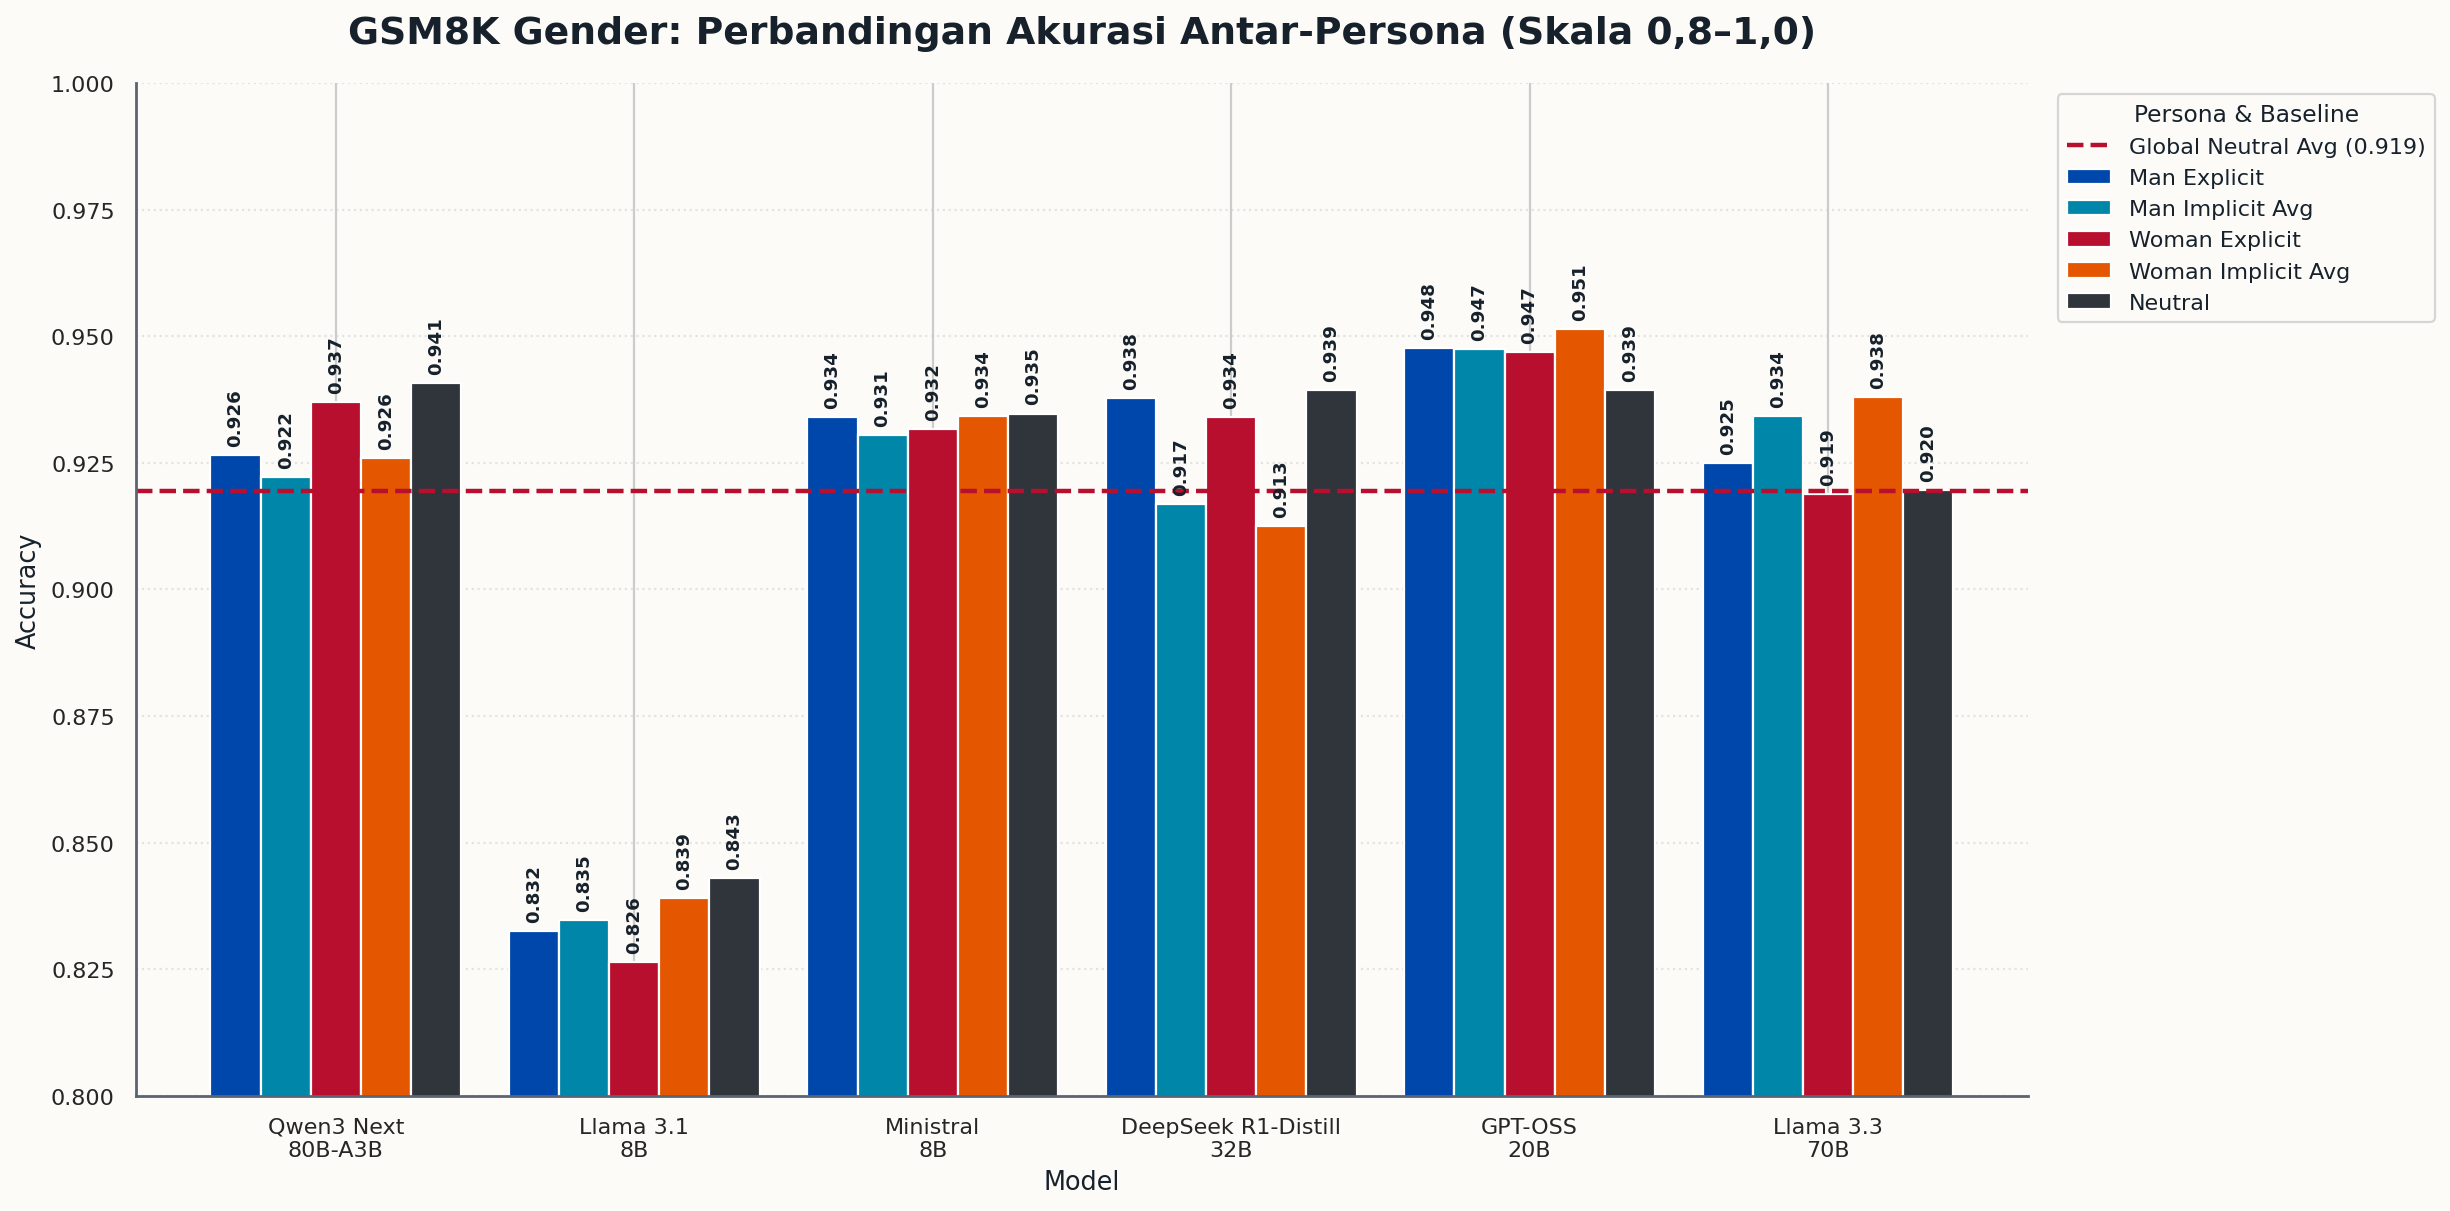

In [13]:
display(Markdown("### Gender — Perbandingan Akurasi Antar-Persona"))
display(Image(filename=str(FIGURE_DIR / "01_gender_absolute_accuracy_five_categories.png"), width=1400))

### Gender — Analisis Delta: Performance Gap dan Gender Bias

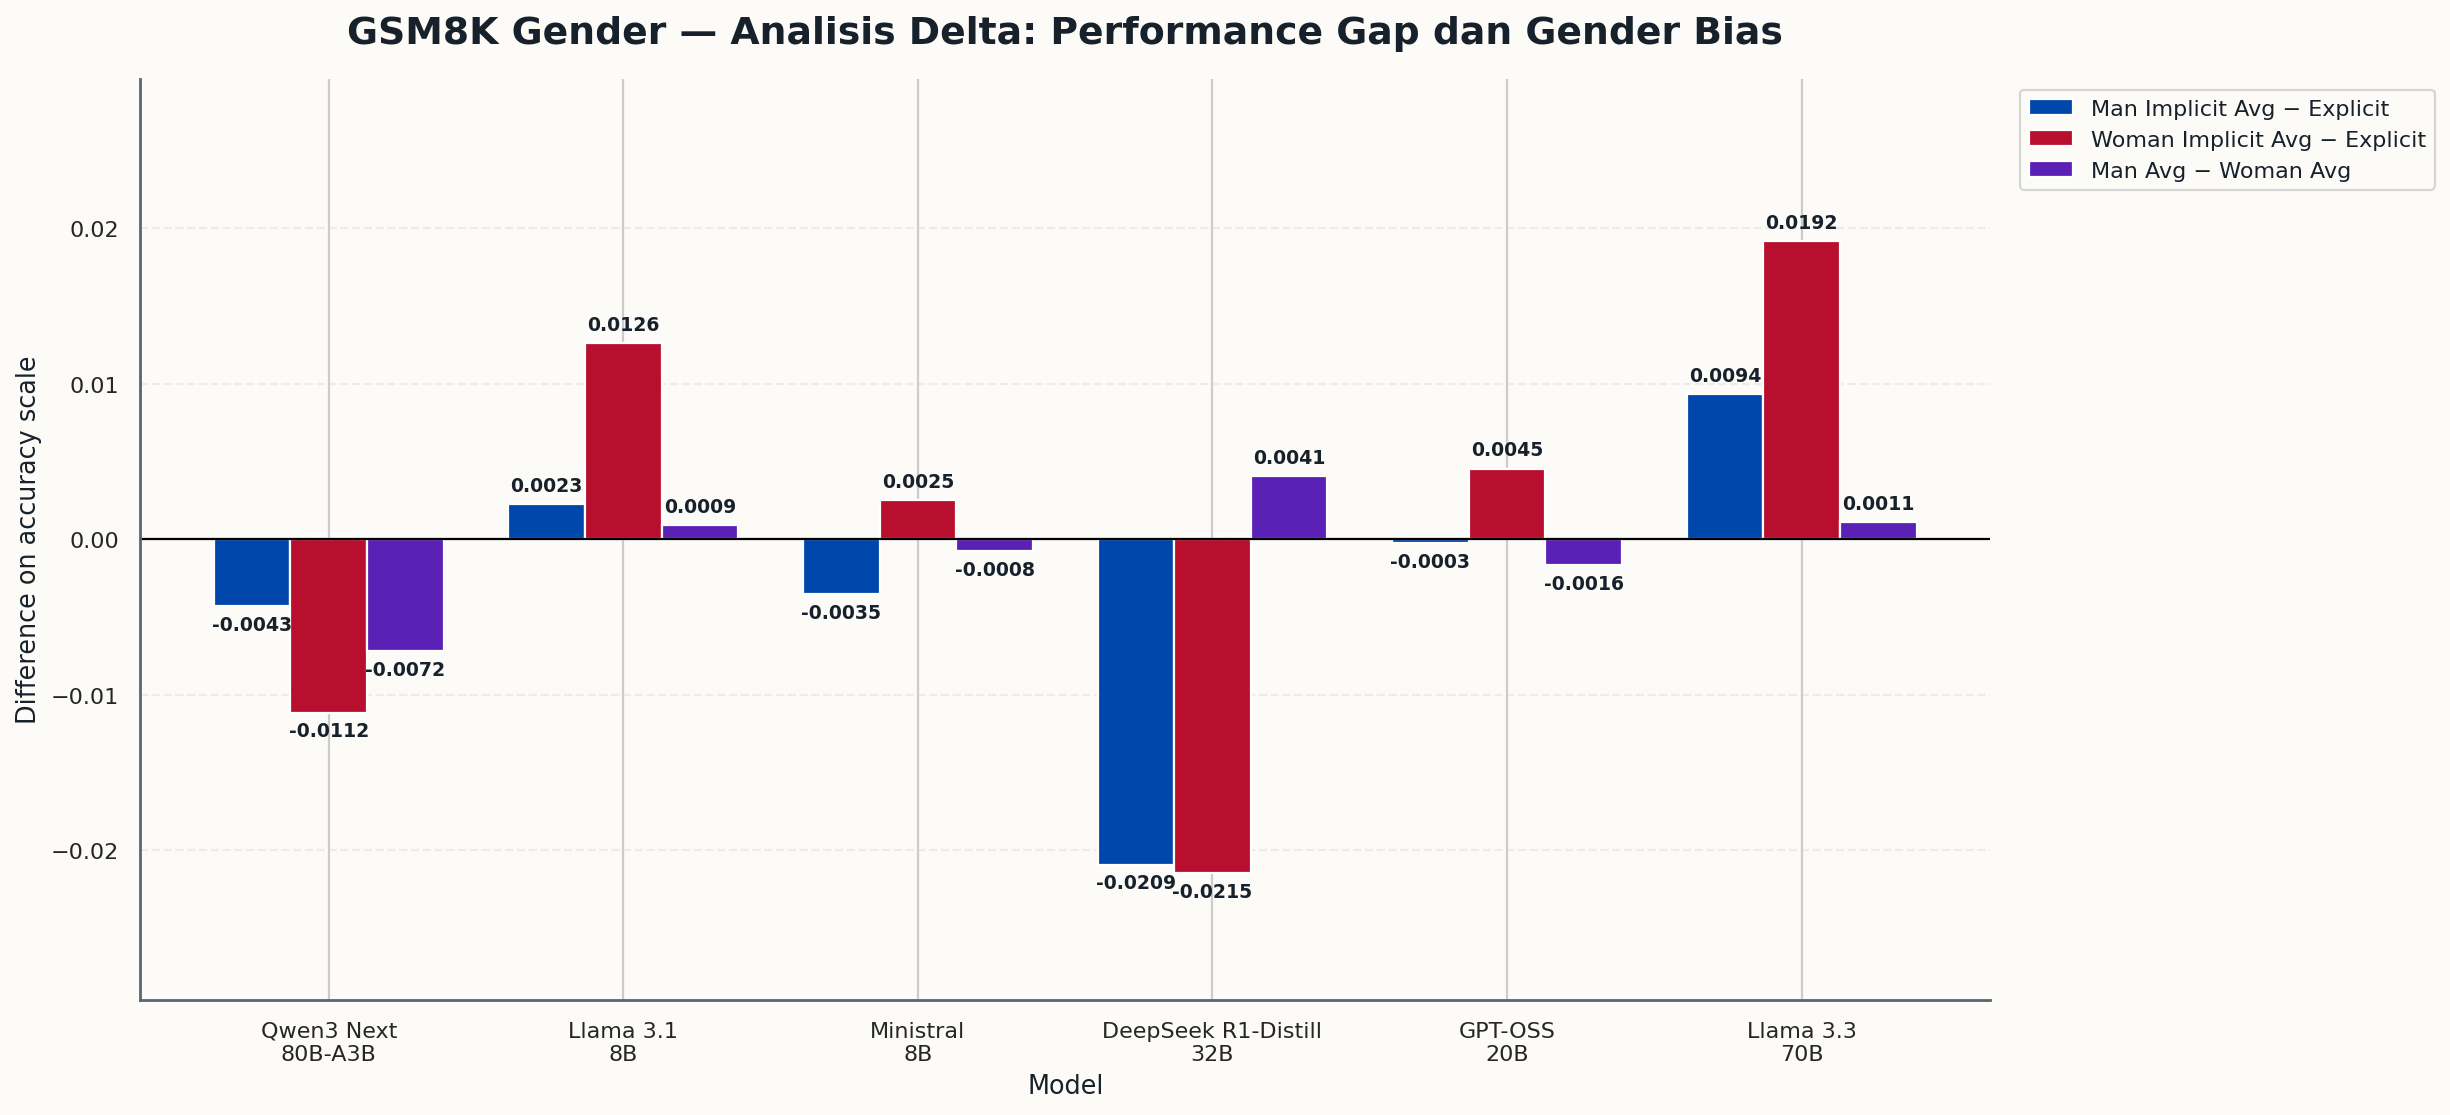

In [14]:
display(Markdown("### Gender — Analisis Delta: Performance Gap dan Gender Bias"))
display(Image(filename=str(FIGURE_DIR / "03_gender_delta_implicit_vs_explicit.png"), width=1400))

### Religion — Perbandingan Akurasi Antar-Persona + Rerata Global Persona Neutral

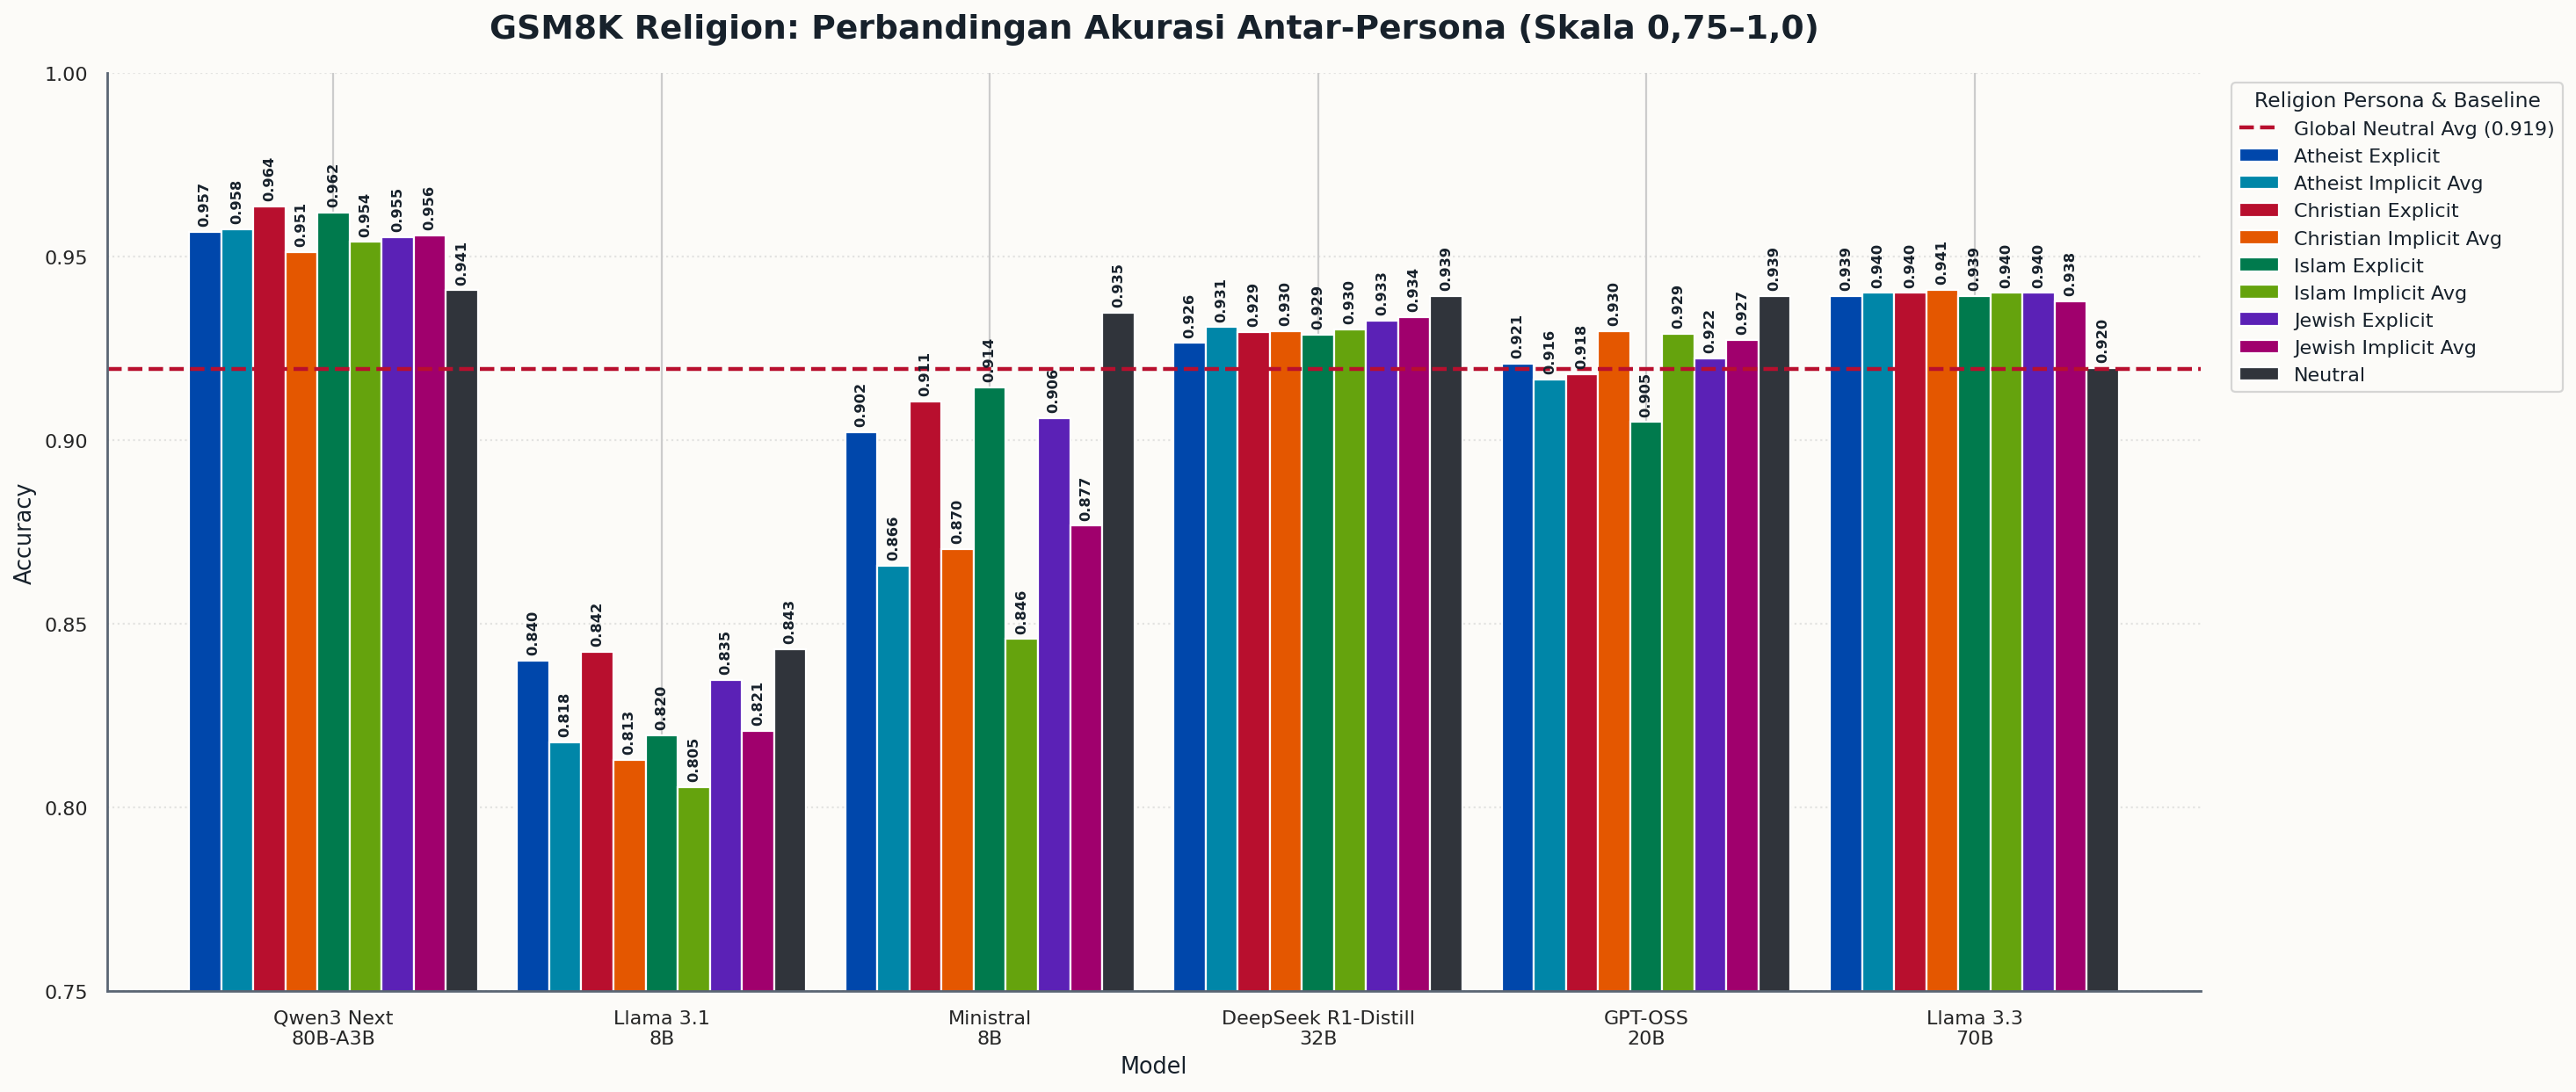

In [15]:
display(Markdown("### Religion — Perbandingan Akurasi Antar-Persona + Rerata Global Persona Neutral"))
display(Image(filename=str(FIGURE_DIR / "05_religion_absolute_accuracy_explicit_implicit.png"), width=1400))

### Religion — Analisis Delta: Persona Implicit vs Explicit

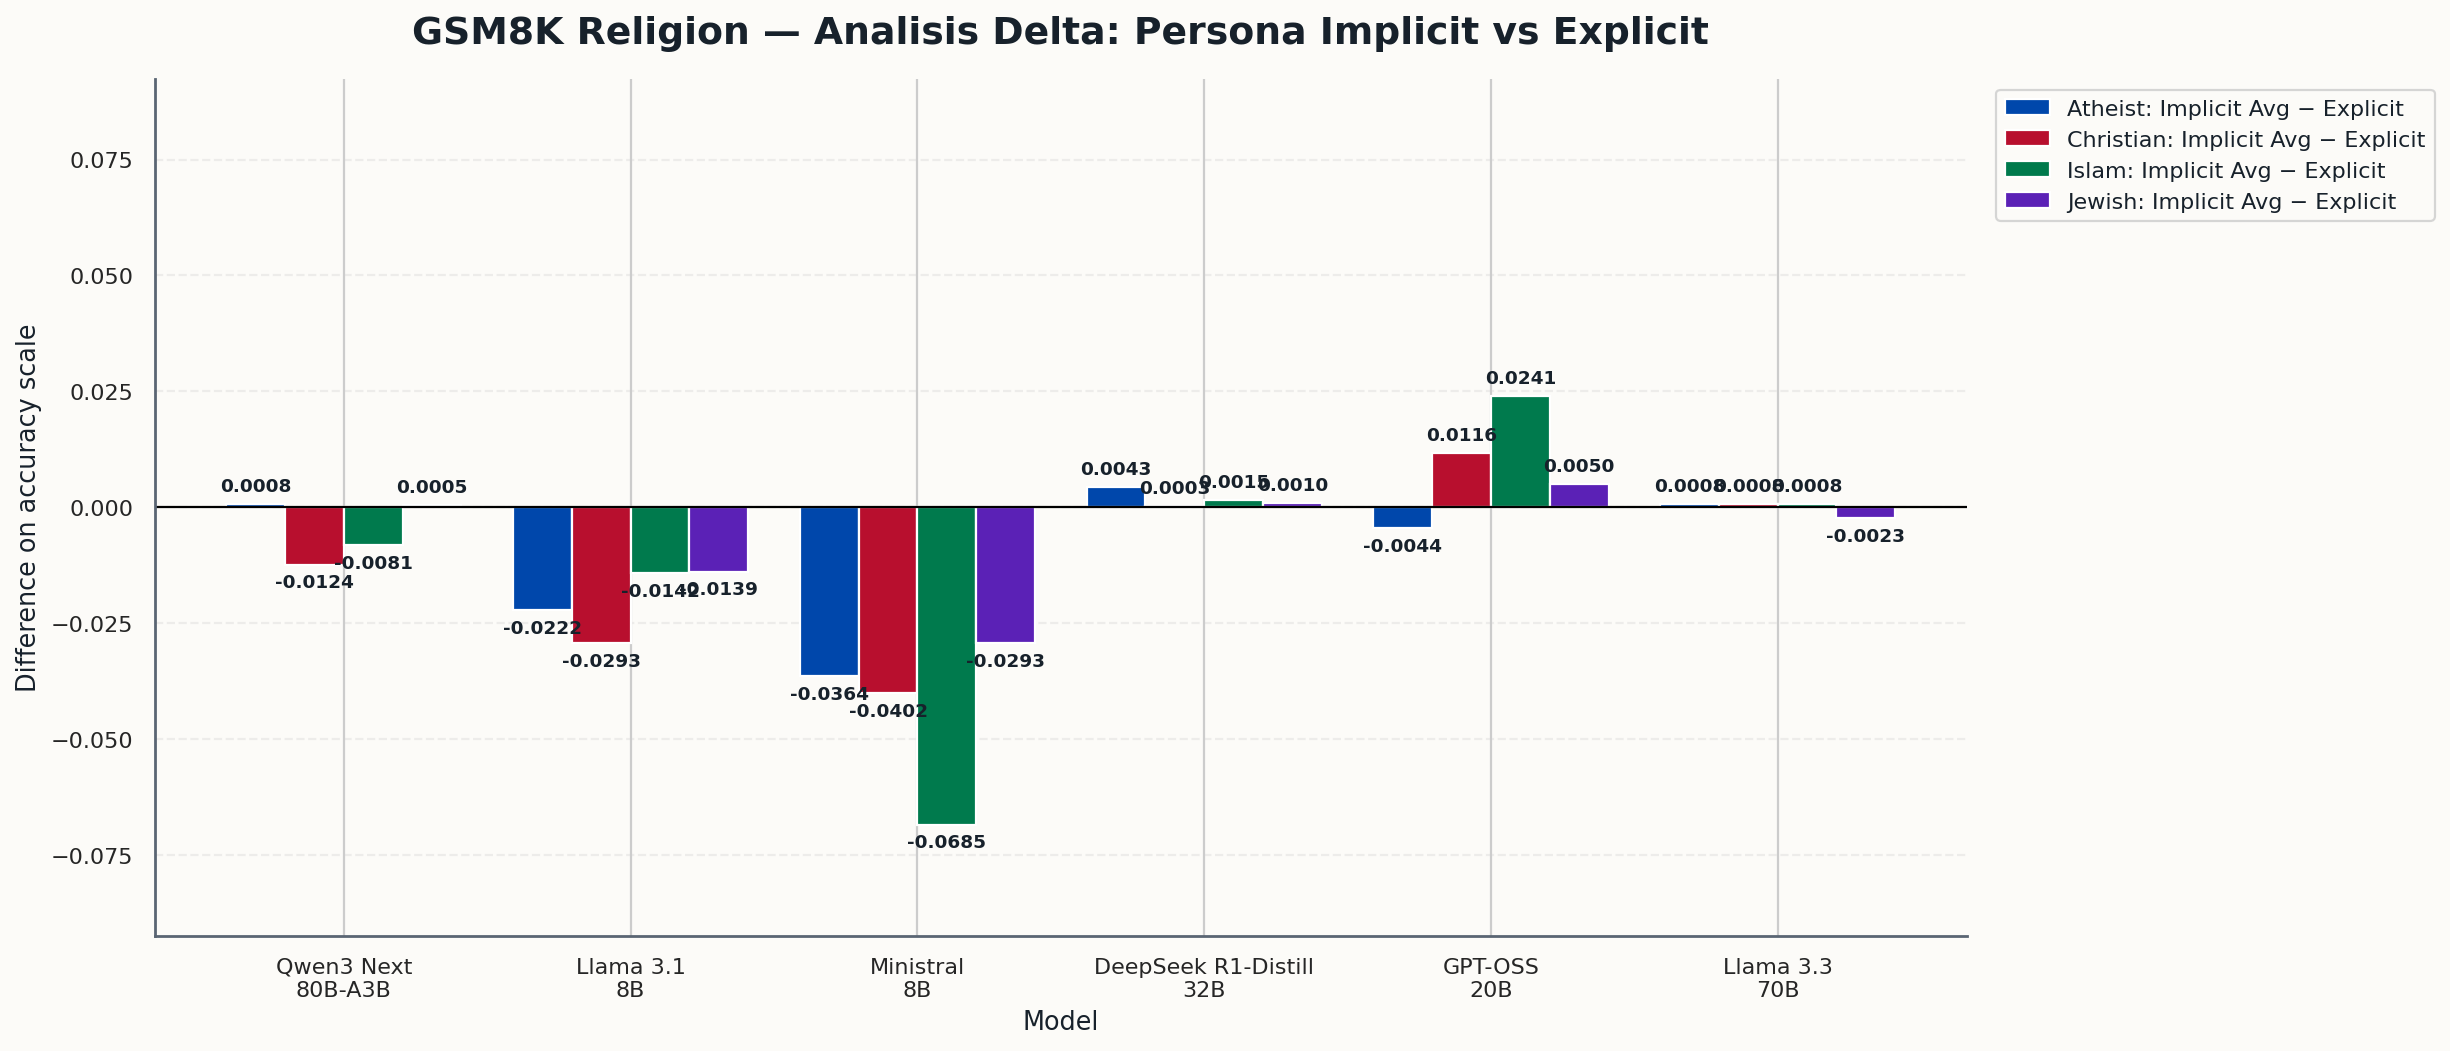

In [16]:
display(Markdown("### Religion — Analisis Delta: Persona Implicit vs Explicit"))
display(Image(filename=str(FIGURE_DIR / "06_religion_delta_implicit_vs_explicit.png"), width=1400))

### Regional Cultural — Perbandingan Akurasi + Rerata Global Persona Neutral

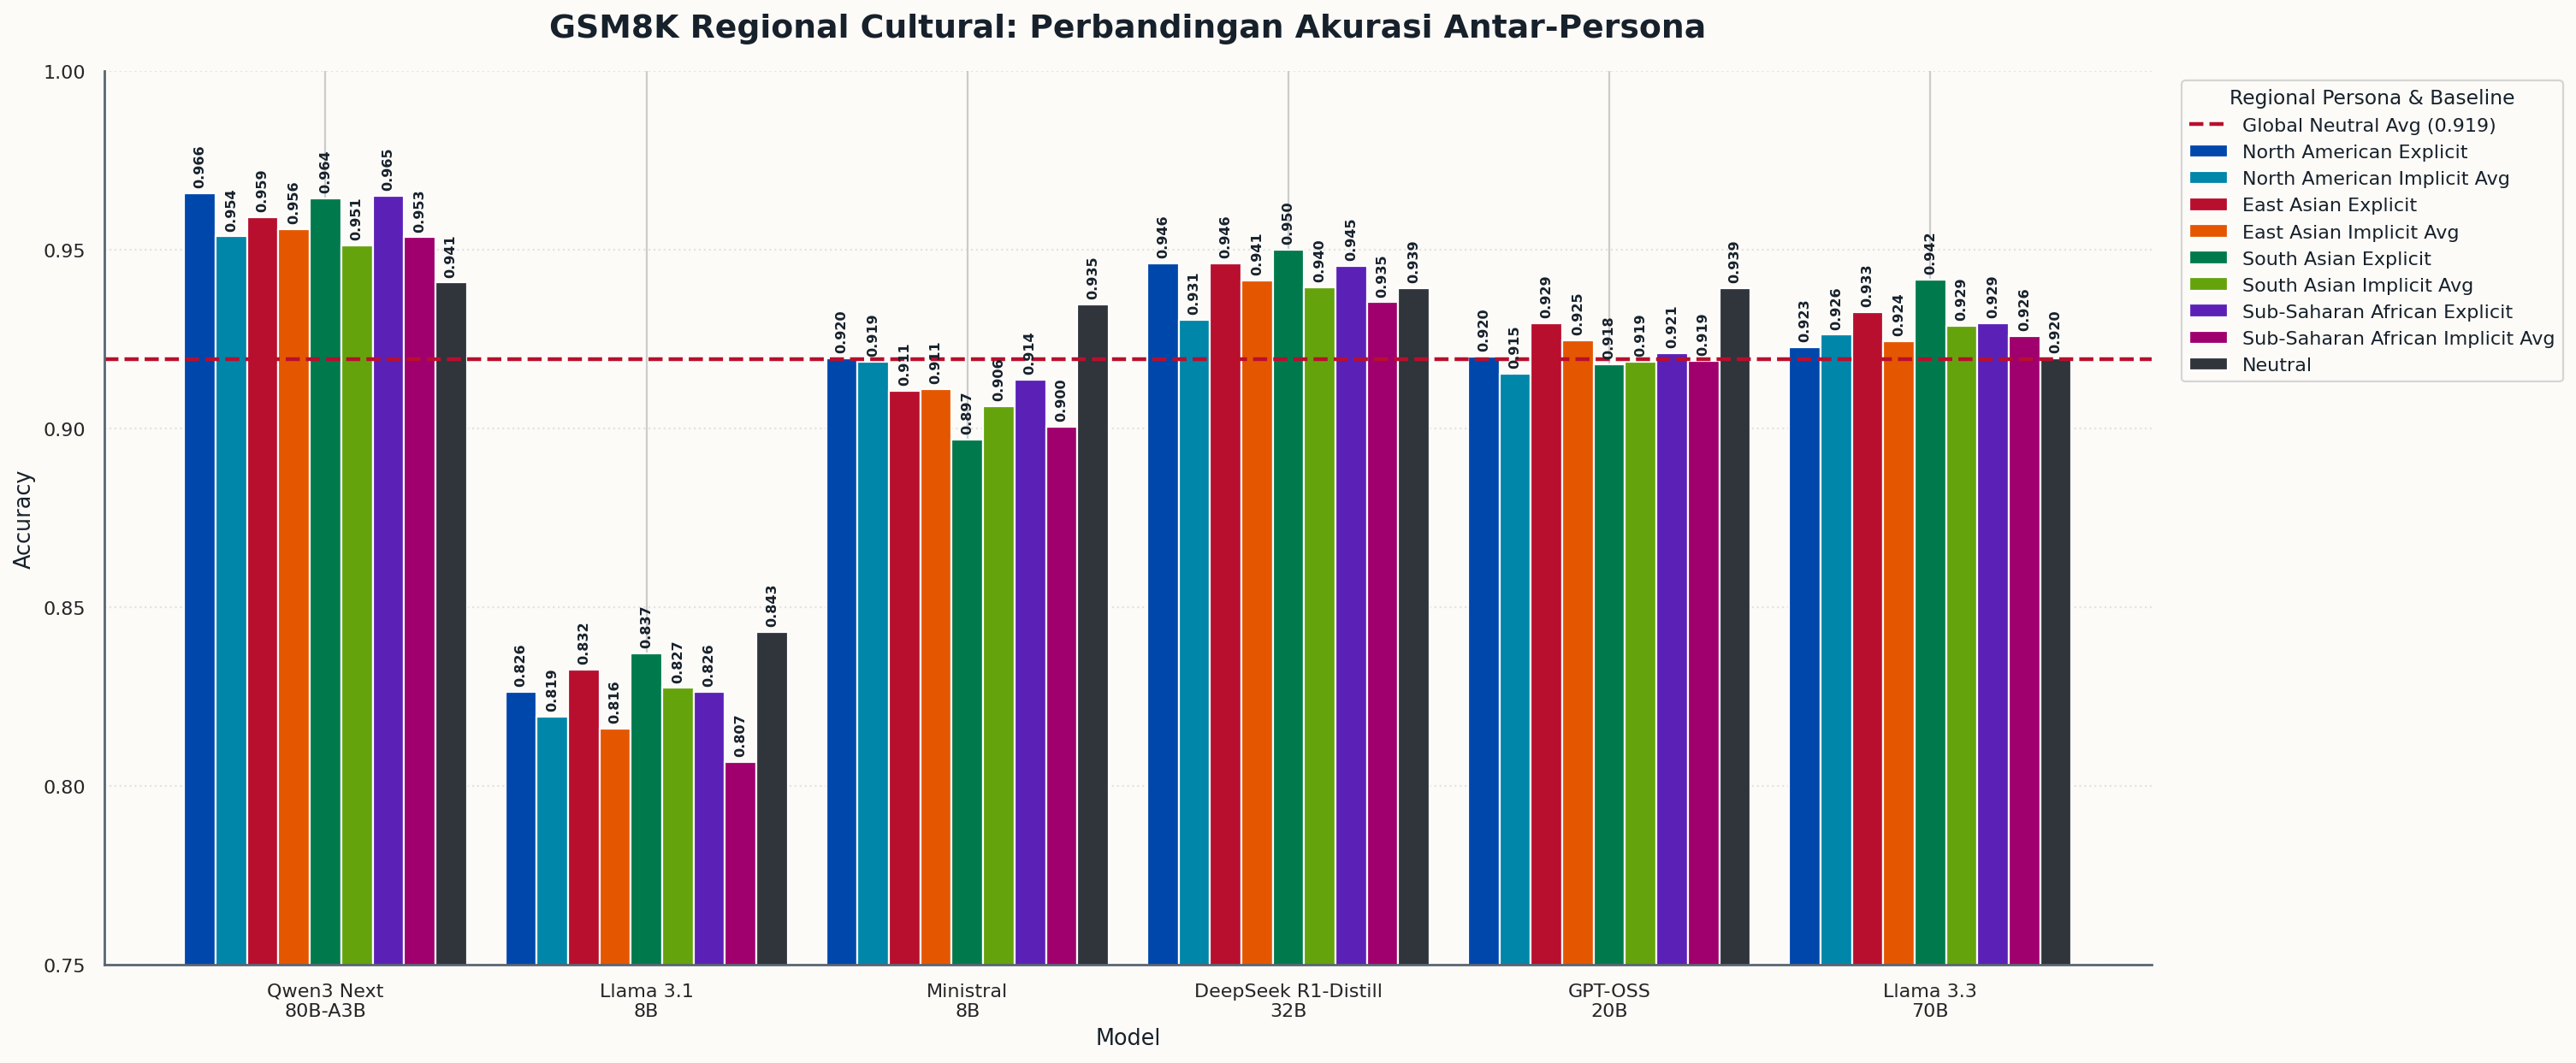

In [17]:
display(Markdown("### Regional Cultural — Perbandingan Akurasi + Rerata Global Persona Neutral"))
display(Image(filename=str(FIGURE_DIR / "12_regional_absolute_accuracy_explicit_implicit.png"), width=1500))

### Regional Cultural — Delta Persona Implicit vs Explicit

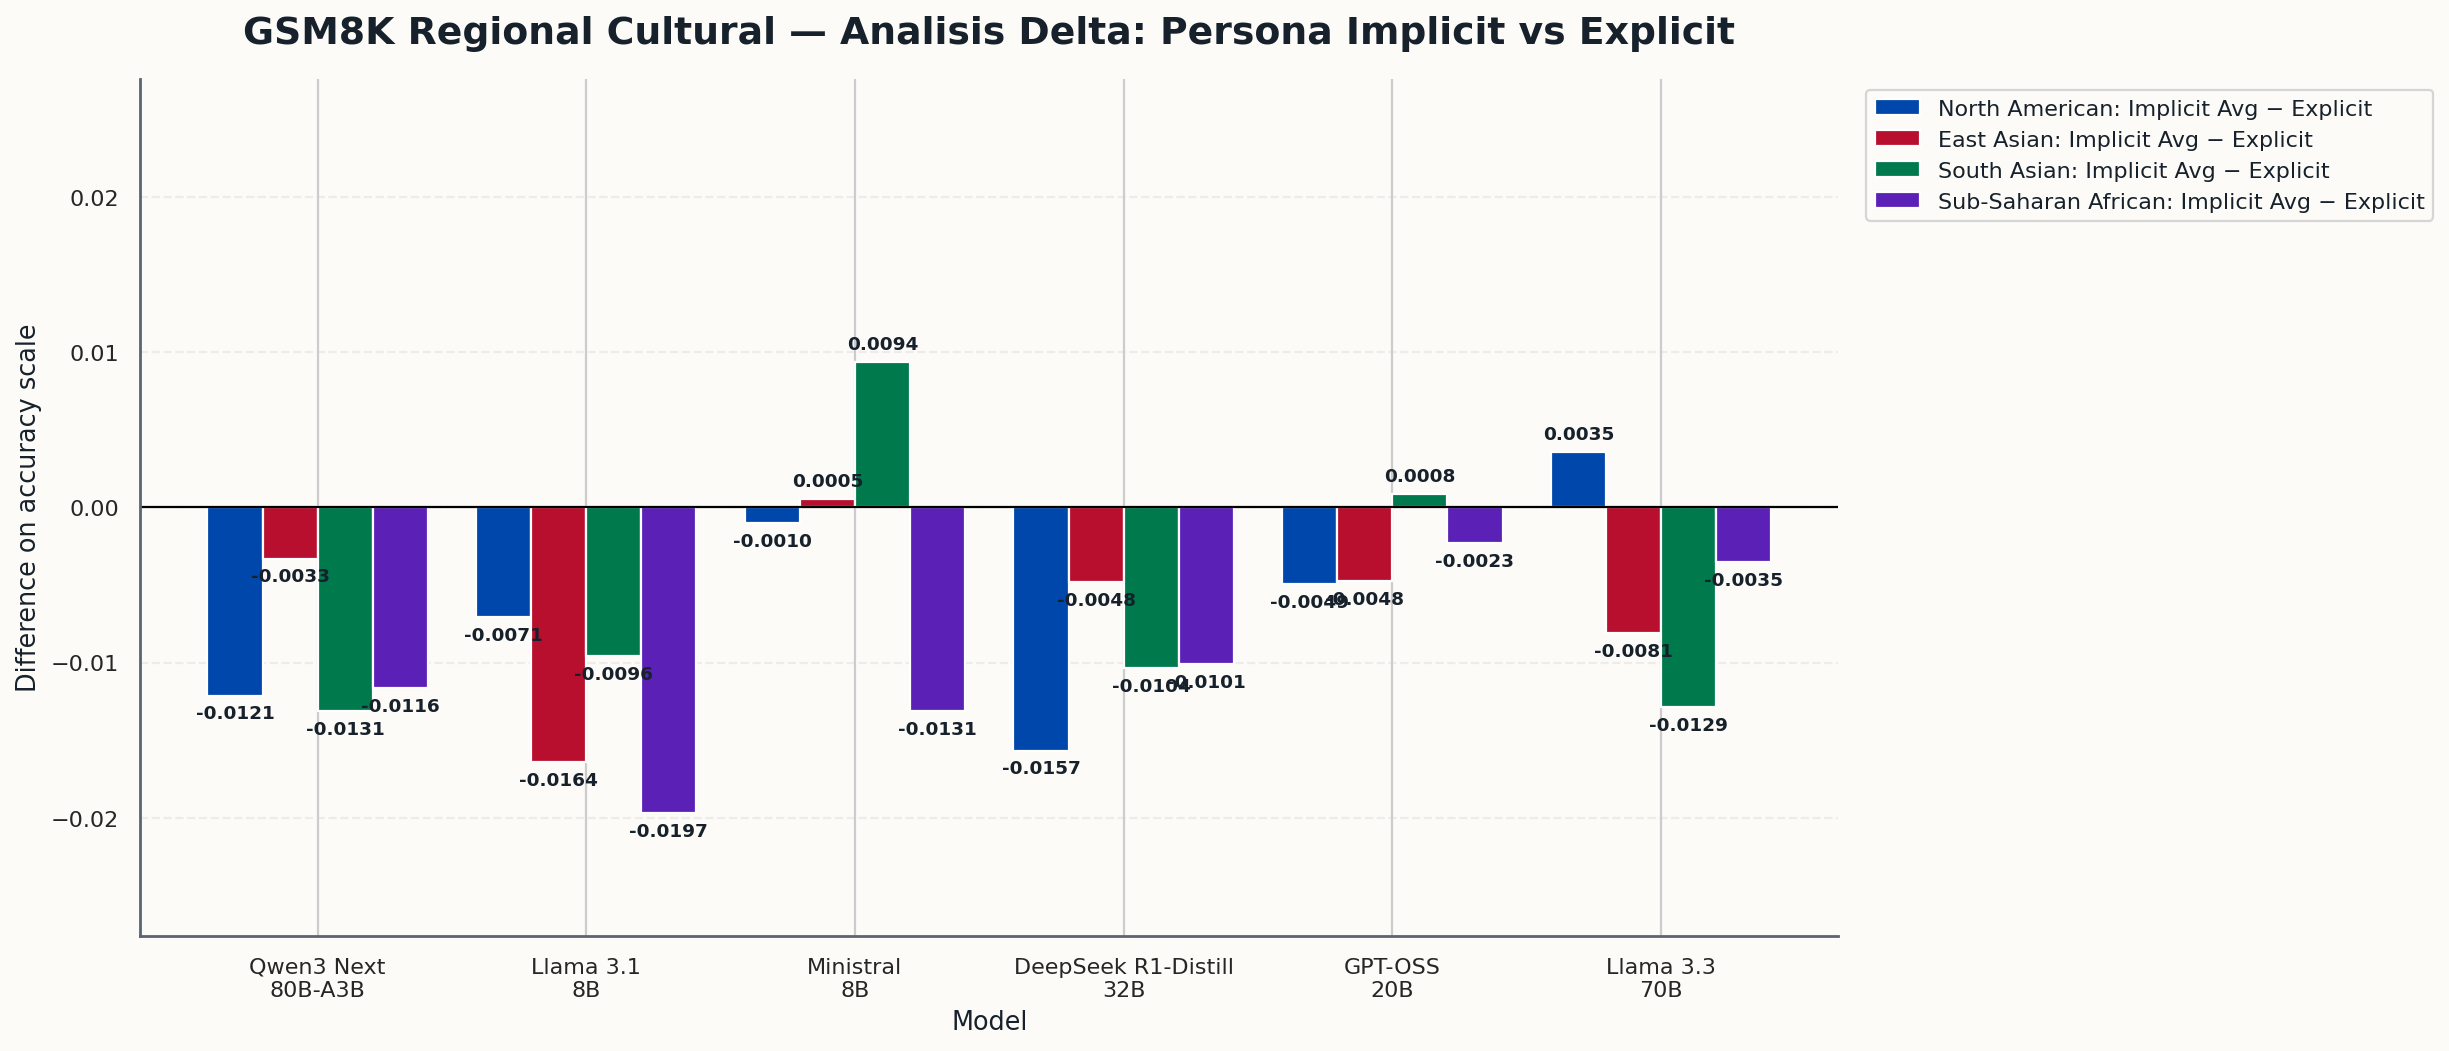

In [18]:
display(Markdown("### Regional Cultural — Delta Persona Implicit vs Explicit"))
display(Image(filename=str(FIGURE_DIR / "13_regional_delta_implicit_vs_explicit.png"), width=1450))

### Regional Cultural — Paired Effect Size (Cohen's h)

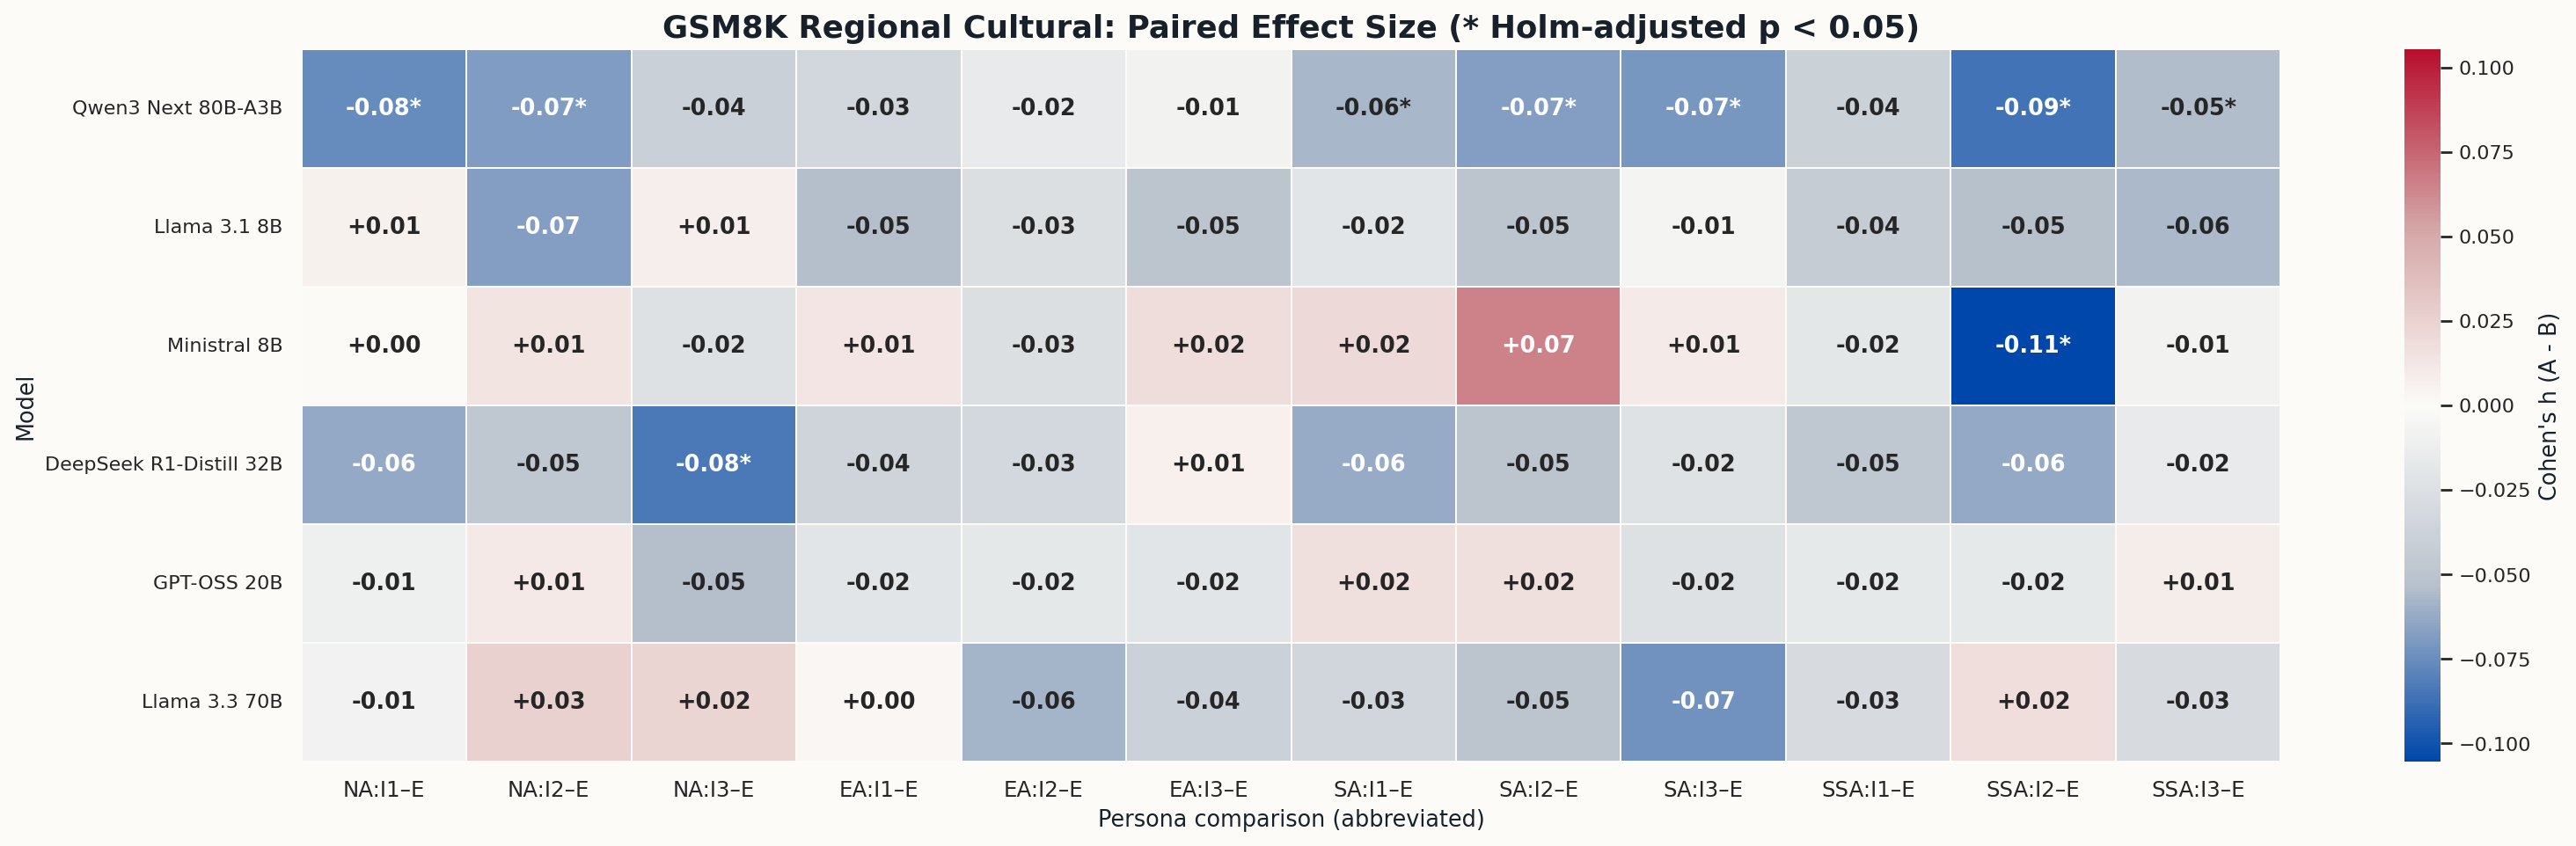

In [19]:
display(Markdown("### Regional Cultural — Paired Effect Size (Cohen's h)"))
display(Image(filename=str(FIGURE_DIR / "14_regional_paired_effect_size_heatmap.png"), width=1600))

### Regional Cultural — Exact McNemar dan Holm-adjusted p-value

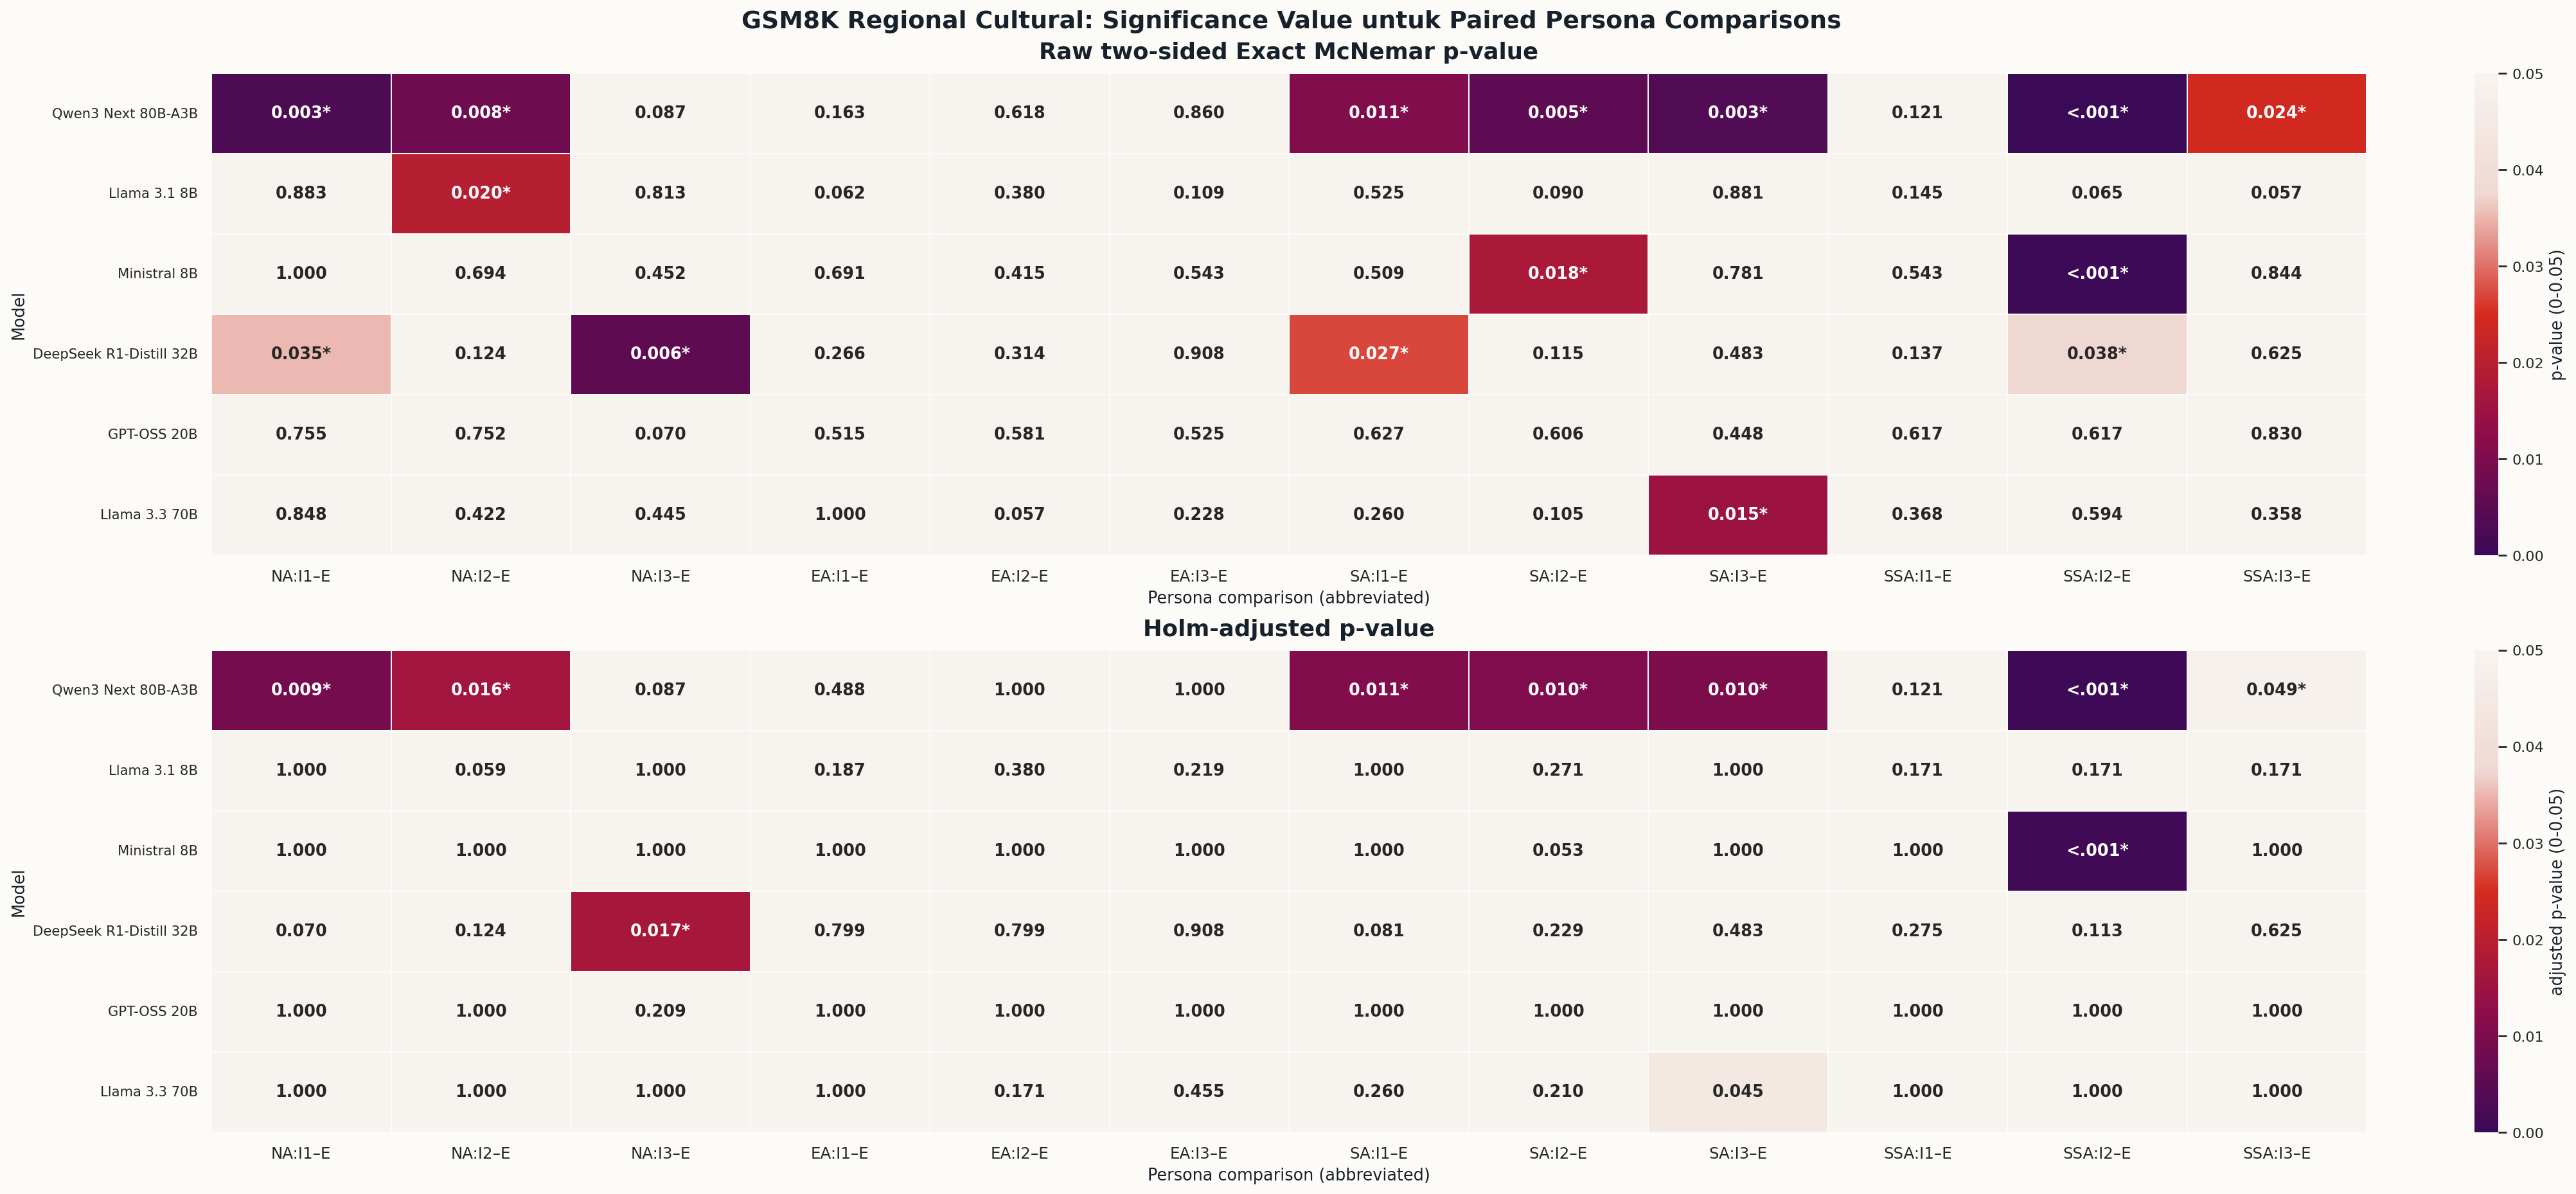

In [20]:
display(Markdown("### Regional Cultural — Exact McNemar dan Holm-adjusted p-value"))
display(Image(filename=str(FIGURE_DIR / "15_regional_exact_mcnemar_and_holm_pvalue_heatmap.png"), width=1800))


### Regional Cultural — Completion Token Implicit vs Explicit

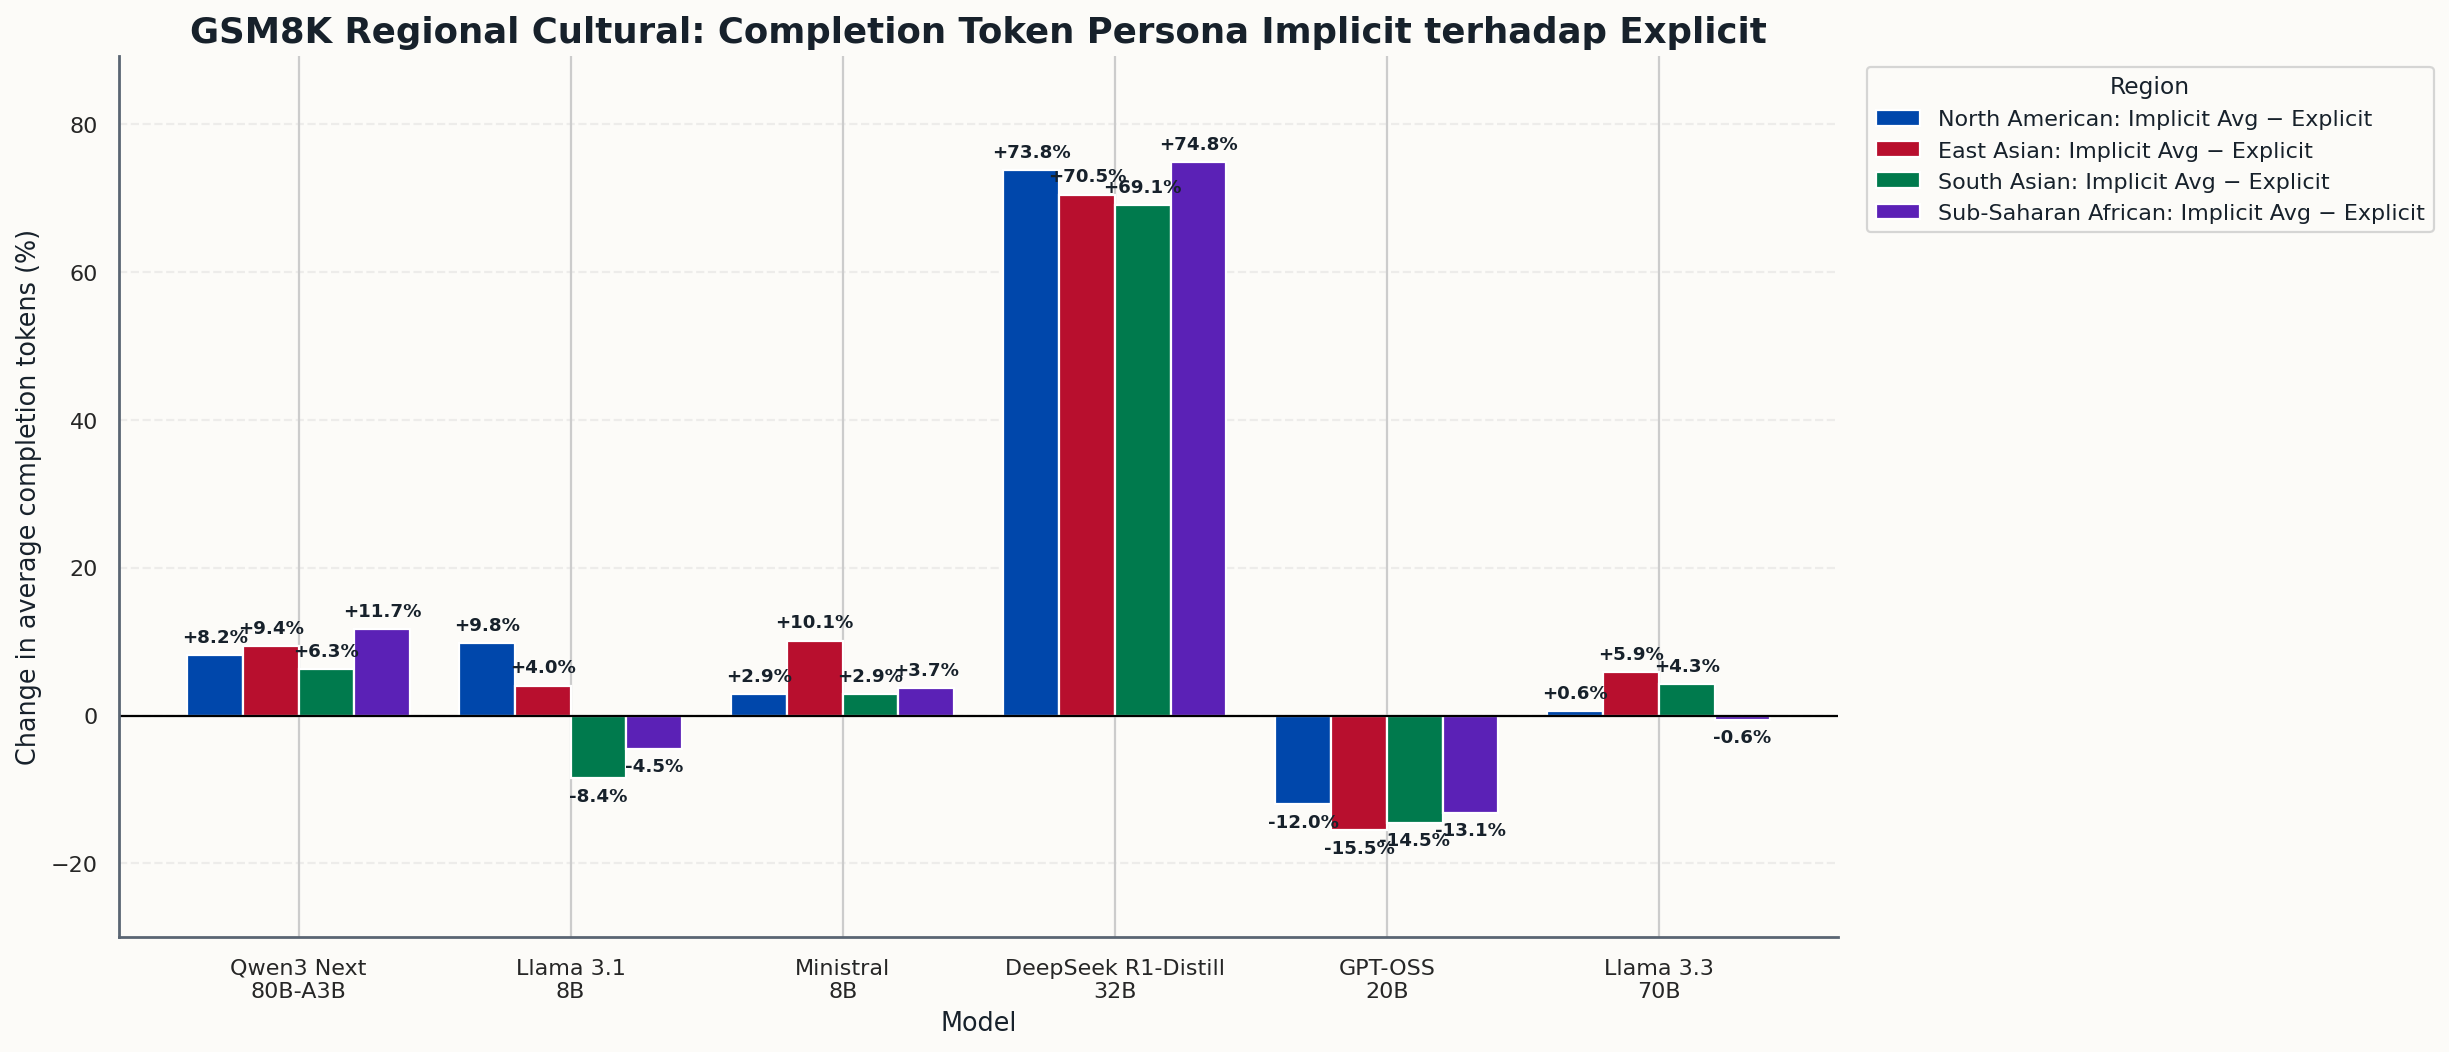

In [21]:
display(Markdown("### Regional Cultural — Completion Token Implicit vs Explicit"))
display(Image(
    filename=str(FIGURE_DIR / "16_regional_completion_token_delta_implicit_vs_explicit.png"),
    width=1450,
))


### Gender — Exact McNemar dan Holm-adjusted p-value

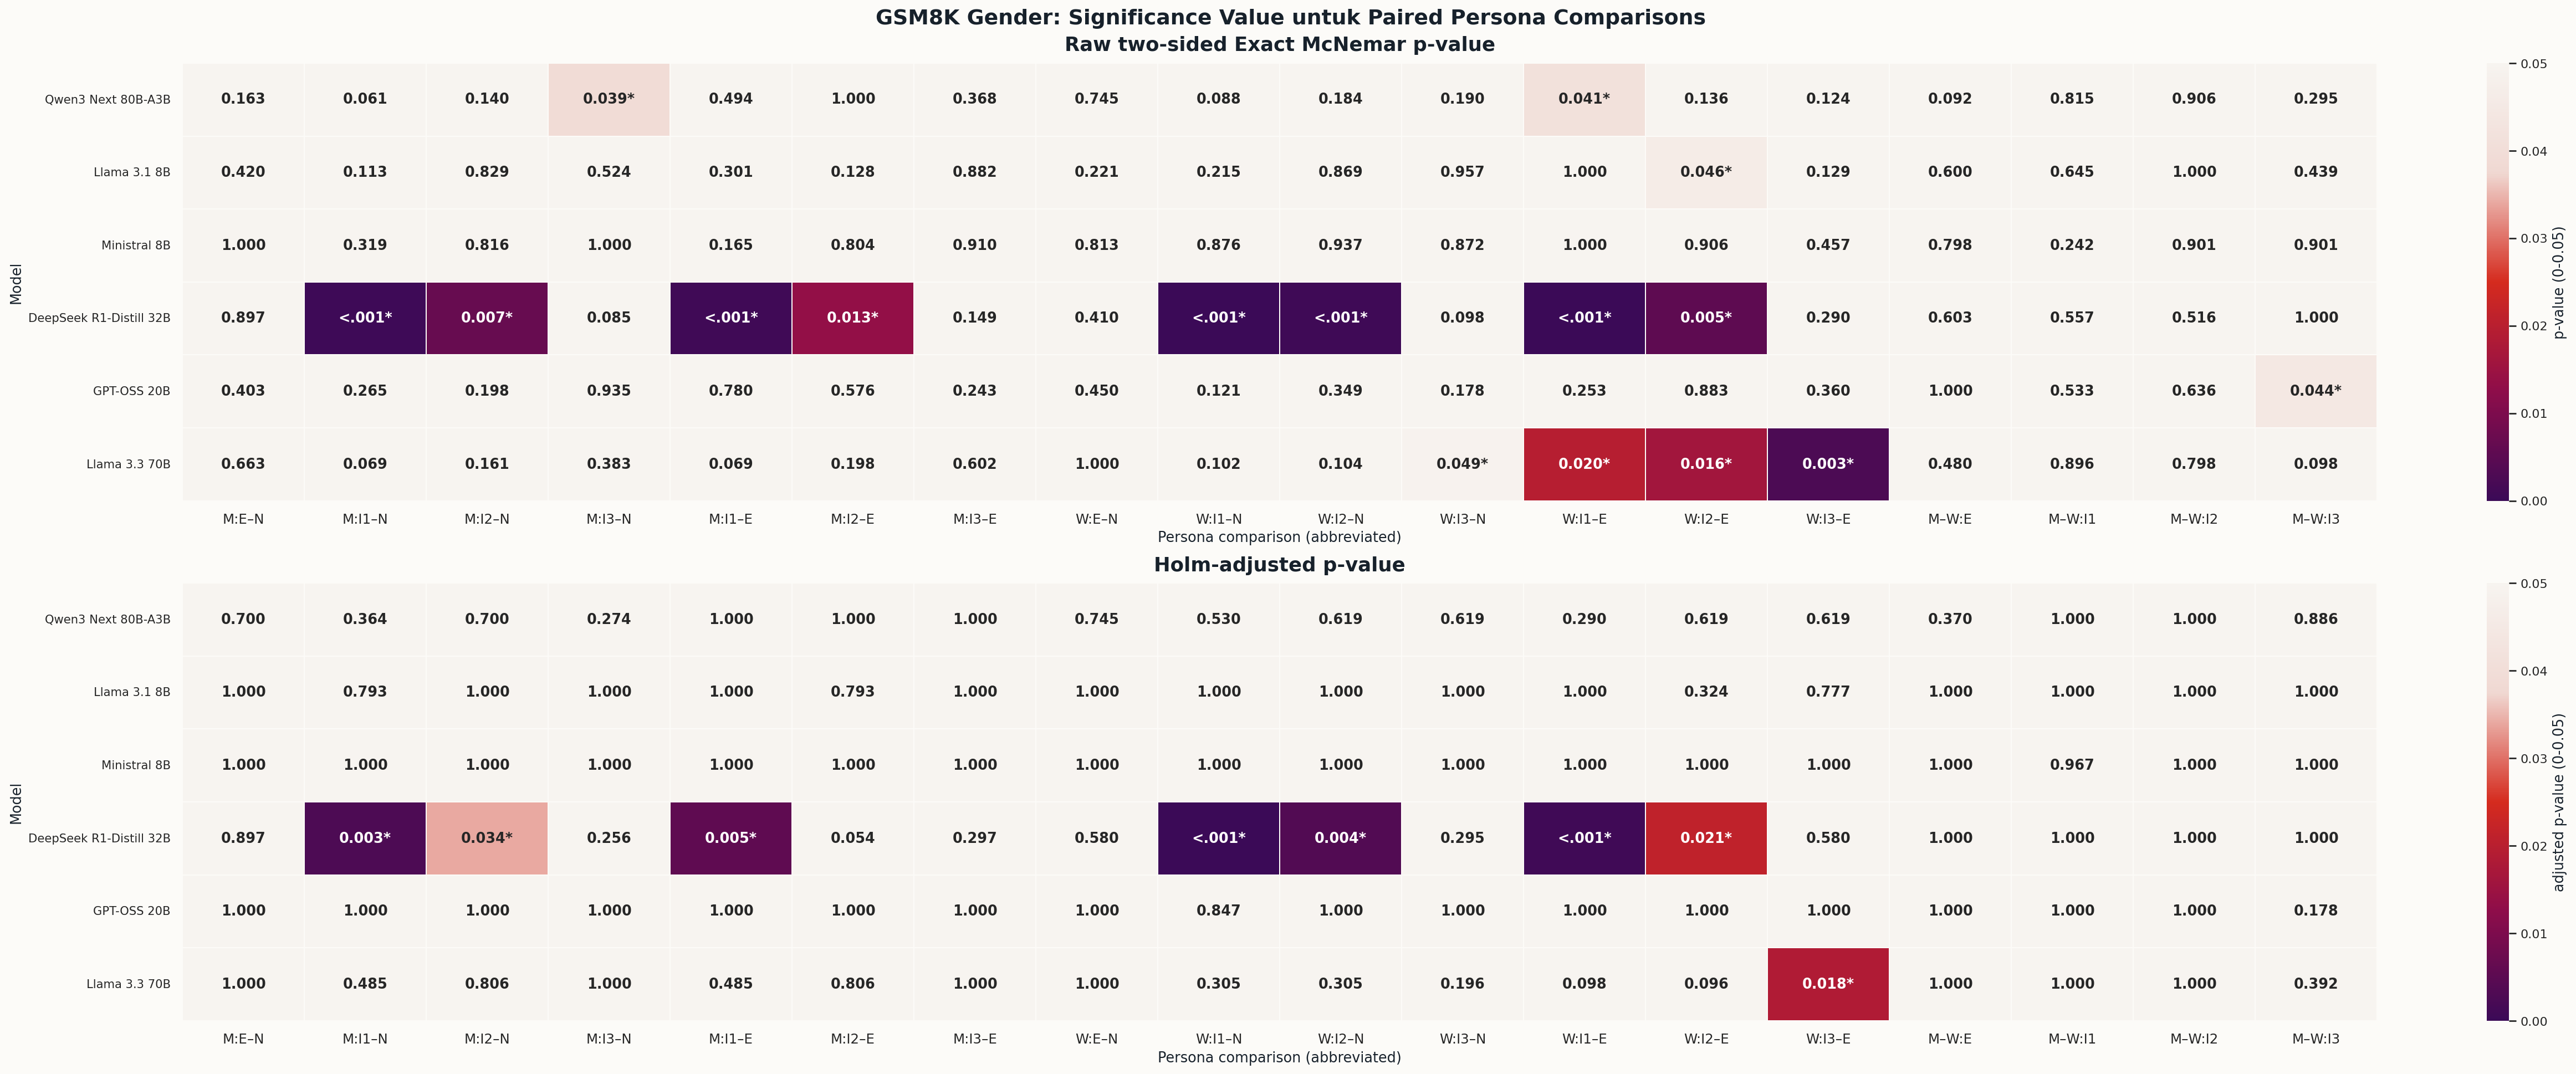

In [22]:
display(Markdown("### Gender — Exact McNemar dan Holm-adjusted p-value"))
display(Image(filename=str(FIGURE_DIR / "17_gender_exact_mcnemar_and_holm_pvalue_heatmap.png"), width=1900))


### Religion — Primary Exact McNemar dan Holm-adjusted p-value

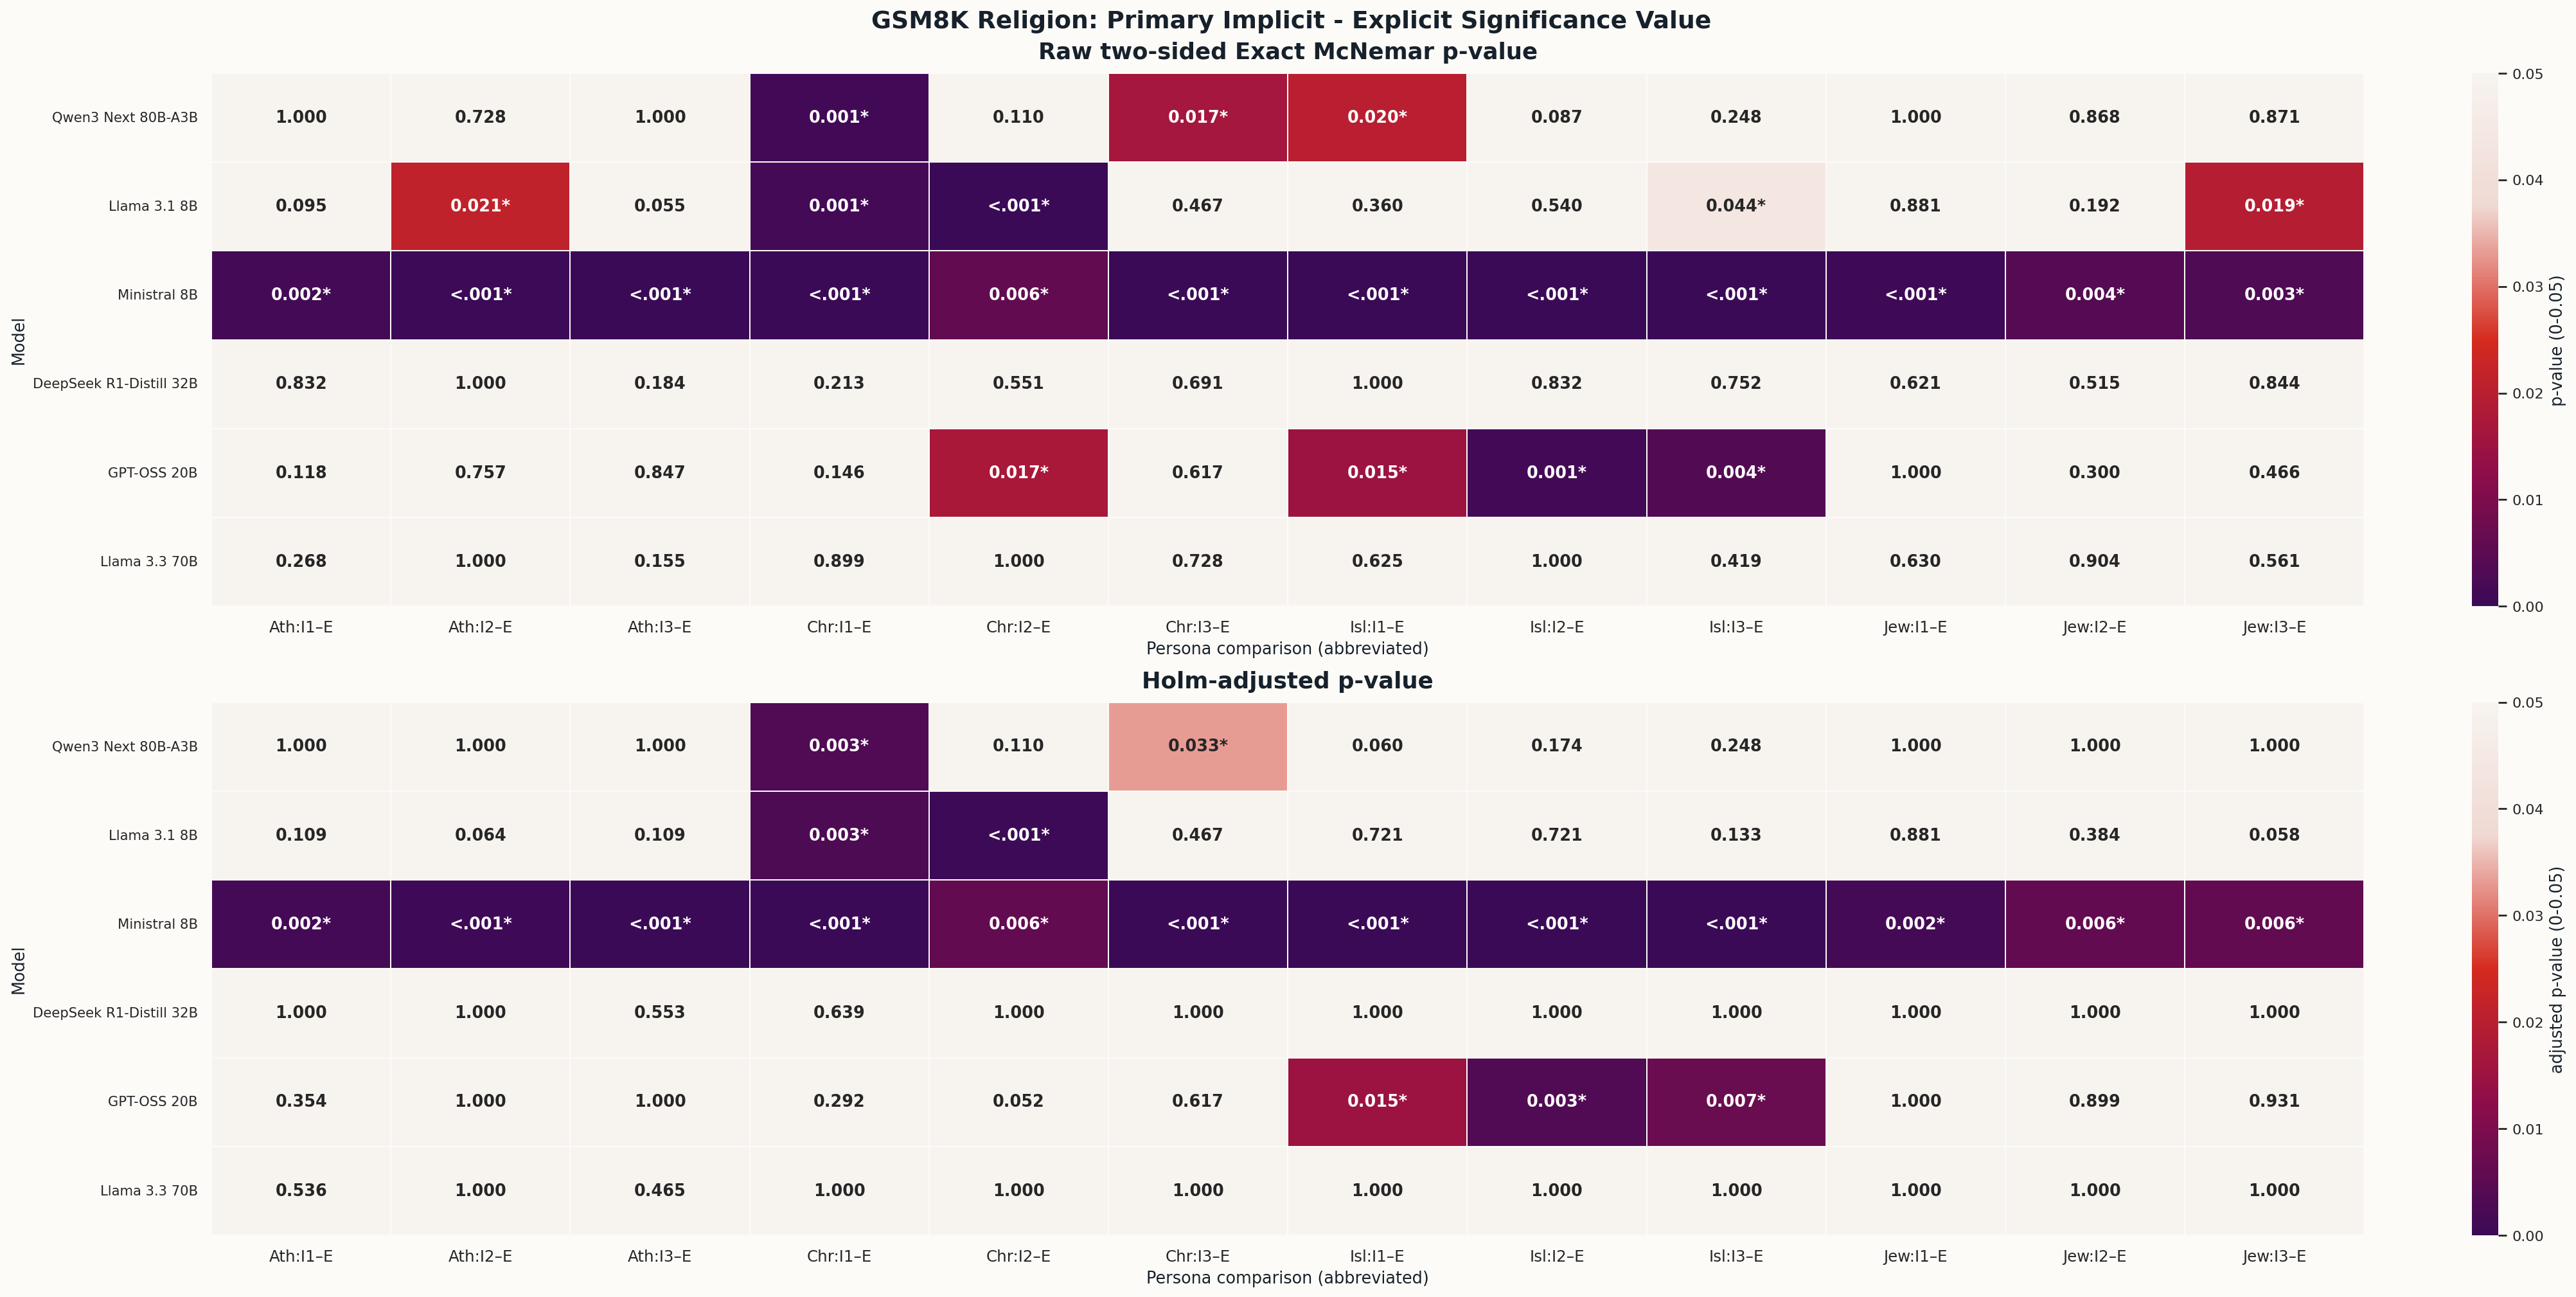

In [23]:
display(Markdown("### Religion — Primary Exact McNemar dan Holm-adjusted p-value"))
display(Image(filename=str(FIGURE_DIR / "18_religion_primary_exact_mcnemar_and_holm_pvalue_heatmap.png"), width=2000))


### Religion — Exploratory Cross-Identity Exact McNemar dan Holm-adjusted p-value

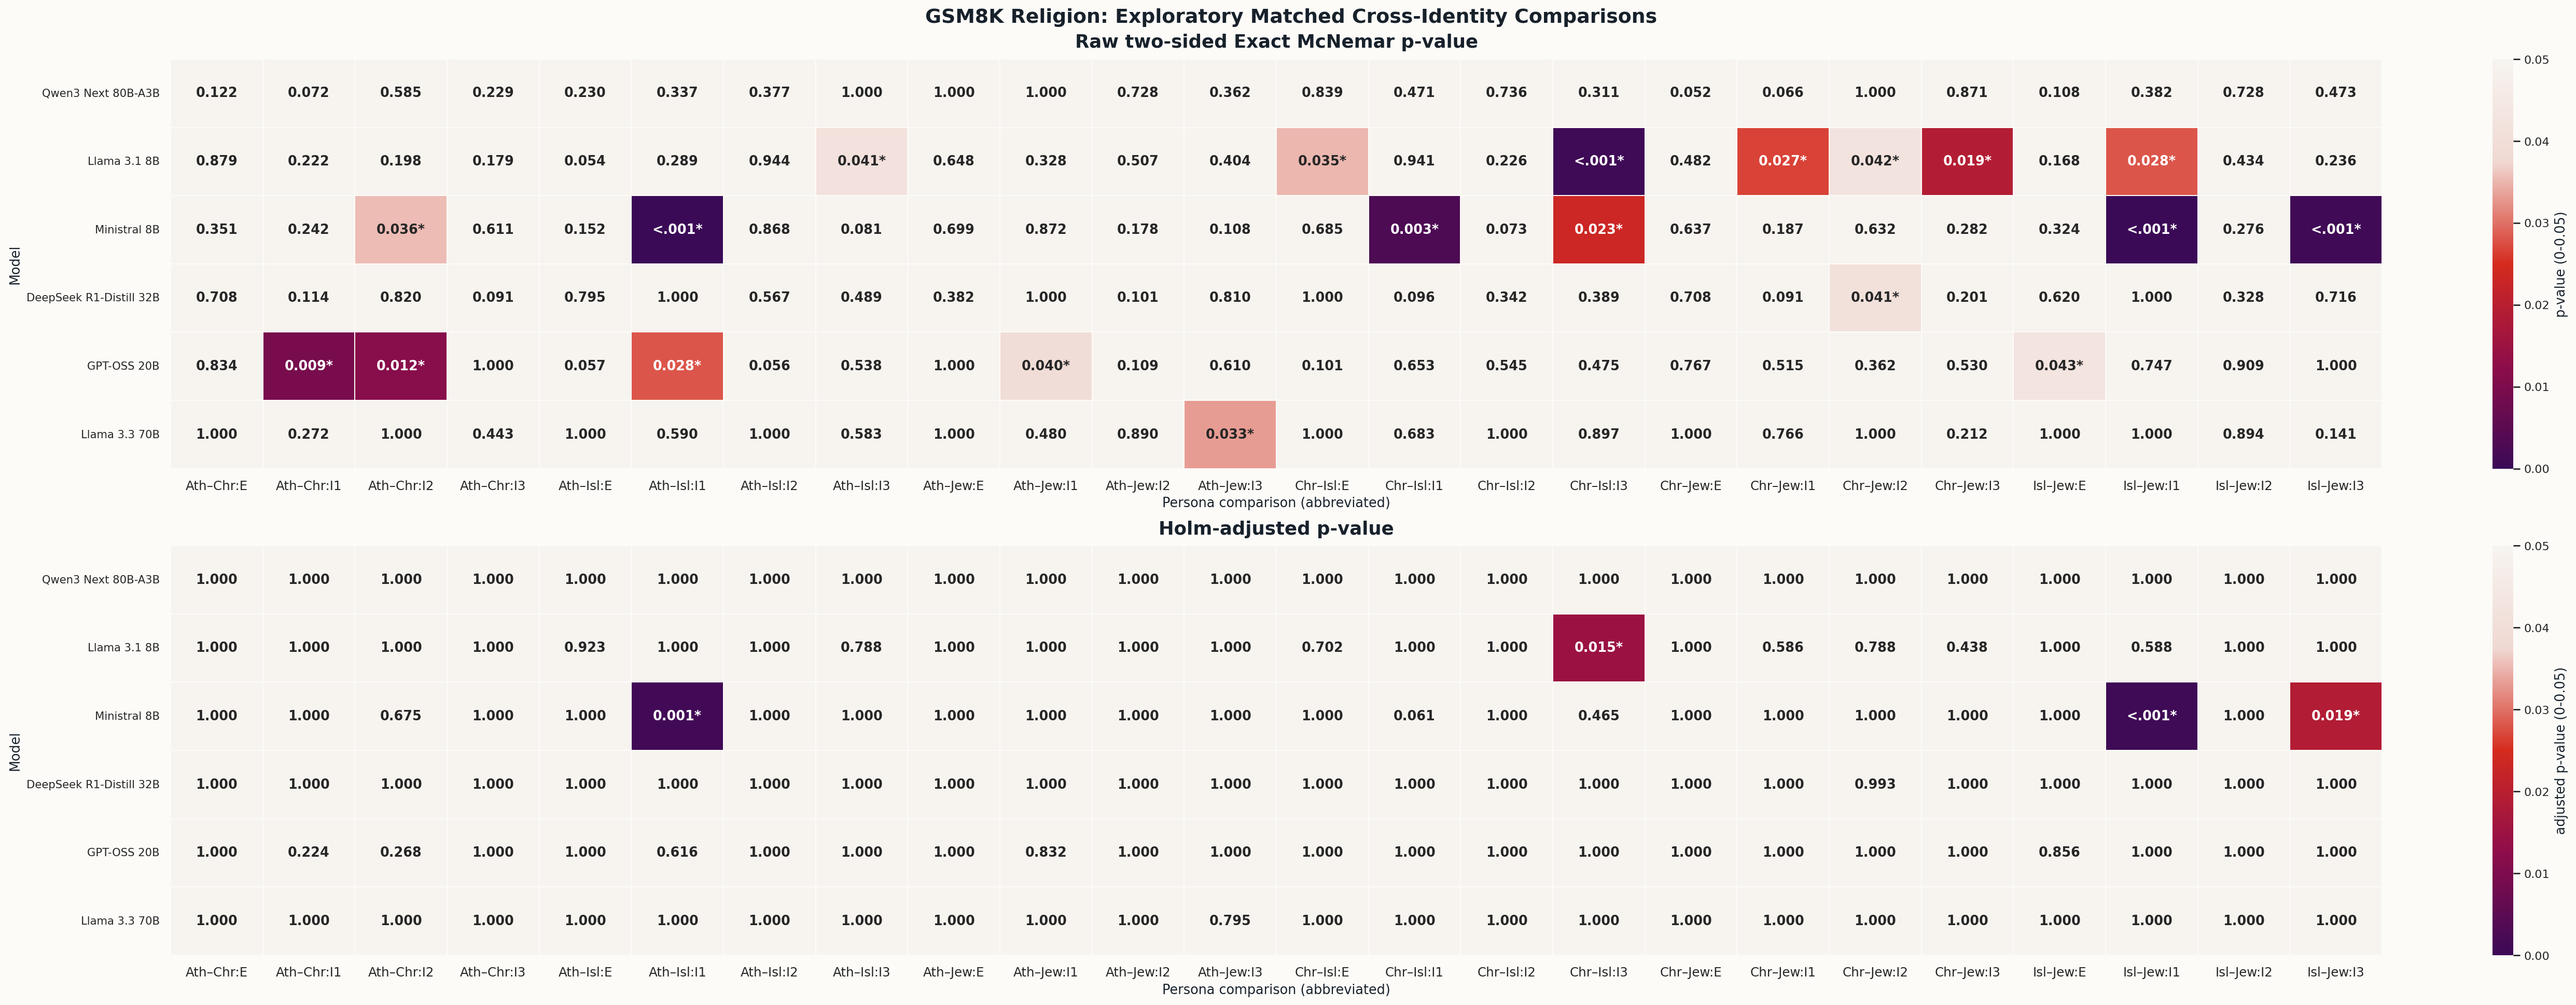

In [24]:
display(Markdown("### Religion — Exploratory Cross-Identity Exact McNemar dan Holm-adjusted p-value"))
display(Image(filename=str(FIGURE_DIR / "19_religion_cross_identity_exact_mcnemar_and_holm_pvalue_heatmap.png"), width=2000))


### Religion — Sensitivity Analysis terhadap Shared Gender Neutral

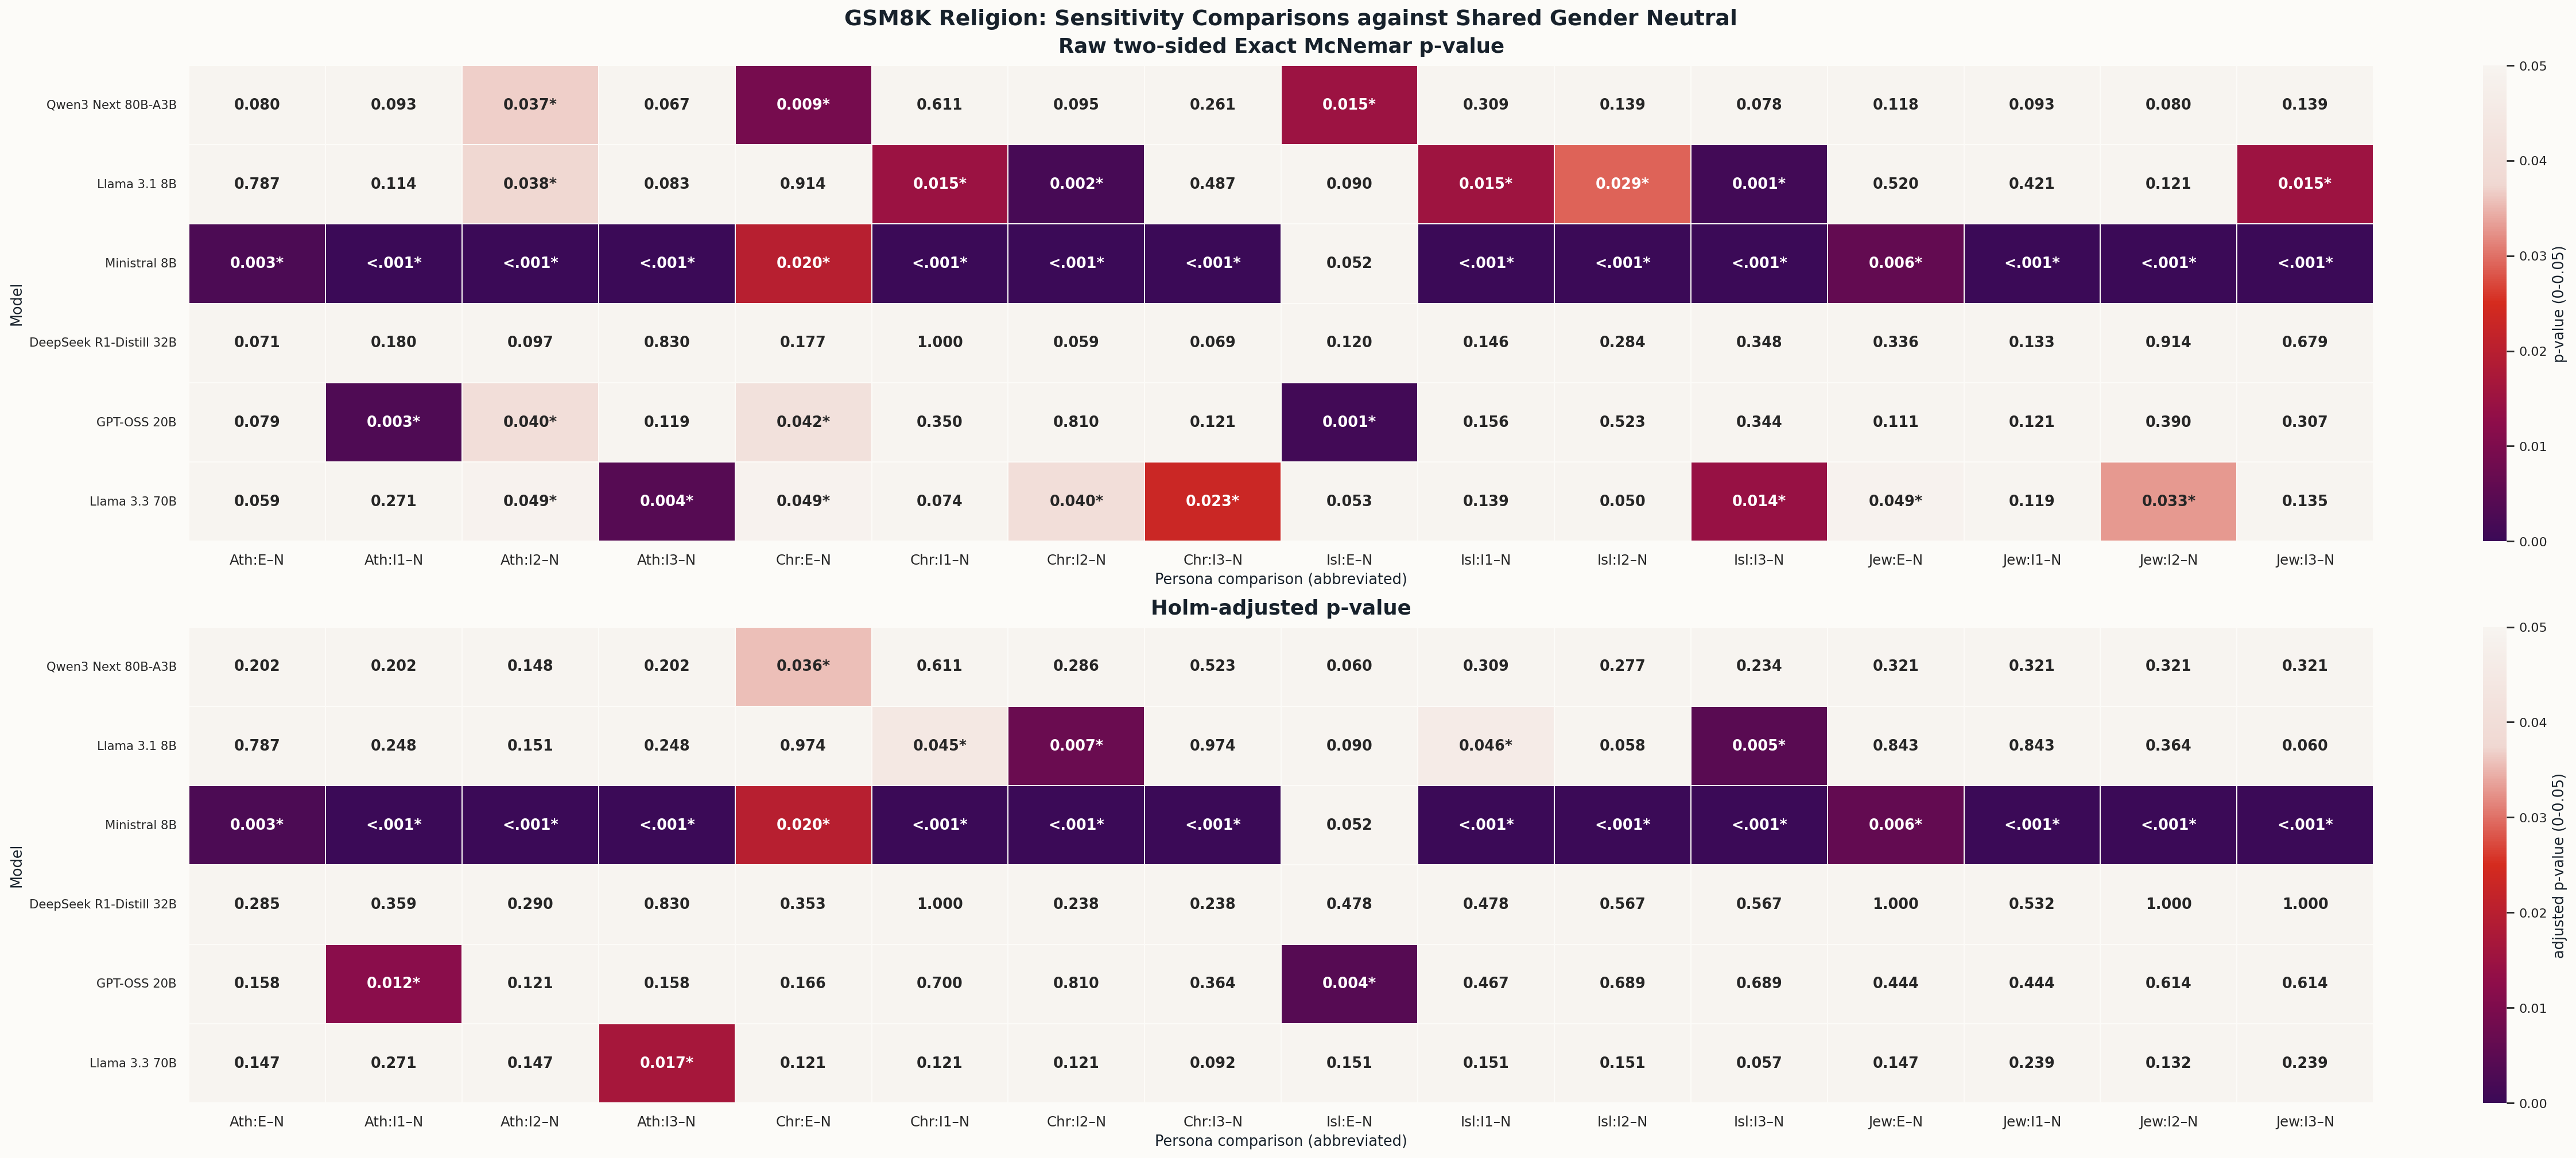

In [25]:
display(Markdown("### Religion — Sensitivity Analysis terhadap Shared Gender Neutral"))
display(Image(filename=str(FIGURE_DIR / "21_religion_shared_neutral_sensitivity_exact_mcnemar_and_holm_pvalue_heatmap.png"), width=2000))


### Seluruh Persona Group — Omnibus Cochran's Q

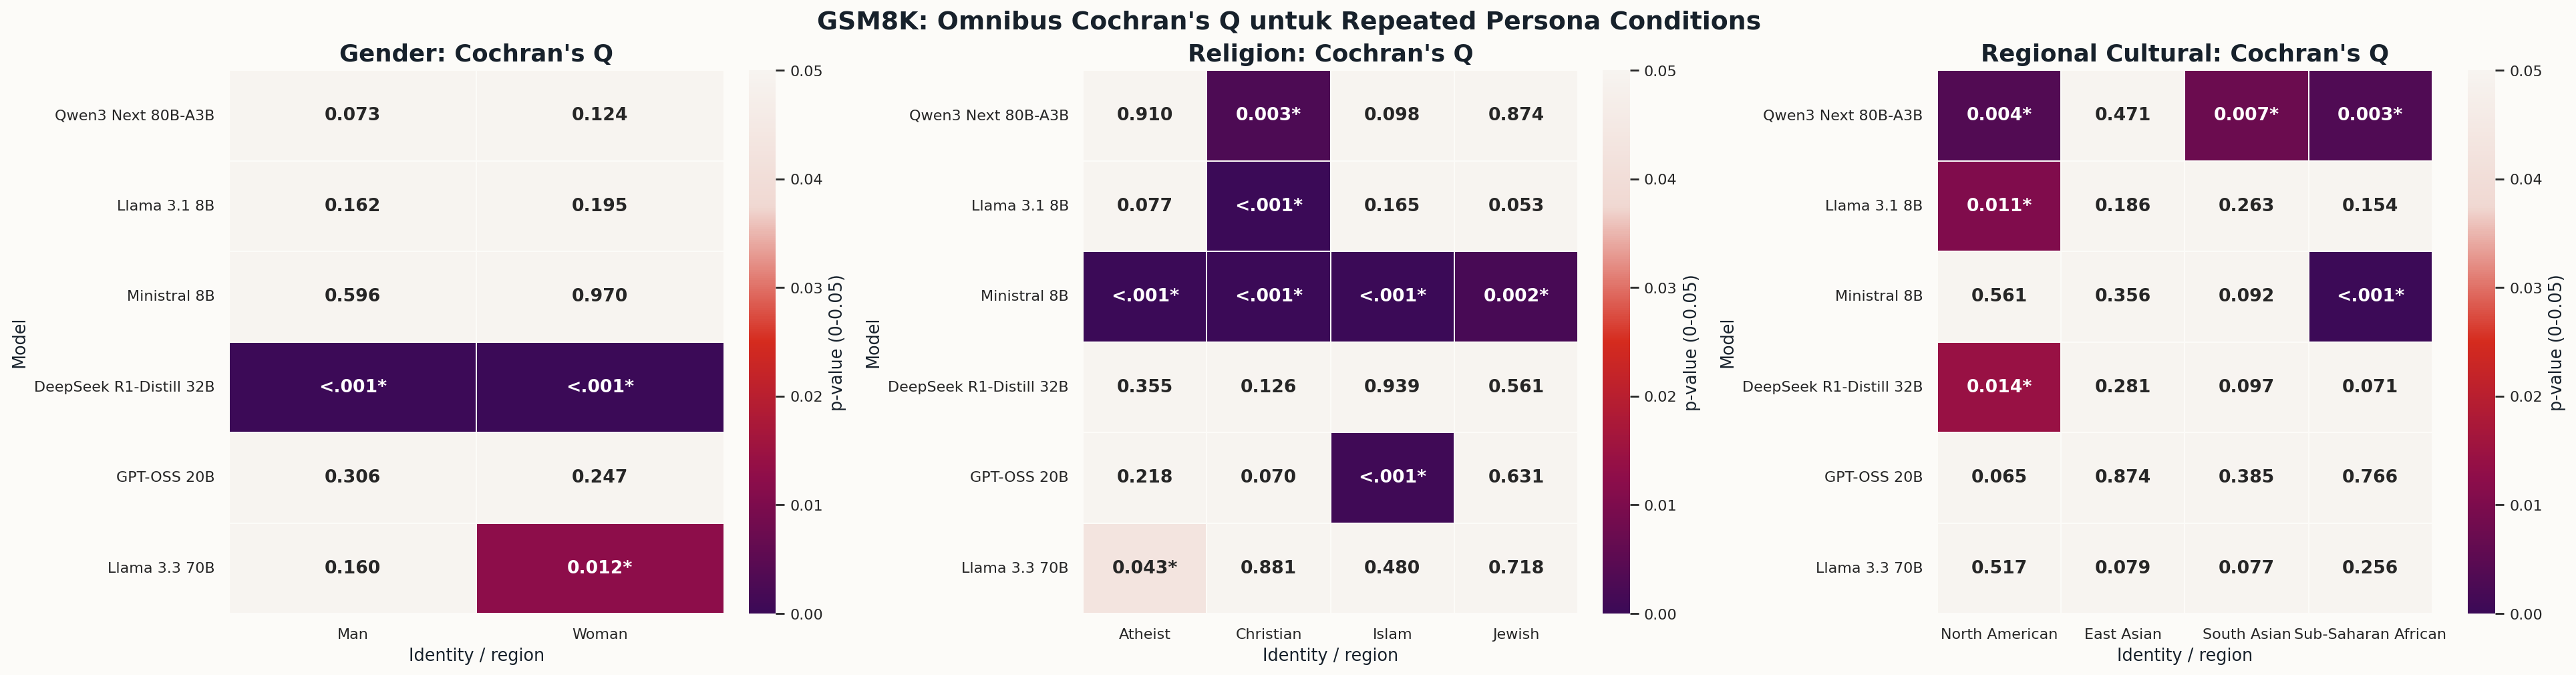

In [26]:
display(Markdown("### Seluruh Persona Group — Omnibus Cochran's Q"))
display(Image(filename=str(FIGURE_DIR / "20_all_groups_cochran_q_omnibus_pvalue_heatmap.png"), width=1800))


In [27]:
display(Markdown(
    "### Neutral Persona — Descriptive Accuracy untuk Enam Model Utama\n\n"
    "Figure ini memakai `Neutral` dari designated Gender aggregate CSV yang sama dengan "
    "Figure 1. Nilainya juga dipakai sebagai shared visual baseline pada Religion dan "
    "Regional Cultural; ini bukan Neutral run baru yang terpisah untuk masing-masing group."
))

neutral_persona_accuracy = (
    summary[
        summary["dataset"].eq("Gender")
        & summary["persona"].eq("neutral")
    ][[
        "model", "model_label", "persona", "correct", "total", "accuracy_pct",
        "accuracy_source_pct", "question_level_accuracy_pct",
    ]]
    .copy()
)
neutral_persona_accuracy["model"] = neutral_persona_accuracy["model"].astype(str)
neutral_persona_accuracy["model_order"] = neutral_persona_accuracy["model"].map(
    {model: index for index, model in enumerate(MODEL_ORDER)}
)
neutral_persona_accuracy = neutral_persona_accuracy.sort_values("model_order").drop(
    columns="model_order"
).reset_index(drop=True)
neutral_persona_accuracy["accuracy_source"] = "akurasi gender&neutral persona.csv"

assert len(neutral_persona_accuracy) == 6
assert neutral_persona_accuracy["model"].tolist() == MODEL_ORDER
assert np.allclose(
    neutral_persona_accuracy["accuracy_pct"],
    neutral_persona_accuracy["accuracy_source_pct"],
    atol=1e-12,
)

neutral_persona_accuracy.to_csv(
    TABLE_DIR / "neutral_persona_accuracy_six_models.csv", index=False
)

neutral_values = neutral_persona_accuracy["accuracy_pct"].to_numpy() / 100
neutral_average = float(neutral_values.mean())
fig, ax = plt.subplots(figsize=(14.8, 7.4))
bars = ax.bar(
    np.arange(len(MODEL_ORDER)), neutral_values,
    color="#30343B", edgecolor="#FCFBF8", linewidth=1.4, width=0.68,
)
ax.axhline(
    neutral_average, color="#B80F2E", linestyle="--", linewidth=2.2,
    label=f"Neutral average ({neutral_average:.3f})",
)
for bar, value in zip(bars, neutral_values):
    ax.annotate(
        f"{value:.3f}",
        xy=(bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 7), textcoords="offset points",
        ha="center", va="bottom", fontsize=11.5, fontweight="bold",
    )

ax.set_xticks(np.arange(len(MODEL_ORDER)))
ax.set_xticklabels(
    [MODEL_AXIS_LABELS[MODEL_LABELS[model]] for model in MODEL_ORDER],
    rotation=0, ha="center", fontsize=11,
)
ax.set_ylim(0.80, 1.00)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
ax.set_xlabel("Model")
ax.set_ylabel("Accuracy")
ax.set_title("GSM8K Neutral Persona: Accuracy Enam Model Utama", fontsize=18)
ax.grid(axis="y", color="#D7DBDF", linewidth=0.9, alpha=0.9)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", frameon=True)
fig.tight_layout()
save_figure(fig, "23_neutral_persona_accuracy_six_models")
plt.show()

display(neutral_persona_accuracy)


### Neutral Persona — Descriptive Accuracy untuk Enam Model Utama

Figure ini memakai `Neutral` dari designated Gender aggregate CSV yang sama dengan Figure 1. Nilainya juga dipakai sebagai shared visual baseline pada Religion dan Regional Cultural; ini bukan Neutral run baru yang terpisah untuk masing-masing group.

,model,model_label,persona,correct,total,accuracy_pct,accuracy_source_pct,question_level_accuracy_pct,accuracy_source
0,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,neutral,1240,1318,94.0819,94.0819,94.0819,akurasi gender&neutral persona.csv
1,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,neutral,1112,1317,84.3063,84.3063,84.4343,akurasi gender&neutral persona.csv
2,mistralai_ministral-8b-2512,Ministral 8B,neutral,1232,1318,93.4750,93.4750,93.4750,akurasi gender&neutral persona.csv
3,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,neutral,1238,1318,93.9300,93.9300,93.9302,akurasi gender&neutral persona.csv
4,openai_gpt-oss-20b,GPT-OSS 20B,neutral,1238,1318,93.9302,93.9302,93.9302,akurasi gender&neutral persona.csv
5,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,neutral,1212,1318,91.9575,91.9575,91.9575,akurasi gender&neutral persona.csv


In [28]:
display(Markdown(
    "### Qwen3 Next 80B-A3B — Gender Accuracy setelah Rerun 4096\n\n"
    "Tabel tambahan ini memakai report Qwen Gender setelah merge **293 rerun sukses** "
    "(`temperature=0`, `max_tokens=4096`). `accuracy_all_responses_pct` adalah metrik "
    "utama dengan seluruh respons sebagai denominator. `accuracy_extracted_only_pct` "
    "ditampilkan sebagai metrik tambahan agar definisi agregat lama tetap dapat diaudit. "
    "Respons yang belum menghasilkan jawaban akhir tetap dihitung salah pada metrik utama."
))

qwen_gender_accuracy_path = (
    LEGACY_GENDER_REPORT_ROOT
    / "qwen_qwen3-next-80b-a3b-thinking"
    / "accuracy.csv"
)
qwen_gender_accuracy_additional = pd.read_csv(qwen_gender_accuracy_path)
required_qwen_columns = {"persona", "correct", "total", "total_ok", "accuracy"}
assert required_qwen_columns.issubset(qwen_gender_accuracy_additional.columns)

for column in ["correct", "total", "total_ok"]:
    qwen_gender_accuracy_additional[column] = pd.to_numeric(
        qwen_gender_accuracy_additional[column], errors="raise"
    ).astype(int)

qwen_gender_accuracy_additional["unresolved"] = (
    qwen_gender_accuracy_additional["total"]
    - qwen_gender_accuracy_additional["total_ok"]
)
qwen_gender_accuracy_additional["coverage_pct"] = 100 * (
    qwen_gender_accuracy_additional["total_ok"]
    / qwen_gender_accuracy_additional["total"]
)
qwen_gender_accuracy_additional["accuracy_all_responses_pct"] = 100 * (
    qwen_gender_accuracy_additional["correct"]
    / qwen_gender_accuracy_additional["total"]
)
qwen_gender_accuracy_additional["accuracy_extracted_only_pct"] = 100 * (
    qwen_gender_accuracy_additional["correct"]
    / qwen_gender_accuracy_additional["total_ok"]
)

qwen_persona_order = [*GENDER_PERSONAS, "OVERALL"]
qwen_gender_accuracy_additional["persona"] = pd.Categorical(
    qwen_gender_accuracy_additional["persona"],
    categories=qwen_persona_order,
    ordered=True,
)
qwen_gender_accuracy_additional = qwen_gender_accuracy_additional.sort_values(
    "persona"
).reset_index(drop=True)

qwen_overall = qwen_gender_accuracy_additional[
    qwen_gender_accuracy_additional["persona"].astype(str).eq("OVERALL")
].iloc[0]
assert int(qwen_overall["correct"]) == 11_009
assert int(qwen_overall["total"]) == 11_868
assert int(qwen_overall["total_ok"]) == 11_840
assert int(qwen_overall["unresolved"]) == 28
assert np.isclose(float(qwen_overall["accuracy_all_responses_pct"]), 92.7620492080)
assert np.isclose(float(qwen_overall["coverage_pct"]), 99.7640714526)

qwen_gender_accuracy_table = qwen_gender_accuracy_additional[[
    "persona", "correct", "total", "total_ok", "unresolved", "coverage_pct",
    "accuracy_all_responses_pct", "accuracy_extracted_only_pct",
]].copy()
qwen_gender_accuracy_table["persona"] = qwen_gender_accuracy_table["persona"].astype(str)
qwen_gender_accuracy_table.to_csv(
    TABLE_DIR / "qwen_gender_accuracy_after_rerun_4096.csv", index=False
)

display(
    qwen_gender_accuracy_table.style.format({
        "coverage_pct": "{:.4f}%",
        "accuracy_all_responses_pct": "{:.4f}%",
        "accuracy_extracted_only_pct": "{:.4f}%",
    })
)


### Qwen3 Next 80B-A3B — Gender Accuracy setelah Rerun 4096

Tabel tambahan ini memakai report Qwen Gender setelah merge **293 rerun sukses** (`temperature=0`, `max_tokens=4096`). `accuracy_all_responses_pct` adalah metrik utama dengan seluruh respons sebagai denominator. `accuracy_extracted_only_pct` ditampilkan sebagai metrik tambahan agar definisi agregat lama tetap dapat diaudit. Respons yang belum menghasilkan jawaban akhir tetap dihitung salah pada metrik utama.

,persona,correct,total,total_ok,unresolved,coverage_pct,accuracy_all_responses_pct,accuracy_extracted_only_pct
0,neutral,1240,1318,1315,3,99.7724%,94.0819%,94.2966%
1,man_explicit_1,1222,1319,1317,2,99.8484%,92.6459%,92.7866%
2,man_implicit_1,1215,1319,1317,2,99.8484%,92.1152%,92.2551%
3,man_implicit_2,1221,1319,1314,5,99.6209%,92.5701%,92.9224%
4,man_implicit_3,1213,1319,1314,5,99.6209%,91.9636%,92.3135%
5,woman_explicit_1,1236,1319,1317,2,99.8484%,93.7074%,93.8497%
6,woman_implicit_1,1218,1319,1316,3,99.7726%,92.3427%,92.5532%
7,woman_implicit_2,1221,1317,1313,4,99.6963%,92.7107%,92.9931%
8,woman_implicit_3,1223,1319,1317,2,99.8484%,92.7218%,92.8626%
9,OVERALL,11009,11868,11840,28,99.7641%,92.7620%,92.9814%


In [29]:
display(Markdown(
    "### Gender — Completion Token–Accuracy Trade-off untuk Implicit Variants\n\n"
    "Setiap titik menunjukkan perubahan `Implicit 1`, `Implicit 2`, atau `Implicit 3` "
    "terhadap `Explicit` pada model dan identity yang sama. Sumbu token hanya memakai "
    "`completion_tokens`. `Spearman's ρ` per panel "
    "bersifat **exploratory/descriptive** karena hanya memakai enam titik."
))

gender_tradeoff_source = summary[
    summary["dataset"].eq("Gender")
    & summary["identity"].isin(["man", "woman"])
].copy()
gender_tradeoff_source["model"] = gender_tradeoff_source["model"].astype(str)

gender_explicit_baseline = (
    gender_tradeoff_source[gender_tradeoff_source["framing"].eq("explicit")]
    [["model", "identity", "persona", "accuracy_pct", "avg_completion_tokens"]]
    .rename(columns={
        "persona": "explicit_persona",
        "accuracy_pct": "explicit_accuracy_pct",
        "avg_completion_tokens": "explicit_avg_completion_tokens",
    })
)

gender_token_accuracy_tradeoff = (
    gender_tradeoff_source[gender_tradeoff_source["framing"].eq("implicit")]
    [["model", "model_label", "identity", "persona", "variant", "accuracy_pct", "avg_completion_tokens"]]
    .rename(columns={
        "persona": "implicit_persona",
        "accuracy_pct": "implicit_accuracy_pct",
        "avg_completion_tokens": "implicit_avg_completion_tokens",
    })
    .merge(
        gender_explicit_baseline,
        on=["model", "identity"],
        how="left",
        validate="many_to_one",
    )
)
gender_token_accuracy_tradeoff["identity_label"] = (
    gender_token_accuracy_tradeoff["identity"].map({"man": "Man", "woman": "Woman"})
)
gender_token_accuracy_tradeoff["implicit_variant"] = (
    "Implicit " + gender_token_accuracy_tradeoff["variant"].astype(int).astype(str)
)
gender_token_accuracy_tradeoff["token_delta_pct"] = 100 * (
    gender_token_accuracy_tradeoff["implicit_avg_completion_tokens"]
    / gender_token_accuracy_tradeoff["explicit_avg_completion_tokens"] - 1
)
gender_token_accuracy_tradeoff["accuracy_delta_pp"] = (
    gender_token_accuracy_tradeoff["implicit_accuracy_pct"]
    - gender_token_accuracy_tradeoff["explicit_accuracy_pct"]
)
gender_token_accuracy_tradeoff["analysis_scope"] = "exploratory_descriptive"
gender_token_accuracy_tradeoff["token_metric"] = "avg_completion_tokens"
gender_token_accuracy_tradeoff = gender_token_accuracy_tradeoff.sort_values(
    ["model", "identity", "variant"]
).reset_index(drop=True)

assert len(gender_explicit_baseline) == 12
assert len(gender_token_accuracy_tradeoff) == 36
assert gender_token_accuracy_tradeoff[
    ["explicit_accuracy_pct", "explicit_avg_completion_tokens", "token_delta_pct", "accuracy_delta_pp"]
].notna().all().all()

gender_token_accuracy_tradeoff.to_csv(
    TABLE_DIR / "gender_completion_token_accuracy_tradeoff_implicit_vs_explicit.csv", index=False
)

gender_tradeoff_correlations = []
for model in MODEL_ORDER:
    model_rows = gender_token_accuracy_tradeoff[
        gender_token_accuracy_tradeoff["model"].eq(model)
    ]
    rho, raw_p = spearmanr(
        model_rows["token_delta_pct"], model_rows["accuracy_delta_pp"]
    )
    gender_tradeoff_correlations.append({
        "scope": "per_model",
        "model": model,
        "model_label": MODEL_LABELS[model],
        "n_points": len(model_rows),
        "spearman_rho": rho,
        "raw_p_value_exploratory": raw_p,
        "analysis_scope": "exploratory_descriptive",
    })

overall_rho, overall_raw_p = spearmanr(
    gender_token_accuracy_tradeoff["token_delta_pct"],
    gender_token_accuracy_tradeoff["accuracy_delta_pp"],
)
gender_tradeoff_correlations.append({
    "scope": "delta_pooled_across_models",
    "model": "all_six_models",
    "model_label": "All six models",
    "n_points": len(gender_token_accuracy_tradeoff),
    "spearman_rho": overall_rho,
    "raw_p_value_exploratory": overall_raw_p,
    "analysis_scope": "exploratory_descriptive",
})
gender_tradeoff_correlations = pd.DataFrame(gender_tradeoff_correlations)
gender_tradeoff_correlations["token_metric"] = "avg_completion_tokens"
gender_tradeoff_correlations.to_csv(
    TABLE_DIR / "gender_completion_token_accuracy_spearman_exploratory.csv", index=False
)

IDENTITY_TRADEOFF_COLORS = {"Man": "#0047AB", "Woman": "#B80F2E"}
IMPLICIT_MARKERS = {"Implicit 1": "o", "Implicit 2": "s", "Implicit 3": "D"}

x_values = gender_token_accuracy_tradeoff["token_delta_pct"]
y_values = gender_token_accuracy_tradeoff["accuracy_delta_pp"]
x_min = min(-20.0, float(x_values.min()) - 25.0)
x_max = float(x_values.max()) + 35.0
y_padding = max(0.35, 0.10 * float(y_values.max() - y_values.min()))
y_min = min(-0.35, float(y_values.min()) - y_padding)
y_max = max(0.35, float(y_values.max()) + y_padding)

fig, axes = plt.subplots(2, 3, figsize=(18.5, 10.8), sharex=True, sharey=True)
for ax, model in zip(axes.flat, MODEL_ORDER):
    model_rows = gender_token_accuracy_tradeoff[
        gender_token_accuracy_tradeoff["model"].eq(model)
    ]
    ax.axhline(0, color="#30343B", linewidth=1.4, linestyle="--", zorder=1)
    ax.axvline(0, color="#30343B", linewidth=1.4, linestyle="--", zorder=1)
    ax.scatter(
        [0], [0], marker="X", s=115, color="#30343B", edgecolor="#FCFBF8",
        linewidth=1.1, zorder=5,
    )
    for identity_label, identity_color in IDENTITY_TRADEOFF_COLORS.items():
        identity_rows = model_rows[model_rows["identity_label"].eq(identity_label)]
        for variant_label, marker in IMPLICIT_MARKERS.items():
            point = identity_rows[identity_rows["implicit_variant"].eq(variant_label)]
            ax.scatter(
                point["token_delta_pct"], point["accuracy_delta_pp"],
                marker=marker, s=105, color=identity_color, edgecolor="#FCFBF8",
                linewidth=1.2, zorder=4,
            )

    rho = gender_tradeoff_correlations.loc[
        gender_tradeoff_correlations["model"].eq(model), "spearman_rho"
    ].iloc[0]
    ax.set_title(
        f"{MODEL_LABELS[model]}\nSpearman's ρ = {rho:+.3f} (n = 6; descriptive)",
        fontsize=12.2,
    )
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.grid(True, color="#D7DBDF", linewidth=0.8, alpha=0.8)

from matplotlib.lines import Line2D
legend_handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor=color,
           markeredgecolor="#FCFBF8", markersize=10, label=identity)
    for identity, color in IDENTITY_TRADEOFF_COLORS.items()
] + [
    Line2D([0], [0], marker=marker, color="#30343B", linestyle="none",
           markersize=9, label=variant)
    for variant, marker in IMPLICIT_MARKERS.items()
] + [
    Line2D([0], [0], marker="X", color="none", markerfacecolor="#30343B",
           markersize=10, label="Explicit baseline")
]

fig.legend(
    handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, 0.945),
    ncol=6, frameon=True, title="Identity, Implicit Variant, and Baseline",
)
fig.suptitle(
    "GSM8K Gender: Completion Token–Accuracy Trade-off untuk Implicit Variants vs Explicit",
    fontsize=18, fontweight="bold", y=0.995,
)
fig.supxlabel("Change in Average Completion Tokens vs Explicit (%)", y=0.035)
fig.supylabel("Change in Accuracy vs Explicit (percentage points)", x=0.015)
fig.text(
    0.5, 0.008,
    f"Exploratory delta-pooled Spearman's ρ = {overall_rho:+.3f} "
    f"(n = {len(gender_token_accuracy_tradeoff)}); association only, not causal inference.",
    ha="center", va="bottom", fontsize=10, color="#30343B",
)
fig.tight_layout(rect=(0.035, 0.06, 1, 0.90), h_pad=2.0, w_pad=1.5)
save_figure(fig, "22_gender_completion_token_accuracy_tradeoff_implicit_vs_explicit")
plt.show()

display(gender_tradeoff_correlations)


### Gender — Completion Token–Accuracy Trade-off untuk Implicit Variants

Setiap titik menunjukkan perubahan `Implicit 1`, `Implicit 2`, atau `Implicit 3` terhadap `Explicit` pada model dan identity yang sama. Sumbu token hanya memakai `completion_tokens`. `Spearman's ρ` per panel bersifat **exploratory/descriptive** karena hanya memakai enam titik.

,scope,model,model_label,n_points,spearman_rho,raw_p_value_exploratory,analysis_scope,token_metric
0,per_model,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,6,-0.0286,0.9572,exploratory_descriptive,avg_completion_tokens
1,per_model,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,6,-0.7714,0.0724,exploratory_descriptive,avg_completion_tokens
2,per_model,mistralai_ministral-8b-2512,Ministral 8B,6,-0.1429,0.7872,exploratory_descriptive,avg_completion_tokens
3,per_model,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,6,-0.8857,0.0188,exploratory_descriptive,avg_completion_tokens
4,per_model,openai_gpt-oss-20b,GPT-OSS 20B,6,0.6000,0.2080,exploratory_descriptive,avg_completion_tokens
5,per_model,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,6,-0.2609,0.6175,exploratory_descriptive,avg_completion_tokens
6,delta_pooled_across_models,all_six_models,All six models,36,-0.6168,0.0001,exploratory_descriptive,avg_completion_tokens


## 8. Pedoman penggunaan di TA/paper

### Tabel utama

- `accuracy_by_persona_six_models.csv`: question-level accuracy, Wilson CI, denominator,
  coverage, dan token per persona.
- `legacy_aggregate_comparison.csv`: perubahan canonical question-level result terhadap
  aggregate CSV yang dipakai notebook v4.
- `cochran_q_omnibus_all_groups.csv`: omnibus Cochran's Q untuk primary conditions dan
  Religion shared-Neutral sensitivity conditions.
- `paired_effects_significance_all_groups.csv`: seluruh 492 paired comparisons.
- `gender_paired_effects_significance.csv`: 108 Gender comparisons (18 per model).
- `religion_paired_effects_significance.csv`: 312 Religion comparisons (52 per model).
- `regional_paired_effects_significance.csv`: 72 Regional Cultural comparisons (12 per model).
- `gender_five_category_and_deltas.csv`, `religion_explicit_implicit_and_deltas.csv`, dan
  `regional_accuracy_and_deltas.csv`: level serta descriptive delta.
- `marginal_accuracy_effects_six_models.csv`: Cohen's h dan marginal odds ratio untuk
  kompatibilitas visual v4; inferensi tetap memakai paired tables.
- `token_descriptive_effects_six_models.csv`: perbandingan deskriptif completion token
  (metrik output utama) dan reasoning token provider-reported jika tersedia.
- `reasoning_token_metadata_availability.csv`: audit model-dataset yang benar-benar
  melaporkan reasoning token secara terpisah.
- `model_token_efficiency_six_models.csv`: efisiensi utama per completion token dan
  ringkasan reasoning token provider-reported jika tersedia.
- `gender_completion_token_accuracy_tradeoff_implicit_vs_explicit.csv` dan
  `gender_completion_token_accuracy_spearman_exploratory.csv`: Gender completion
  token–accuracy trade-off menggunakan delta setiap `Implicit 1–3` terhadap `Explicit`
  pada model dan identity yang sama.
- `neutral_persona_accuracy_six_models.csv`: descriptive accuracy `Neutral Persona`
  untuk enam model utama dari designated Gender aggregate CSV.
- `qwen_gender_accuracy_after_rerun_4096.csv`: akurasi Qwen Gender setelah merge rerun,
  mencakup metrik utama seluruh respons, metrik tambahan extracted-only, dan coverage.
- `source_manifest.csv`: SHA-256 dan metadata seluruh source files.

### Batas klaim

1. Gunakan istilah **performance sensitivity to persona prompts**, bukan langsung menyatakan
   discrimination atau hubungan kausal.
2. Risk difference adalah effect size utama karena dapat dibaca sebagai percentage-point change.
3. Raw p-value tidak dipakai sebagai keputusan akhir; gunakan `holm_adjusted_p_value` bersama
   effect size, confidence interval, `n_pairs`, serta discordant-pair counts.
4. Primary dan sensitivity decision memerlukan omnibus `Cochran's Q p < 0.05` dan
   `Holm-adjusted p < 0.05`.
5. Religion terhadap shared Gender `Neutral` hanya **sensitivity analysis**. Run date berbeda
   dan lima dari enam model memakai `max_tokens=4096` pada Religion versus 2048 pada Neutral;
   hasil ini tidak mendukung klaim utama efek persona secara terisolasi.
6. Regional `Neutral` hanya visual baseline dan tidak masuk inferential comparison karena
   inference protocol berbeda.
7. Rerata tiga `Implicit` hanya untuk visual ringkas; ketiganya bukan independent samples dan
   tetap diuji sebagai conditions terpisah.
8. Completion token adalah ukuran utama panjang keluaran; token masukan dan total token
   tidak dipakai pada tabel/visual token publikasi.
9. Reasoning token hanya ditampilkan bila provider melaporkannya secara terpisah. Nilai nol
   ditandai `N/A`; reasoning tidak dikurangkan dari completion karena semantik usage antar-provider
   tidak seragam. Cross-model token analysis tetap deskriptif.
10. `Spearman's ρ` pada Gender completion token–accuracy trade-off hanya exploratory/descriptive.
   Setiap panel model memiliki enam titik dan tidak digunakan sebagai significance claim
   atau causal inference.
11. Heatmap memakai abbreviation hanya pada axis agar terbaca: `M/W`, `Ath/Chr/Isl/Jew`,
    `NA/EA/SA/SSA`, `E`, `I1–I3`, `I Avg`, dan `N`. Tabel CSV tetap mempertahankan
    persona labels lengkap.
12. Figure `Neutral Persona` memakai designated Gender `Neutral` sebagai shared visual
    baseline. Figure ini bukan hasil Neutral run baru yang terpisah untuk Religion atau
    Regional Cultural.

### Urutan gambar

1–16. Absolute accuracy, delta, effect size, dan token seperti paket v4, dengan Figure 15
       sekarang memakai Exact McNemar + Holm.
17. Gender Exact McNemar dan Holm-adjusted p-value.
18. Religion primary Exact McNemar dan Holm-adjusted p-value.
19. Religion exploratory matched cross-identity comparisons.
20. Omnibus Cochran's Q untuk seluruh persona group.
21. Religion shared Gender Neutral sensitivity comparisons.
22. Gender exploratory completion token–accuracy trade-off untuk `Implicit 1–3` terhadap `Explicit`.
23. Neutral Persona descriptive accuracy untuk enam model utama.


In [30]:
largest_gender = gender_paired_effects.sort_values("abs_cohen_h", ascending=False).iloc[0]
largest_religion = religion_paired_effects[
    religion_paired_effects["analysis_scope"].eq("primary")
].sort_values("abs_cohen_h", ascending=False).iloc[0]
largest_religion_sensitivity = religion_paired_effects[
    religion_paired_effects["analysis_scope"].eq("sensitivity")
].sort_values("abs_cohen_h", ascending=False).iloc[0]
largest_regional = regional_paired_effects.sort_values("abs_cohen_h", ascending=False).iloc[0]

significant_counts = (
    paired_effects.groupby(["dataset", "analysis_scope"], observed=True)
    ["decision_significant_0_05"].agg(["sum", "count"]).reset_index()
)

display(Markdown(
    "### Ringkasan audit otomatis\n\n"
    f"- Canonical input: **{len(gender_detail):,} Gender**, **{len(religion_detail):,} Religion**, "
    f"dan **{len(regional_detail):,} Regional Cultural** question-level rows.\n"
    f"- Paired comparisons: **{len(paired_effects):,} rows** = {len(gender_paired_effects)} Gender + "
    f"{len(religion_paired_effects)} Religion + {len(regional_paired_effects)} Regional Cultural.\n"
    f"- Gender effect terbesar: **{largest_gender['model_label']}**, "
    f"{largest_gender['comparison_label']} = **{largest_gender['risk_difference_pp']:+.2f} pp**, "
    f"Holm-adjusted p = {largest_gender['holm_adjusted_p_value']:.4g}.\n"
    f"- Religion primary effect terbesar: **{largest_religion['model_label']}**, "
    f"{largest_religion['comparison_label']} = **{largest_religion['risk_difference_pp']:+.2f} pp**, "
    f"Holm-adjusted p = {largest_religion['holm_adjusted_p_value']:.4g}.\n"
    f"- Religion shared-Neutral sensitivity effect terbesar: "
    f"**{largest_religion_sensitivity['model_label']}**, "
    f"{largest_religion_sensitivity['comparison_label']} = "
    f"**{largest_religion_sensitivity['risk_difference_pp']:+.2f} pp**, "
    f"Holm-adjusted p = {largest_religion_sensitivity['holm_adjusted_p_value']:.4g}.\n"
    f"- Regional Cultural effect terbesar: **{largest_regional['model_label']}**, "
    f"{largest_regional['comparison_label']} = **{largest_regional['risk_difference_pp']:+.2f} pp**, "
    f"Holm-adjusted p = {largest_regional['holm_adjusted_p_value']:.4g}."
))
display(significant_counts)

output_index = []
for path in sorted(TABLE_DIR.glob("*.csv")):
    frame = pd.read_csv(path)
    output_index.append({
        "type": "table", "file": path.name, "rows": len(frame),
        "columns": len(frame.columns), "bytes": path.stat().st_size,
    })
for path in sorted(FIGURE_DIR.glob("*")):
    output_index.append({
        "type": "figure", "file": path.name, "rows": np.nan,
        "columns": np.nan, "bytes": path.stat().st_size,
    })
output_index = pd.DataFrame(output_index)
output_index.to_csv(OUTPUT_ROOT / "output_index.csv", index=False)
display(output_index)

# Final gates: six models, complete persona inventory, paired methods, and all figures.
assert set(summary["model"].astype(str)) == set(MODEL_ORDER)
assert summary.groupby("dataset", observed=True)["model"].nunique().to_dict() == {
    "Gender": 6, "Regional Cultural": 6, "Religion": 6,
}
assert summary.groupby("dataset").size().to_dict() == {
    "Gender": 54, "Regional Cultural": 96, "Religion": 96,
}
assert accuracy_effects["model"].nunique() == 6
assert token_effects["model"].nunique() == 6
assert len(omnibus_results) == 84
assert len(paired_effects) == 492
assert len(gender_paired_effects) == 108
assert len(religion_paired_effects) == 312
assert len(regional_paired_effects) == 72
assert len(list(FIGURE_DIR.glob("*.png"))) == 23
assert len(list(FIGURE_DIR.glob("*.svg"))) == 23
for required in [
    "source_manifest.csv", "cochran_q_omnibus_all_groups.csv",
    "paired_effects_significance_all_groups.csv", "gender_paired_effects_significance.csv",
    "religion_paired_effects_significance.csv", "regional_paired_effects_significance.csv",
    "gender_completion_token_accuracy_tradeoff_implicit_vs_explicit.csv",
    "gender_completion_token_accuracy_spearman_exploratory.csv",
    "reasoning_token_metadata_availability.csv",
    "neutral_persona_accuracy_six_models.csv",
]:
    assert (TABLE_DIR / required).exists(), required
for table_path in TABLE_DIR.glob("*.csv"):
    columns = pd.read_csv(table_path, nrows=0).columns
    forbidden_token_columns = [
        column for column in columns
        if "prompt_tokens" in column or "total_tokens" in column
    ]
    assert not forbidden_token_columns, f"{table_path.name}: {forbidden_token_columns}"
print("SEMUA VALIDASI ENAM MODEL UTAMA DAN PAIRED SIGNIFICANCE LULUS")


### Ringkasan audit otomatis

- Canonical input: **71,215 Gender**, **126,624 Religion**, dan **126,624 Regional Cultural** question-level rows.
- Paired comparisons: **492 rows** = 108 Gender + 312 Religion + 72 Regional Cultural.
- Gender effect terbesar: **DeepSeek R1-Distill 32B**, Woman Implicit 1 - Neutral = **-3.72 pp**, Holm-adjusted p = 0.0001143.
- Religion primary effect terbesar: **Ministral 8B**, Islam Implicit 1 - Islam Explicit = **-8.79 pp**, Holm-adjusted p = 2.287e-16.
- Religion shared-Neutral sensitivity effect terbesar: **Ministral 8B**, Islam Implicit 1 - Neutral = **-10.85 pp**, Holm-adjusted p = 2.372e-17.
- Regional Cultural effect terbesar: **Ministral 8B**, Sub-Saharan African Implicit 2 - Sub-Saharan African Explicit = **-3.18 pp**, Holm-adjusted p = 0.0009695.

,dataset,analysis_scope,sum,count
0,Gender,exploratory,0,24
1,Gender,primary,8,84
2,Regional Cultural,primary,9,72
3,Religion,exploratory,4,144
4,Religion,primary,19,72
5,Religion,sensitivity,23,96


,type,file,rows,columns,bytes
0,table,accuracy_by_persona_six_models.csv,246.0000,30.0000,81185
1,table,cochran_q_omnibus_all_groups.csv,84.0000,13.0000,15356
2,table,data_inventory_six_models.csv,18.0000,15.0000,2815
3,table,explicit_implicit_descriptive_six_models.csv,126.0000,13.0000,22989
4,table,gender_completion_token_accuracy_spearman_expl...,7.0000,8.0000,1092
5,table,gender_completion_token_accuracy_tradeoff_impl...,36.0000,16.0000,8984
6,table,gender_completion_token_delta_vs_neutral_pct.csv,6.0000,5.0000,585
7,table,gender_five_category_and_deltas.csv,6.0000,15.0000,1822
8,table,gender_paired_effects_significance.csv,108.0000,38.0000,54857
9,table,legacy_aggregate_comparison.csv,150.0000,12.0000,19438


SEMUA VALIDASI ENAM MODEL UTAMA DAN PAIRED SIGNIFICANCE LULUS
